# 1. Data Cleaning and Auditing

The Formula 1 dataset consists of 14 relational CSV tables. Before constructing the
modeling dataset, the raw data is explored and audited to identify missing values,
incorrect data types, duplicate records, and relational-integrity problems.

The cleaning process includes:
- exploratory data analysis before cleaning;
- detection and cleaning of `\N` sentinel values;
- semantic typing of dates and durations;
- primary-key and foreign-key validation;
- investigation and resolution of duplicate `(raceId, driverId)` records;
- and exploratory analysis after cleaning.

The original DataFrames are preserved unchanged. All cleaning operations are
performed on separate copies.

In [90]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import os

In [91]:
DATA_PATH = "/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020"

file_names = [
    "circuits",
    "constructors",
    "constructor_results",
    "constructor_standings",
    "drivers",
    "driver_standings",
    "races",
    "results",
    "qualifying",
    "lap_times",
    "pit_stops",
    "sprint_results",
    "seasons",
    "status"
]

raw_data = {}

for name in file_names:
    raw_data[name] = pd.read_csv(
        f"{DATA_PATH}/{name}.csv"
    )

print("Number of tables loaded:", len(raw_data))

Number of tables loaded: 14


## 1.1 Initial Exploratory Data Analysis

The raw tables are first explored without modification. Their dimensions, data types,
summary statistics, missing values, duplicate rows, and placeholder values are
examined programmatically.

This provides a baseline for identifying cleaning requirements and allows the effect
of cleaning to be evaluated later.

In [92]:
for name, df in raw_data.items():
    print(f"\n{name.upper()}")
    display(df.head())


CIRCUITS


,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130,http://en.wikipedia.org/wiki/Istanbul_Park



CONSTRUCTORS


,constructorId,constructorRef,name,nationality,url
0,1,mclaren,McLaren,British,http://en.wikipedia.org/wiki/McLaren
1,2,bmw_sauber,BMW Sauber,German,http://en.wikipedia.org/wiki/BMW_Sauber
2,3,williams,Williams,British,http://en.wikipedia.org/wiki/Williams_Grand_Pr...
3,4,renault,Renault,French,http://en.wikipedia.org/wiki/Renault_in_Formul...
4,5,toro_rosso,Toro Rosso,Italian,http://en.wikipedia.org/wiki/Scuderia_Toro_Rosso



CONSTRUCTOR_RESULTS


...

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1,1,1,3,17,25:38.426,1538426,14,1:30.013,1
1,2,1061,1,131,44,1,2,2,2,2,17,+1.430,1539856,17,1:29.937,1
2,3,1061,822,131,77,3,3,3,3,1,17,+7.502,1545928,17,1:29.958,1
3,4,1061,844,6,16,4,4,4,4,0,17,+11.278,1549704,16,1:30.163,1
4,5,1061,846,1,4,6,5,5,5,0,17,+24.111,1562537,16,1:30.566,1



SEASONS


,year,url
0,2009,http://en.wikipedia.org/wiki/2009_Formula_One_...
1,2008,http://en.wikipedia.org/wiki/2008_Formula_One_...
2,2007,http://en.wikipedia.org/wiki/2007_Formula_One_...
3,2006,http://en.wikipedia.org/wiki/2006_Formula_One_...
4,2005,http://en.wikipedia.org/wiki/2005_Formula_One_...



STATUS


,statusId,status
0,1,Finished
1,2,Disqualified
2,3,Accident
3,4,Collision
4,5,Engine


In [93]:
overview = []

for name, df in raw_data.items():
    overview.append({
        "Table": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1]
    })

overview_df = pd.DataFrame(overview)

display(overview_df)

,Table,Rows,Columns
0,circuits,77,9
1,constructors,212,5
2,constructor_results,12625,5
3,constructor_standings,13391,7
4,drivers,861,9
5,driver_standings,34863,7
6,races,1125,18
7,results,26759,18
8,qualifying,10494,9
9,lap_times,589081,6


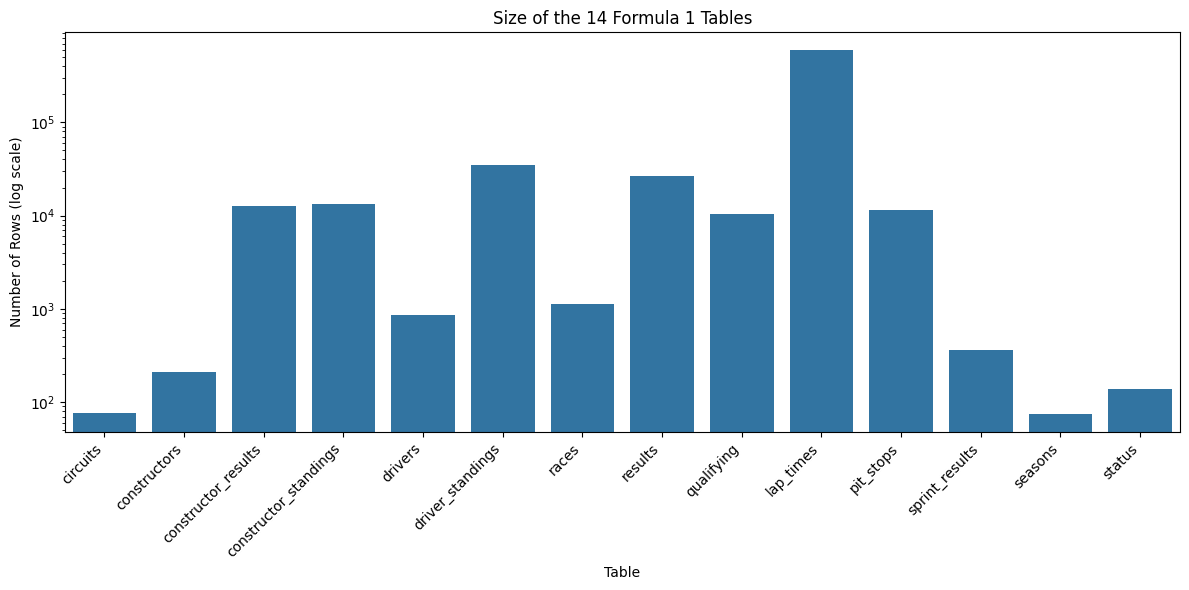

In [94]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=overview_df,
    x="Table",
    y="Rows"
)

plt.yscale("log")
plt.title("Size of the 14 Formula 1 Tables")
plt.xlabel("Table")
plt.ylabel("Number of Rows (log scale)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [95]:
for name, df in raw_data.items():
    print("\n" + "=" * 70)
    print(name.upper())
    print("=" * 70)

    df.info()


CIRCUITS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB

CONSTRUCTORS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 212 entries, 0 to 211
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   constructorId   212 non-null    int64 
 1   constructorRef  212 non-null    object
 2   name            212 non-null    object
 3   nationality     212 non-null    

In [96]:
for name, df in raw_data.items():
    print("\n" + "=" * 70)
    print(name.upper())
    print("=" * 70)

    display(df.describe())


CIRCUITS


,circuitId,lat,lng,alt
count,77.000000,77.000000,77.000000,77.000000
mean,39.883117,33.442925,1.076683,247.012987
std,23.001701,22.808866,65.516951,362.738469
min,1.000000,-37.849700,-118.189000,-7.000000
25%,20.000000,32.777400,-9.394170,18.000000
50%,40.000000,40.951700,3.930830,129.000000
75%,59.000000,46.958900,19.248600,332.000000
max,80.000000,57.265300,144.968000,2227.000000



CONSTRUCTORS


,constructorId
count,212.000000
mean,107.547170
std,61.952685
min,1.000000
25%,54.750000
50%,107.500000
75%,160.250000
max,215.000000



CONSTRUCTOR_RESULTS


...

,resultId,raceId,driverId,constructorId,number,grid,positionOrder,points,laps,statusId
count,360.000000,360.000000,360.000000,360.000000,360.000000,360.000000,360.000000,360.000000,360.000000,360.000000
mean,180.500000,1106.944444,734.658333,94.366667,28.177778,9.922222,10.500000,1.550000,19.583333,3.336111
std,104.067286,25.636134,276.412115,89.166421,23.796293,5.842363,5.774307,2.496293,4.752803,13.447963
min,1.000000,1061.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000
25%,90.750000,1084.000000,822.000000,6.000000,11.000000,5.000000,5.750000,0.000000,18.000000,1.000000
50%,180.500000,1112.500000,840.000000,84.000000,22.000000,10.000000,10.500000,0.000000,19.000000,1.000000
75%,270.250000,1126.000000,848.000000,210.000000,44.000000,15.000000,15.250000,3.000000,24.000000,1.000000
max,360.000000,1143.000000,861.000000,215.000000,99.000000,20.000000,20.000000,8.000000,24.000000,130.000000



SEASONS


,year
count,75.000000
mean,1987.000000
std,21.794495
min,1950.000000
25%,1968.500000
50%,1987.000000
75%,2005.500000
max,2024.000000



STATUS


,statusId
count,139.000000
mean,71.237410
std,41.092434
min,1.000000
25%,35.500000
50%,72.000000
75%,106.500000
max,141.000000


### Initial Data Observations

The initial inspection shows that the 14 tables vary substantially in size, with
`lap_times` being the largest table.

Several fields also require semantic type conversion. Date variables such as
`races.date` and `drivers.dob` are currently stored as `object`, while duration
variables such as qualifying lap times and pit-stop durations are also stored as text.

The numerical summaries show large ranges in some duration-related variables,
particularly lap times and pit-stop durations. These values are noted for further
inspection rather than treated as errors at this stage.

The next steps examine duplicate records and missing values before any cleaning is
applied.

In [97]:
duplicate_summary = []

for name, df in raw_data.items():
    duplicate_summary.append({
        "Table": name,
        "Exact_Duplicate_Rows": df.duplicated().sum()
    })

duplicate_summary = pd.DataFrame(duplicate_summary)

display(duplicate_summary)

,Table,Exact_Duplicate_Rows
0,circuits,0
1,constructors,0
2,constructor_results,0
3,constructor_standings,0
4,drivers,0
5,driver_standings,0
6,races,0
7,results,0
8,qualifying,0
9,lap_times,0


## 1.2 Sentinel and Missing-Value Analysis

The Formula 1 CSV files use the literal string `\N` as a sentinel representing
missing or unavailable information.

Because `\N` is a text placeholder rather than a proper missing value, its frequency
is measured before cleaning. Both the number and percentage of sentinel values are
calculated for each affected column and visualized before any replacement is made.

In [98]:
sentinel_summary = []

for table_name, df in raw_data.items():
    for column in df.columns:

        count = (
            df[column]
            .astype(str)
            .str.strip()
            .eq(r"\N")
            .sum()
        )

        if count > 0:
            sentinel_summary.append({
                "Table": table_name,
                "Column": column,
                "Count": count,
                "Percentage": count / len(df) * 100
            })

sentinel_summary = pd.DataFrame(sentinel_summary)

sentinel_summary = sentinel_summary.sort_values(
    "Percentage",
    ascending=False
).reset_index(drop=True)

display(sentinel_summary)

,Table,Column,Count,Percentage
0,constructor_results,status,12608,99.865347
1,races,sprint_time,1110,98.666667
2,races,sprint_date,1107,98.400000
3,races,fp3_time,1072,95.288889
4,races,fp2_time,1057,93.955556
5,races,fp1_time,1057,93.955556
6,races,quali_time,1057,93.955556
7,races,fp3_date,1053,93.600000
8,drivers,number,802,93.147503
9,races,fp1_date,1035,92.000000


### Total Missingness Before Cleaning

The previous analysis counts only the literal `\N` sentinel values. Some columns also
contain values that Pandas already recognizes as missing (`NaN`).

Therefore, total missingness is calculated using both existing null values and `\N`
sentinels to obtain the complete missing-data picture before cleaning.

In [99]:
missing_before = []

for table_name, df in raw_data.items():
    for column in df.columns:

        null_count = df[column].isnull().sum()

        sentinel_count = (
            df[column]
            .astype(str)
            .str.strip()
            .eq(r"\N")
            .sum()
        )

        total_missing = null_count + sentinel_count

        if total_missing > 0:
            missing_before.append({
                "Table": table_name,
                "Column": column,
                "Missing_Count": total_missing,
                "Missing_Percentage": total_missing / len(df) * 100
            })

missing_before = pd.DataFrame(missing_before)

missing_before = missing_before.sort_values(
    "Missing_Percentage",
    ascending=False
).reset_index(drop=True)

display(missing_before.head(30))

,Table,Column,Missing_Count,Missing_Percentage
0,constructor_results,status,12608,99.865347
1,races,sprint_time,1110,98.666667
2,races,sprint_date,1107,98.400000
3,races,fp3_time,1072,95.288889
4,races,fp2_time,1057,93.955556
5,races,fp1_time,1057,93.955556
6,races,quali_time,1057,93.955556
7,races,fp3_date,1053,93.600000
8,drivers,number,802,93.147503
9,races,fp1_date,1035,92.000000


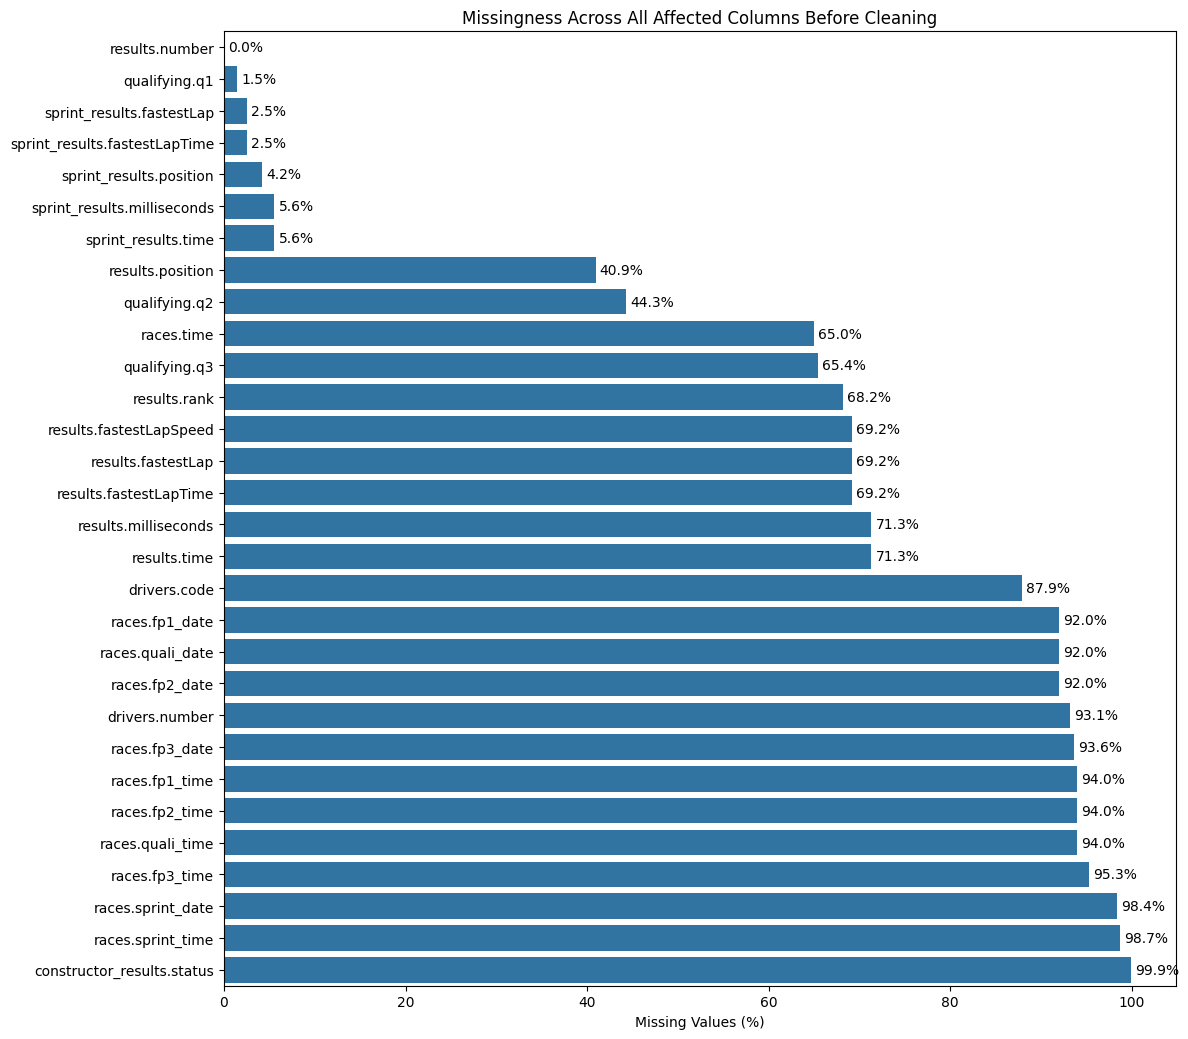

In [100]:
missing_before_plot = (
    missing_before
    .sort_values(
        "Missing_Percentage",
        ascending=True
    )
    .copy()
)

missing_before_plot["Feature"] = (
    missing_before_plot["Table"]
    + "."
    + missing_before_plot["Column"]
)

plt.figure(
    figsize=(
        12,
        max(6, len(missing_before_plot) * 0.35)
    )
)

ax = sns.barplot(
    data=missing_before_plot,
    x="Missing_Percentage",
    y="Feature"
)

plt.title("Missingness Across All Affected Columns Before Cleaning")
plt.xlabel("Missing Values (%)")
plt.ylabel("")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.tight_layout()
plt.show()

## 1.3 Cleaning Copies

The original tables stored in `raw_data` are preserved without modification.
Independent copies are created in `clean_data`, and all subsequent transformations
are applied only to these copies.

This allows the original source data to remain available for auditing and for direct
before-versus-after comparisons.

In [101]:
clean_data = {
    name: df.copy()
    for name, df in raw_data.items()
}

print("Cleaning copies created:", len(clean_data))

Cleaning copies created: 14


## 1.4 Cleaning Sentinel Values

All `\N` sentinel values are converted to `NaN`, Pandas' standard representation of
missing data.

Since the final objective is to predict whether a driver finishes on the podium, not
every column in the 14 source tables will be used as a predictive feature. Therefore,
missing values are not dropped or imputed at this stage. Instead, they are represented
correctly as `NaN`, and their treatment will be determined later for the features
selected for the final modeling table.

In [102]:
for name in clean_data:
    clean_data[name] = clean_data[name].replace(
        r"^\s*\\N\s*$",
        np.nan,
        regex=True
    )

print("Sentinel replacement complete.")

Sentinel replacement complete.


In [103]:
remaining_sentinels = 0

for name, df in clean_data.items():
    for column in df.columns:

        remaining_sentinels += (
            df[column]
            .astype(str)
            .str.strip()
            .eq(r"\N")
            .sum()
        )

print("Remaining \\N sentinel values:", remaining_sentinels)

Remaining \N sentinel values: 0


## 1.4a Missing-Value Handling Policy

Columns are handled independently using a 90% missingness threshold:

- A column is dropped only when at least 90% of its values are missing.
- Numeric reference columns below the threshold use median imputation because race-related distributions are skewed and medians are robust to extreme values.
- Categorical reference columns below the threshold use mode imputation because the most common valid category is the least disruptive replacement.
- Event and outcome tables retain missing values until the chronological modeling split. Their model features are imputed only after fitting statistics on training races, then those fitted statistics are applied unchanged to validation and test rows.

This separation is intentional: imputing an event/outcome table from all seasons before the split would allow later races to influence earlier training rows. Rolling driver, constructor, and circuit features also use previous races only. Missing qualifying/grid values are retained as observations and are handled by the train-fitted model imputer rather than by dropping rows.


In [104]:
# Missing-value handling: drop very sparse columns; defer temporal imputation.
DROP_THRESHOLD = 0.90
TEMPORAL_TABLES = {
    "races", "results", "qualifying", "lap_times", "pit_stops",
    "driver_standings", "constructor_results", "constructor_standings",
    "sprint_results",
}

mv_report = []
for table_name, df in clean_data.items():
    for col in list(df.columns):
        miss_rate = df[col].isna().mean()
        if miss_rate == 0:
            continue
        if miss_rate >= DROP_THRESHOLD:
            clean_data[table_name] = clean_data[table_name].drop(columns=[col])
            action = f"DROPPED (missing rate = {miss_rate * 100:.1f}%)"
        elif table_name in TEMPORAL_TABLES:
            action = (
                "DEFERRED to chronological model-stage imputation "
                f"(missing rate = {miss_rate * 100:.1f}%)"
            )
        else:
            series = df[col]
            if pd.api.types.is_numeric_dtype(series):
                fill_value = series.median()
                strategy = "median"
            else:
                mode_values = series.mode(dropna=True)
                fill_value = mode_values.iloc[0] if not mode_values.empty else np.nan
                strategy = "mode"
            if pd.isna(fill_value):
                action = "RETAINED (no non-missing reference value available)"
            else:
                clean_data[table_name][col] = series.fillna(fill_value)
                action = (
                    f"IMPUTED via {strategy} = {fill_value!r} "
                    f"(missing rate before = {miss_rate * 100:.1f}%)"
                )
        mv_report.append({
            "Table": table_name,
            "Column": col,
            "Missing_Rate_Before": round(miss_rate * 100, 2),
            "Action": action,
        })

mv_report_df = pd.DataFrame(mv_report)
print("Missing-value handling summary (affected columns only):")
print(f"  Columns dropped (>=90% missing): {mv_report_df['Action'].str.startswith('DROPPED').sum()}")
print(f"  Static reference columns imputed: {mv_report_df['Action'].str.startswith('IMPUTED').sum()}")
print(f"  Temporal columns deferred: {mv_report_df['Action'].str.startswith('DEFERRED').sum()}")
display(mv_report_df.sort_values("Missing_Rate_Before", ascending=False).reset_index(drop=True))

# Temporal/model features are imputed after the chronological split below.
# This prevents future races from contributing statistics to training rows.


Missing-value handling summary (affected columns only):
  Columns dropped (>=90% missing): 12
  Static reference columns imputed: 1
  Temporal columns deferred: 17


,Table,Column,Missing_Rate_Before,Action
0,constructor_results,status,99.87,DROPPED (missing rate = 99.9%)
1,races,sprint_time,98.67,DROPPED (missing rate = 98.7%)
2,races,sprint_date,98.40,DROPPED (missing rate = 98.4%)
3,races,fp3_time,95.29,DROPPED (missing rate = 95.3%)
4,races,fp2_time,93.96,DROPPED (missing rate = 94.0%)
5,races,fp1_time,93.96,DROPPED (missing rate = 94.0%)
6,races,quali_time,93.96,DROPPED (missing rate = 94.0%)
7,races,fp3_date,93.60,DROPPED (missing rate = 93.6%)
8,drivers,number,93.15,DROPPED (missing rate = 93.1%)
9,races,fp1_date,92.00,DROPPED (missing rate = 92.0%)


## 1.5 Semantic Data Types

Several fields are stored as strings even though they represent dates or durations.

Race-event dates and driver dates of birth are converted to datetime values. Genuine
duration fields, such as qualifying lap times, fastest-lap times, lap times, and pit-stop
durations, are converted to numeric seconds.

The original duration columns are retained while new `_seconds` columns are created,
preserving the original representation for auditing.

`results.time` and `sprint_results.time` are not converted using the generic duration
function because these columns mix full elapsed race times with time gaps such as
`+5.478`, which do not have the same semantic meaning.

In [105]:
race_date_columns = [
    "date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"
]

for column in race_date_columns:
    if column in clean_data["races"].columns:
        clean_data["races"][column] = pd.to_datetime(
            clean_data["races"][column], errors="coerce"
        )

if "dob" in clean_data["drivers"].columns:
    clean_data["drivers"]["dob"] = pd.to_datetime(
        clean_data["drivers"]["dob"], errors="coerce"
    )

print("Date conversion complete.")

Date conversion complete.


In [106]:
numeric_columns = {
    "results": [
        "position",
        "milliseconds",
        "fastestLap",
        "rank",
        "fastestLapSpeed"
    ],
    "sprint_results": [
        "position",
        "milliseconds",
        "fastestLap"
    ]
}

for table_name, columns in numeric_columns.items():
    for column in columns:
        clean_data[table_name][column] = pd.to_numeric(
            clean_data[table_name][column],
            errors="coerce"
        )

print("Numeric semantic typing complete.")

Numeric semantic typing complete.


In [107]:
def time_to_seconds(value):

    if pd.isna(value):
        return np.nan

    value = str(value).strip()

    if value == "":
        return np.nan

    parts = value.split(":")

    try:
        if len(parts) == 1:
            return float(parts[0])

        elif len(parts) == 2:
            minutes = float(parts[0])
            seconds = float(parts[1])

            return minutes * 60 + seconds

        elif len(parts) == 3:
            hours = float(parts[0])
            minutes = float(parts[1])
            seconds = float(parts[2])

            return (
                hours * 3600
                + minutes * 60
                + seconds
            )

    except ValueError:
        return np.nan

    return np.nan

In [108]:
duration_columns = {
    "results": [
        "fastestLapTime"
    ],

    "qualifying": [
        "q1",
        "q2",
        "q3"
    ],

    "lap_times": [
        "time"
    ],

    "pit_stops": [
        "duration"
    ],

    "sprint_results": [
        "fastestLapTime"
    ]
}

In [109]:
for table_name, columns in duration_columns.items():

    for column in columns:

        clean_data[table_name][
            f"{column}_seconds"
        ] = (
            clean_data[table_name][column]
            .apply(time_to_seconds)
        )

print("Duration conversion complete.")

Duration conversion complete.


In [110]:
print("DATE TYPES")
print("-" * 40)

races_df = clean_data.get("races")
if races_df is None:
    raise KeyError("Required table 'races' is missing from clean_data")

available_race_date_columns = [
    column for column in race_date_columns
    if column in races_df.columns
]
if available_race_date_columns:
    print(races_df[available_race_date_columns].dtypes)
else:
    print("No race date columns remain after missing-value cleaning.")

drivers_df = clean_data.get("drivers")
if drivers_df is None:
    raise KeyError("Required table 'drivers' is missing from clean_data")
if "dob" in drivers_df.columns:
    print("\ndrivers.dob =", drivers_df["dob"].dtype)
else:
    print("drivers.dob was dropped because it met the 90% missingness threshold.")


DATE TYPES
----------------------------------------
date    datetime64[ns]
dtype: object

drivers.dob = datetime64[ns]


In [111]:
print("NUMERIC TYPES")
print("-" * 40)

for table_name, columns in numeric_columns.items():

    print(f"\n{table_name.upper()}")

    for column in columns:
        print(
            f"{column}:",
            clean_data[table_name][column].dtype
        )

NUMERIC TYPES
----------------------------------------

RESULTS
position: float64
milliseconds: float64
fastestLap: float64
rank: float64
fastestLapSpeed: float64

SPRINT_RESULTS
position: float64
milliseconds: float64
fastestLap: float64


In [112]:
print("DURATION TYPES")
print("-" * 40)

duration_check_columns = {
    "results": [
        "fastestLapTime_seconds"
    ],

    "qualifying": [
        "q1_seconds",
        "q2_seconds",
        "q3_seconds"
    ],

    "lap_times": [
        "time_seconds"
    ],

    "pit_stops": [
        "duration_seconds"
    ],

    "sprint_results": [
        "fastestLapTime_seconds"
    ]
}

for table_name, columns in duration_check_columns.items():

    for column in columns:

        print(
            f"{table_name}.{column} =",
            clean_data[table_name][column].dtype
        )

DURATION TYPES
----------------------------------------
results.fastestLapTime_seconds = float64
qualifying.q1_seconds = float64
qualifying.q2_seconds = float64
qualifying.q3_seconds = float64
lap_times.time_seconds = float64
pit_stops.duration_seconds = float64
sprint_results.fastestLapTime_seconds = float64


In [113]:
display(
    clean_data["qualifying"][
        [
            "q1",
            "q1_seconds",
            "q2",
            "q2_seconds",
            "q3",
            "q3_seconds"
        ]
    ].head(10)
)

,q1,q1_seconds,q2,q2_seconds,q3,q3_seconds
0,1:26.572,86.572,1:25.187,85.187,1:26.714,86.714
1,1:26.103,86.103,1:25.315,85.315,1:26.869,86.869
2,1:25.664,85.664,1:25.452,85.452,1:27.079,87.079
3,1:25.994,85.994,1:25.691,85.691,1:27.178,87.178
4,1:25.960,85.960,1:25.518,85.518,1:27.236,87.236
5,1:26.427,86.427,1:26.101,86.101,1:28.527,88.527
6,1:26.295,86.295,1:26.059,86.059,1:28.687,88.687
7,1:26.381,86.381,1:26.063,86.063,1:29.041,89.041
8,1:26.919,86.919,1:26.164,86.164,1:29.593,89.593
9,1:26.702,86.702,1:25.842,85.842,NaN,NaN


### Semantic-Typing Observations

The semantic-typing step ensures that variables are represented according to their
actual meaning rather than simply retaining the data types assigned when the CSV files
were loaded.

Race-event dates (`date`, `fp1_date`, `fp2_date`, `fp3_date`, `quali_date`, and
`sprint_date`) and driver dates of birth (`dob`) were converted from text to datetime
values. This allows them to be treated as genuine dates in later analysis rather than
categorical strings.

Result variables such as `position`, `milliseconds`, `fastestLap`, `rank`, and
`fastestLapSpeed` were originally stored as text partly because missing values were
represented by the `\N` sentinel. After standardizing these sentinels to `NaN`, these
fields were converted to numeric values.

Duration fields were also converted from formatted strings into numeric seconds.
For example, a qualifying lap time of `1:26.572` becomes `86.572` seconds. This was
applied to qualifying times (`q1`, `q2`, `q3`), fastest-lap times, individual lap
times, and pit-stop durations. The original duration columns were retained alongside
the new `_seconds` columns so that the conversions can be audited.

`results.time` and `sprint_results.time` were intentionally excluded from this generic
duration conversion because their values do not have one consistent meaning: they can
represent either the winner's full elapsed time or another driver's time gap to the
winner. Combining these into a single numeric duration variable would therefore mix
different concepts.

The resulting data types and sample qualifying-time conversions confirm that the
semantic conversions were applied successfully. Conversion quality is examined again
during the post-cleaning EDA.

## 1.6 Primary-Key Integrity

Each table's primary key is checked for two requirements:

1. Primary-key values must not be missing.
2. Primary-key values must uniquely identify rows.

Composite keys are used for tables such as lap times and pit stops, where multiple
columns together identify one observation.

In [114]:
primary_keys = {
    "circuits": ["circuitId"],
    "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"],
    "drivers": ["driverId"],
    "driver_standings": ["driverStandingsId"],
    "races": ["raceId"],
    "results": ["resultId"],
    "qualifying": ["qualifyId"],
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
    "sprint_results": ["resultId"],
    "seasons": ["year"],
    "status": ["statusId"]
}

pk_results = []

for table_name, keys in primary_keys.items():

    df = clean_data[table_name]

    null_count = (
        df[keys]
        .isnull()
        .any(axis=1)
        .sum()
    )

    duplicate_count = (
        df
        .duplicated(subset=keys)
        .sum()
    )

    pk_results.append({
        "Table": table_name,
        "Primary_Key": " + ".join(keys),
        "Null_PK_Rows": null_count,
        "Duplicate_PK_Rows": duplicate_count,
        "Valid": null_count == 0 and duplicate_count == 0
    })

pk_results = pd.DataFrame(pk_results)

display(pk_results)

,Table,Primary_Key,Null_PK_Rows,Duplicate_PK_Rows,Valid
0,circuits,circuitId,0,0,True
1,constructors,constructorId,0,0,True
2,constructor_results,constructorResultsId,0,0,True
3,constructor_standings,constructorStandingsId,0,0,True
4,drivers,driverId,0,0,True
5,driver_standings,driverStandingsId,0,0,True
6,races,raceId,0,0,True
7,results,resultId,0,0,True
8,qualifying,qualifyId,0,0,True
9,lap_times,raceId + driverId + lap,0,0,True


## 1.7 Foreign-Key Integrity

The Formula 1 dataset is relational, so foreign-key values are checked against the
corresponding primary keys in their parent tables.

For example, every `driverId` appearing in `results` should correspond to an existing
driver in `drivers`, and every `raceId` in `qualifying` should correspond to an
existing race in `races`.

An invalid reference indicates a broken relationship between tables.

In [115]:
foreign_keys = [
    ("races", "year", "seasons", "year"),
    ("races", "circuitId", "circuits", "circuitId"),
    
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),

    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),

    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),

    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),

    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),

    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),

    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),

    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "statusId", "status", "statusId")
]

fk_results = []

for child_table, foreign_key, parent_table, primary_key in foreign_keys:

    child_values = clean_data[child_table][foreign_key].dropna()
    parent_values = clean_data[parent_table][primary_key].dropna()

    invalid_count = (
        ~child_values.isin(parent_values)
    ).sum()

    fk_results.append({
        "Child_Table": child_table,
        "Foreign_Key": foreign_key,
        "Parent_Table": parent_table,
        "Parent_Key": primary_key,
        "Invalid_References": invalid_count,
        "Valid": invalid_count == 0
    })

fk_results = pd.DataFrame(fk_results)

display(fk_results)

,Child_Table,Foreign_Key,Parent_Table,Parent_Key,Invalid_References,Valid
0,races,year,seasons,year,0,True
1,races,circuitId,circuits,circuitId,0,True
2,results,raceId,races,raceId,0,True
3,results,driverId,drivers,driverId,0,True
4,results,constructorId,constructors,constructorId,0,True
5,results,statusId,status,statusId,0,True
6,qualifying,raceId,races,raceId,0,True
7,qualifying,driverId,drivers,driverId,0,True
8,qualifying,constructorId,constructors,constructorId,0,True
9,lap_times,raceId,races,raceId,0,True


In [116]:
fk_problems = fk_results[
    fk_results["Invalid_References"] > 0
]

if fk_problems.empty:
    print("All tested foreign-key relationships reconcile successfully.")
else:
    display(fk_problems)

All tested foreign-key relationships reconcile successfully.


### Relational-Integrity Observations

All tested primary keys are complete and unique, with no missing or duplicated
primary-key values.

All tested foreign-key relationships also reconcile successfully. Every referenced
race, season, circuit, driver, constructor, and status identifier has a corresponding
record in its parent table, with no orphaned references detected.

Therefore, the relational structure of the dataset is internally consistent for the
relationships examined, and the tables can be joined using these identifiers without
encountering unmatched references caused by broken key relationships.

## 1.8 Driver-Race Grain Audit

The required unit of analysis is one driver entering one race. Therefore,
`(raceId, driverId)` must be unique in the modeling table.

Historical Formula 1 data may contain multiple result rows for the same driver in the
same race because early Formula 1 allowed shared drives, where drivers could swap cars
during a race.

These records are genuine historical observations rather than ordinary duplicate
CSV rows. They are therefore identified and investigated separately before applying
a resolution rule.

In [117]:
duplicate_mask = clean_data["results"].duplicated(
    subset=["raceId", "driverId"],
    keep=False
)

duplicate_driver_races = (
    clean_data["results"]
    .loc[duplicate_mask]
    .sort_values(
        ["raceId", "driverId", "positionOrder", "resultId"]
    )
)

duplicate_groups = (
    duplicate_driver_races[
        ["raceId", "driverId"]
    ]
    .drop_duplicates()
)

print(
    "Rows involved in duplicated driver-race groups:",
    len(duplicate_driver_races)
)

print(
    "Number of duplicated (raceId, driverId) combinations:",
    len(duplicate_groups)
)

display(duplicate_driver_races)

Rows involved in duplicated driver-race groups: 176
Number of duplicated (raceId, driverId) combinations: 85


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,fastestLapTime_seconds
13188,13189,540,229,54,10,0,NaN,F,26,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,81,NaN
13191,13192,540,229,57,23,0,NaN,F,29,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,97,NaN
17362,17363,717,373,172,1,1,7.0,7,7,0.0,102,NaN,NaN,NaN,NaN,NaN,NaN,60,NaN
24298,24304,717,373,172,2,1,NaN,R,12,0.0,54,NaN,NaN,NaN,NaN,NaN,NaN,98,NaN
17740,17741,733,465,172,48,0,NaN,W,22,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20142,20143,838,627,154,20,6,NaN,R,12,0.0,10,NaN,NaN,NaN,NaN,NaN,NaN,25,NaN
20183,20184,839,579,51,60,7,NaN,R,13,0.0,34,NaN,NaN,NaN,NaN,NaN,NaN,5,NaN
20163,20164,839,579,51,18,1,NaN,R,15,1.0,23,NaN,NaN,NaN,NaN,NaN,NaN,6,NaN
20182,20183,839,647,6,48,6,2.0,2,2,3.0,80,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN


In [118]:
duplicate_years = duplicate_driver_races.merge(
    clean_data["races"][["raceId", "year"]],
    on="raceId",
    how="left"
)

duplicates_by_year = (
    duplicate_years
    .groupby("year")
    .size()
    .reset_index(name="Duplicate_Rows")
)

display(duplicates_by_year)

,year,Duplicate_Rows
0,1950,8
1,1951,8
2,1952,6
3,1953,30
4,1954,33
5,1955,33
6,1956,24
7,1957,16
8,1958,6
9,1960,2


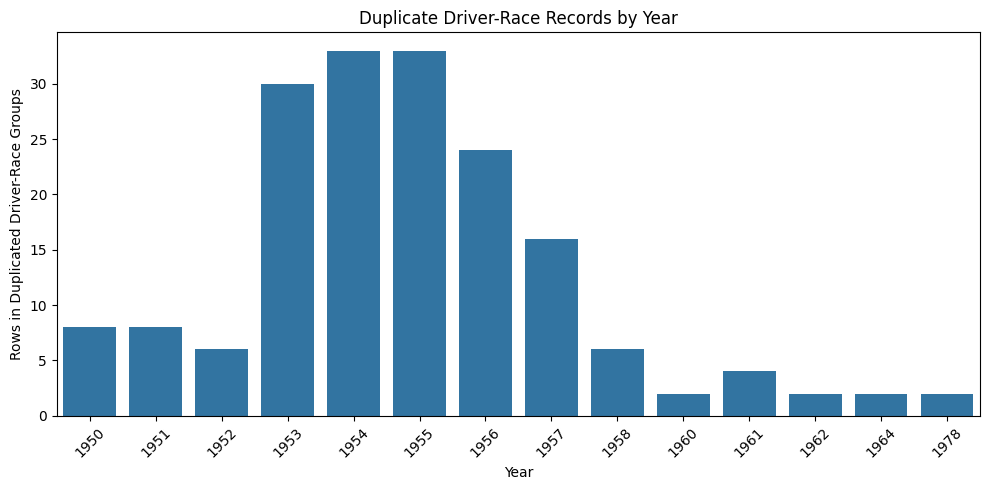

In [119]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=duplicates_by_year,
    x="year",
    y="Duplicate_Rows"
)

plt.title("Duplicate Driver-Race Records by Year")
plt.xlabel("Year")
plt.ylabel("Rows in Duplicated Driver-Race Groups")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Shared-Drive Resolution

The required modeling grain is exactly one observation for each `(raceId, driverId)`
combination. However, 85 historical driver-race combinations contain multiple result
records due primarily to shared drives in early Formula 1.

For each duplicated `(raceId, driverId)` group, the record with the smallest
`positionOrder` is retained. Since a smaller `positionOrder` represents a better
finishing classification, this preserves the driver's best recorded race outcome and
ensures that a podium result is retained if any of the driver's shared-drive records
finished in the top three.

If multiple records have the same `positionOrder`, the smallest `resultId` is used as
a deterministic tie-breaker.

This process removes 91 additional rows while preserving one complete result record
for each driver-race combination. `positionOrder` is retained because it is required
later to construct the podium target (`positionOrder <= 3`). Although it is needed for
target construction, it will not be used as a predictive feature because it is only
known after the race.

After resolution, `(raceId, driverId)` uniqueness is checked again to confirm the
required one-row-per-driver-per-race grain.

**Limitation:** Retaining the record with the smallest `positionOrder`
is a deterministic modeling decision that preserves the driver's best
recorded finishing classification. However, historical shared-drive
results may involve multiple drivers sharing the same car, so this
rule does not necessarily reconstruct the exact historical allocation
of race results or championship points.

In [120]:
duplicate_group_sizes = (
    clean_data["results"]
    .groupby(["raceId", "driverId"])
    .size()
    .reset_index(name="Rows_Per_Driver_Race")
)

duplicate_group_sizes = duplicate_group_sizes[
    duplicate_group_sizes["Rows_Per_Driver_Race"] > 1
]

print("Number of duplicated driver-race groups:", len(duplicate_group_sizes))
print(
    "Extra rows that must be removed:",
    (duplicate_group_sizes["Rows_Per_Driver_Race"] - 1).sum()
)

display(
    duplicate_group_sizes["Rows_Per_Driver_Race"]
    .value_counts()
    .sort_index()
    .rename_axis("Rows_Per_Driver_Race")
    .reset_index(name="Number_of_Groups")
)

Number of duplicated driver-race groups: 85
Extra rows that must be removed: 91


,Rows_Per_Driver_Race,Number_of_Groups
0,2,79
1,3,6


In [121]:
results_model = (
    clean_data["results"]
    .sort_values(
        ["raceId", "driverId", "positionOrder", "resultId"],
        ascending=[True, True, True, True]
    )
    .drop_duplicates(
        subset=["raceId", "driverId"],
        keep="first"
    )
    .reset_index(drop=True)
)

print(
    "Rows before duplicate resolution:",
    len(clean_data["results"])
)

print(
    "Rows after duplicate resolution:",
    len(results_model)
)

print(
    "Rows removed:",
    len(clean_data["results"]) - len(results_model)
)

Rows before duplicate resolution: 26759
Rows after duplicate resolution: 26668
Rows removed: 91


In [122]:
remaining_driver_race_duplicates = (
    results_model
    .duplicated(
        subset=["raceId", "driverId"]
    )
    .sum()
)

print(
    "Remaining duplicate (raceId, driverId) pairs:",
    remaining_driver_race_duplicates
)

assert remaining_driver_race_duplicates == 0

print("Required one-row-per-driver-per-race grain confirmed.")

Remaining duplicate (raceId, driverId) pairs: 0
Required one-row-per-driver-per-race grain confirmed.


## 1.9 Post-Cleaning Exploratory Data Analysis

After cleaning, the data is explored again to evaluate the impact of the transformations.

The post-cleaning EDA examines:
- missingness after converting sentinel values to proper `NaN`;
- changes in Pandas-recognized missingness before and after sentinel cleaning;
- structural patterns in missing data;
- the success of date and duration conversions;
- the distributions of newly converted duration variables;
- the effect of resolving duplicate driver-race records;
- and the final data-quality status.

These checks verify that the cleaning operations produced their intended effects and
help identify whether any additional cleaning is required before constructing the
modeling table.

### 1.9.1 Missingness After Cleaning

Missingness is recalculated after sentinel replacement using Pandas-native missing-value
detection.

At this stage, missing values are not expected to disappear because sentinel cleaning
standardized their representation rather than imputing or deleting them. The purpose of
this analysis is therefore to verify that missing information is now consistently
represented as proper `NaN` values and can be handled correctly in later processing.

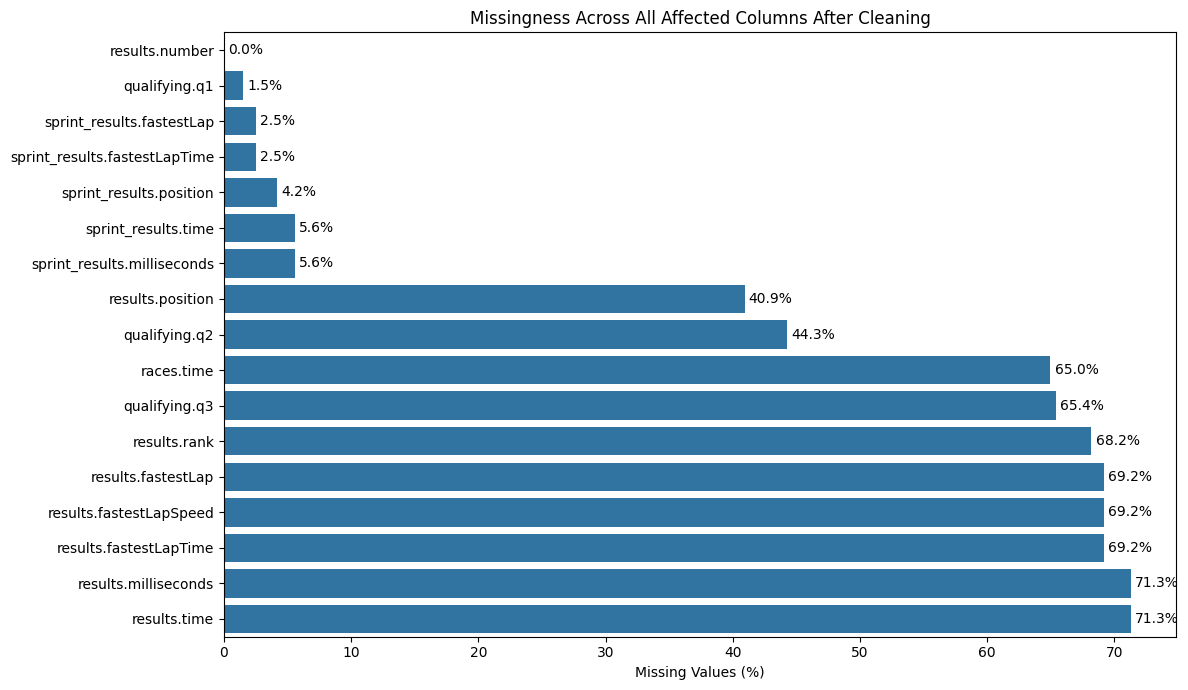

In [123]:
missing_after = []

for table_name, df in clean_data.items():

    for column in df.columns:

        # Exclude newly derived duration columns so the comparison
        # remains focused on the original dataset variables.
        if column.endswith("_seconds"):
            continue

        missing_count = df[column].isnull().sum()

        if missing_count > 0:
            missing_after.append({
                "Feature": f"{table_name}.{column}",
                "Missing_Count": missing_count,
                "Missing_Percentage": missing_count / len(df) * 100
            })

missing_after = pd.DataFrame(missing_after)

missing_after_plot = (
    missing_after
    .sort_values("Missing_Percentage", ascending=True)
    .copy()
)

plt.figure(
    figsize=(12, max(7, len(missing_after_plot) * 0.35))
)

ax = sns.barplot(
    data=missing_after_plot,
    x="Missing_Percentage",
    y="Feature"
)

plt.title("Missingness Across All Affected Columns After Cleaning")
plt.xlabel("Missing Values (%)")
plt.ylabel("")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.tight_layout()
plt.show()

#### Observation

Missingness remains highly uneven across the dataset after cleaning. Some variables have
very high levels of missingness, while others are only slightly affected.

This is expected because replacing `\N` with `NaN` standardizes missing-value
representation but does not remove or impute missing information. The variation also
shows why a single global missing-value rule would be inappropriate: missingness must
later be handled according to the meaning and modeling role of individual features.

### 1.9.2 Effect of Sentinel Cleaning on Recognized Missingness

Before cleaning, the literal string `\N` was stored as ordinary text and was therefore
not recognized by Pandas as a missing value. Standard missing-value detection consequently
underestimated missingness in columns containing these sentinels.

The following visualization compares the percentage of missing values recognized by
Pandas before and after sentinel replacement. An increase after cleaning does not mean
that new information was lost; it means that previously hidden `\N` values are now
correctly represented and detected as `NaN`.

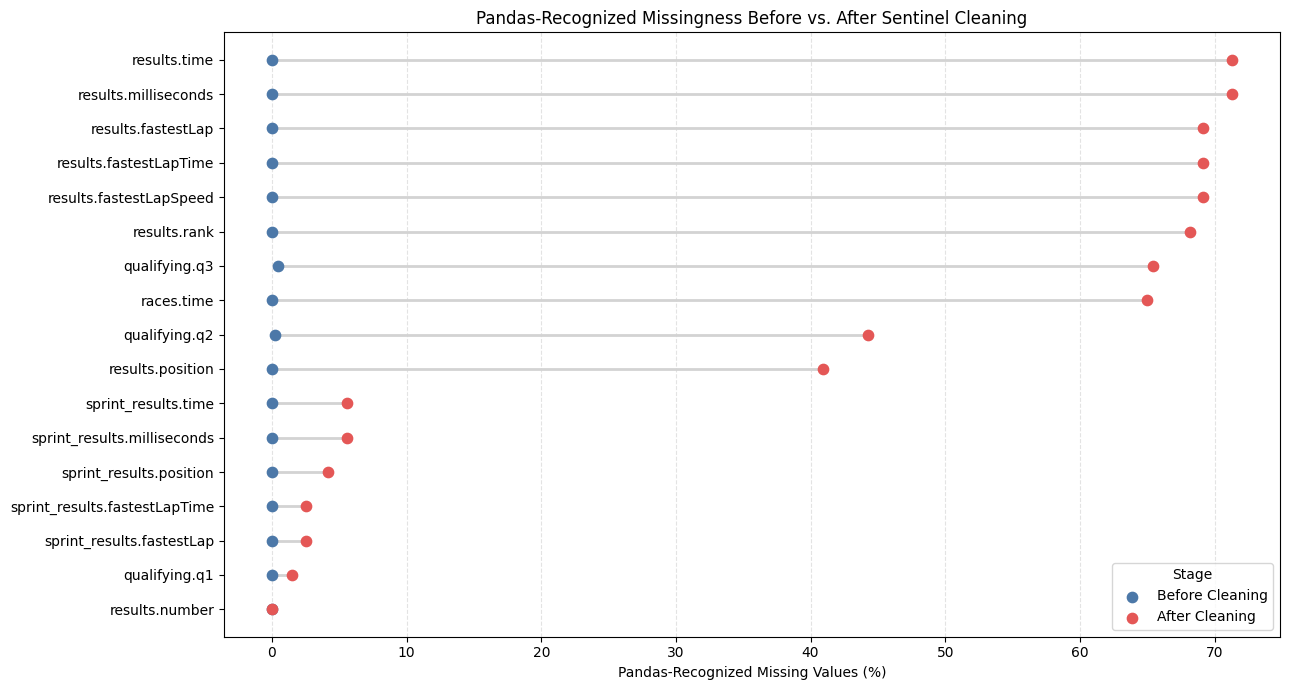

In [124]:
recognized_before = []

recognized_after = []



# Pandas-recognized missingness in the raw data

for table_name, df in raw_data.items():



    for column in df.columns:



        recognized_before.append({

            "Feature": f"{table_name}.{column}",

            "Before Cleaning": df[column].isnull().sum() / len(df) * 100

        })





# Pandas-recognized missingness after cleaning

for table_name, df in clean_data.items():



    for column in df.columns:



        if column.endswith("_seconds"):

            continue



        recognized_after.append({

            "Feature": f"{table_name}.{column}",

            "After Cleaning": df[column].isnull().sum() / len(df) * 100

        })





recognized_before = pd.DataFrame(recognized_before)

recognized_after = pd.DataFrame(recognized_after)



recognized_comparison = recognized_before.merge(

    recognized_after,

    on="Feature",

    how="outer"

).fillna(0)



# Only display variables with missingness before or after cleaning

recognized_comparison = recognized_comparison[

    (recognized_comparison["Before Cleaning"] > 0) |

    (recognized_comparison["After Cleaning"] > 0)

]



recognized_comparison = recognized_comparison.sort_values(

    "After Cleaning",

    ascending=True

).reset_index(drop=True)



fig, ax = plt.subplots(

    figsize=(13, max(7, len(recognized_comparison) * 0.4))

)



y_positions = np.arange(len(recognized_comparison))

before_values = recognized_comparison["Before Cleaning"].to_numpy()

after_values = recognized_comparison["After Cleaning"].to_numpy()



# Connecting lines emphasize the change for each feature.

for y_position, before, after in zip(

    y_positions,

    before_values,

    after_values

):

    ax.plot(

        [before, after],

        [y_position, y_position],

        color="lightgray",

        linewidth=2,

        zorder=1

    )



ax.scatter(

    before_values,

    y_positions,

    s=55,

    color="#4C78A8",

    label="Before Cleaning",

    zorder=2

)

ax.scatter(

    after_values,

    y_positions,

    s=55,

    color="#E45756",

    label="After Cleaning",

    zorder=2

)



ax.set_yticks(y_positions)

ax.set_yticklabels(recognized_comparison["Feature"])

ax.set_xlabel("Pandas-Recognized Missing Values (%)")

ax.set_ylabel("")

ax.set_title("Pandas-Recognized Missingness Before vs. After Sentinel Cleaning")

ax.legend(title="Stage")

ax.grid(axis="x", linestyle="--", alpha=0.35)

ax.set_axisbelow(True)



plt.tight_layout()

plt.show()


#### Observation

The comparison shows a substantial increase in Pandas-recognized missingness after
sentinel cleaning for many affected variables. Before cleaning, most `\N` values were
treated as ordinary strings and therefore did not appear in standard null counts.

After converting `\N` to `NaN`, these existing missing values become correctly
recognized. The increase therefore reflects improved missing-value representation,
not the creation of new missing data.

### 1.9.3 Missingness Patterns

Missing-value percentages show how much information is absent, but they do not show
whether missing values occur together within the same observations.

Missingness matrices are therefore examined for `races`, `qualifying`, and `results`.
These tables contain several related variables with substantial missingness, making
row-level patterns particularly useful to inspect. Tables with no missingness or
missingness concentrated in only one or two variables are already sufficiently
described by the complete missingness summary.

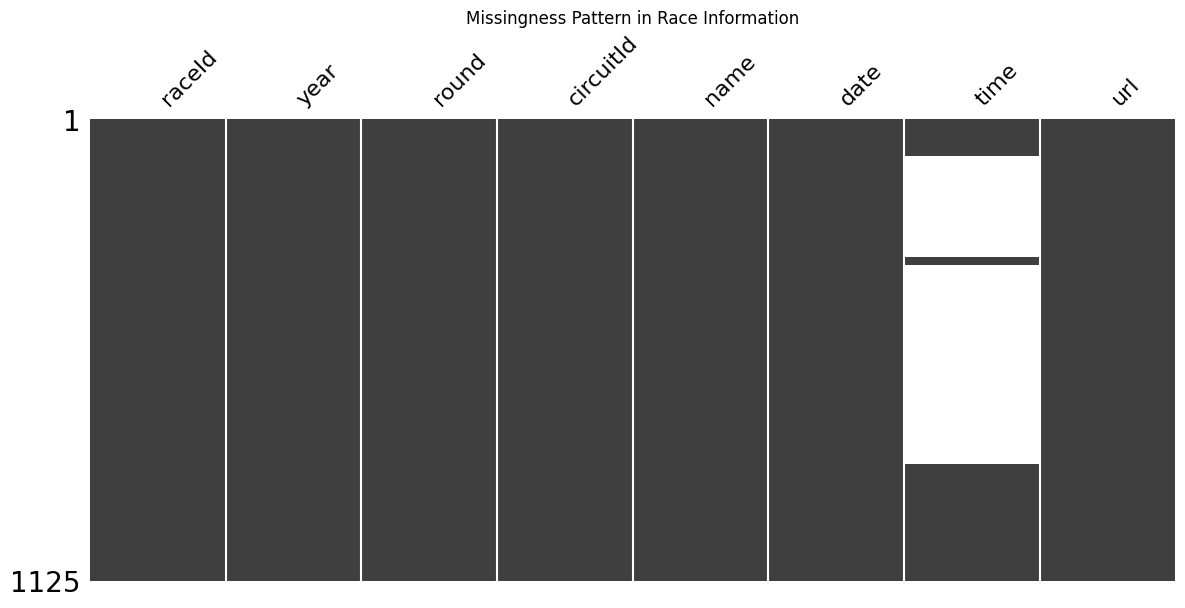

In [125]:
msno.matrix(
    clean_data["races"],
    figsize=(14, 6),
    sparkline=False
)

plt.title("Missingness Pattern in Race Information")
plt.show()

#### Race-Information Observation

The `races` table shows a clear structural pattern in missingness. Core race information,
including race identifiers, year, round, circuit, name, and date, is consistently available,
while detailed session date and time fields are much less complete.

The missing values are concentrated in specific session-related fields rather than being
uniformly distributed across all variables. This suggests that the missingness is
systematic and should be investigated according to the meaning and availability of each
field rather than handled using a single global missing-value rule.

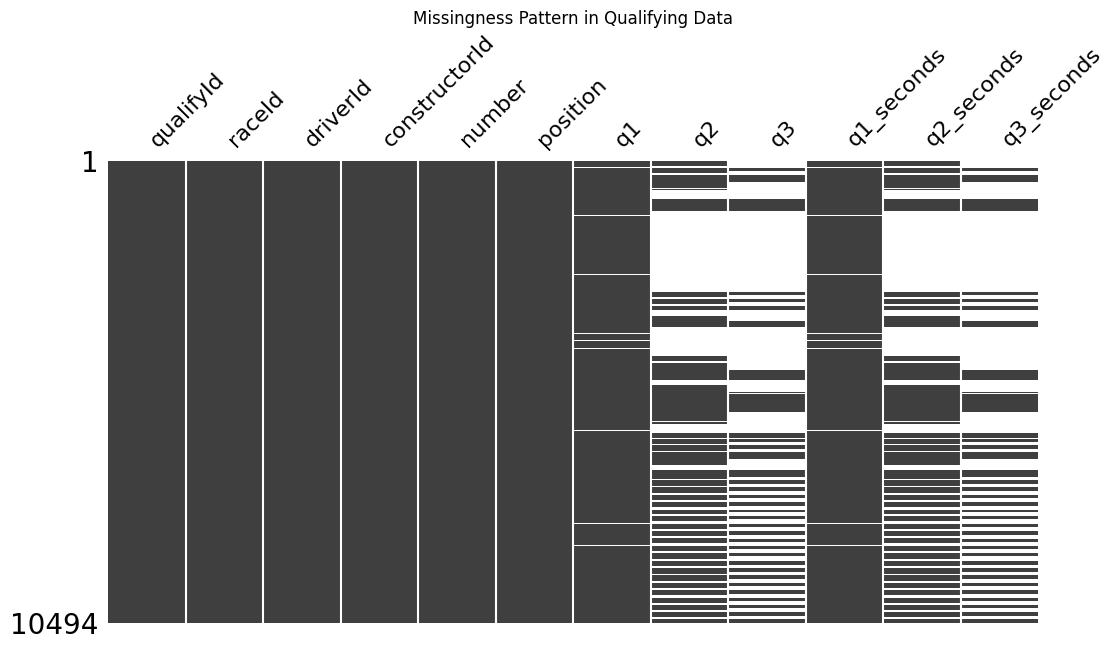

In [126]:
msno.matrix(
    clean_data["qualifying"],
    figsize=(12, 6),
    sparkline=False
)

plt.title("Missingness Pattern in Qualifying Data")
plt.show()

#### Qualifying Observation

The `qualifying` table shows progressively lower coverage across the qualifying-session
time fields, with Q1 being substantially more complete than Q2 and Q3. Identifier and
qualifying-position fields remain complete.

The missingness patterns of `q1`, `q2`, and `q3` are also mirrored by their corresponding
`_seconds` variables, providing visual evidence that duration conversion preserved the
existing missing-value structure rather than introducing widespread additional
missingness.

These patterns support handling qualifying missingness according to its meaning and
historical availability rather than applying a single global deletion or imputation rule.

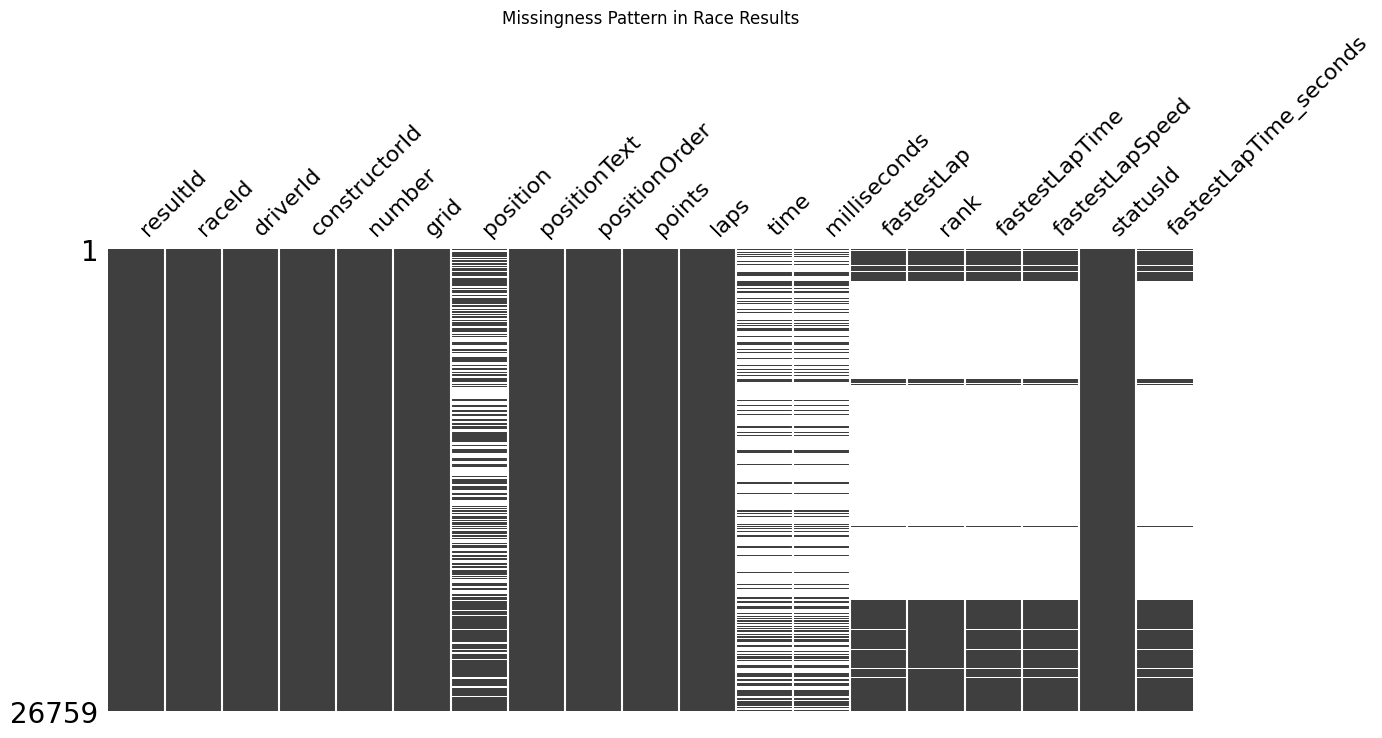

In [127]:
msno.matrix(
    clean_data["results"],
    figsize=(14, 6),
    sparkline=False
)

plt.title("Missingness Pattern in Race Results")
plt.show()

#### Race-Results Observation

The `results` table shows complete coverage for the main identifiers and several core
race variables, including `positionOrder`, while timing and fastest-lap measurements
have substantially lower coverage.

The completeness of `positionOrder` is important because it will later be used to
construct the podium target. The converted `fastestLapTime_seconds` variable also
follows the missingness pattern of its original source field, supporting the consistency
of the duration conversion.

The structured missingness in the remaining result fields is retained at this stage
rather than being removed through global row deletion or imputation.

### 1.9.4 Semantic Conversion Validation

Successful datatype conversion requires more than checking the resulting datatype.
Because invalid values can be silently converted to missing values during parsing,
conversion success is explicitly audited.

For each converted date or duration variable, a parse failure is defined as an
observation where the cleaned source value is present but the converted value is
missing. This distinguishes genuine missing data from missing values introduced by a
failed conversion.

In [128]:
semantic_audit = []

# Audit only columns that survived the 90% missingness rule.
date_columns = {
    "races": ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"],
    "drivers": ["dob"],
}

for table_name, columns in date_columns.items():
    raw_table = raw_data.get(table_name)
    clean_table = clean_data.get(table_name)
    if raw_table is None or clean_table is None:
        raise KeyError(f"Required table '{table_name}' is missing")
    for column in columns:
        if column not in raw_table.columns or column not in clean_table.columns:
            continue
        source = raw_table[column].replace(r"^\s*\\N\s*$", np.nan, regex=True)
        converted = clean_table[column]
        source_present = source.notna()
        parse_failures = (source_present & converted.isna()).sum()
        semantic_audit.append({
            "Variable": f"{table_name}.{column}",
            "Semantic_Type": "Date",
            "Source_Values": source_present.sum(),
            "Parse_Failures": parse_failures,
        })

# Audit duration conversions only when both source and derived columns remain.
duration_columns_audit = {
    "results": ["fastestLapTime"],
    "qualifying": ["q1", "q2", "q3"],
    "lap_times": ["time"],
    "pit_stops": ["duration"],
    "sprint_results": ["fastestLapTime"],
}

for table_name, columns in duration_columns_audit.items():
    clean_table = clean_data.get(table_name)
    if clean_table is None:
        raise KeyError(f"Required table '{table_name}' is missing")
    for column in columns:
        converted_column = f"{column}_seconds"
        if column not in clean_table.columns or converted_column not in clean_table.columns:
            continue
        source = clean_table[column]
        converted = clean_table[converted_column]
        source_present = source.notna()
        parse_failures = (source_present & converted.isna()).sum()
        semantic_audit.append({
            "Variable": f"{table_name}.{column}",
            "Semantic_Type": "Duration",
            "Source_Values": source_present.sum(),
            "Parse_Failures": parse_failures,
        })

semantic_audit = pd.DataFrame(semantic_audit)

if semantic_audit.empty:
    semantic_audit = pd.DataFrame(
        columns=["Variable", "Semantic_Type", "Source_Values", "Parse_Failures"]
    )

semantic_audit["Successful_Conversions"] = (
    semantic_audit["Source_Values"] - semantic_audit["Parse_Failures"]
)
semantic_audit["Success_Rate"] = np.where(
    semantic_audit["Source_Values"] > 0,
    semantic_audit["Successful_Conversions"] / semantic_audit["Source_Values"] * 100,
    np.nan,
)

display(semantic_audit)


,Variable,Semantic_Type,Source_Values,Parse_Failures,Successful_Conversions,Success_Rate
0,races.date,Date,1125,0,1125,100.0
1,drivers.dob,Date,861,0,861,100.0
2,results.fastestLapTime,Duration,8252,0,8252,100.0
3,qualifying.q1,Duration,10338,0,10338,100.0
4,qualifying.q2,Duration,5847,0,5847,100.0
5,qualifying.q3,Duration,3629,0,3629,100.0
6,lap_times.time,Duration,589081,0,589081,100.0
7,pit_stops.duration,Duration,11371,0,11371,100.0
8,sprint_results.fastestLapTime,Duration,351,0,351,100.0


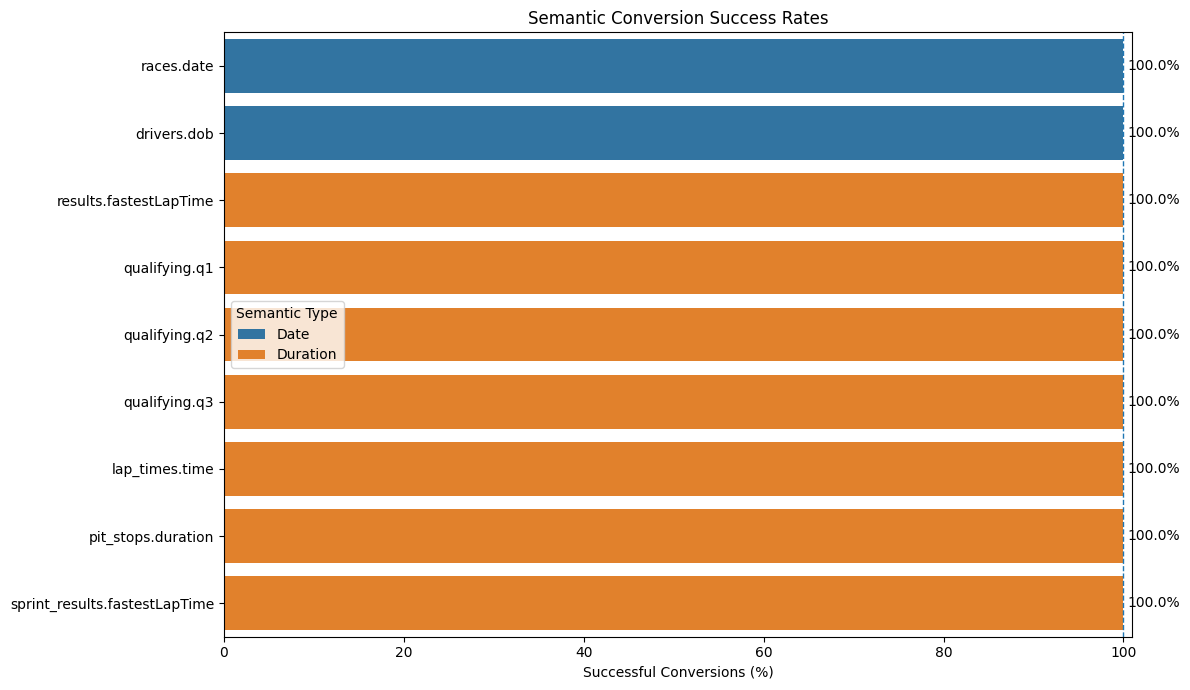

In [129]:
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=semantic_audit,
    x="Success_Rate",
    y="Variable",
    hue="Semantic_Type"
)

plt.axvline(
    100,
    linestyle="--",
    linewidth=1
)

plt.xlim(0, 101)

plt.title("Semantic Conversion Success Rates")
plt.xlabel("Successful Conversions (%)")
plt.ylabel("")
plt.legend(title="Semantic Type")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.tight_layout()
plt.show()

In [130]:
total_parse_failures = semantic_audit["Parse_Failures"].sum()

print(
    "Total semantic conversion failures:",
    total_parse_failures
)

Total semantic conversion failures: 0


### 1.9.5 Relational-Integrity Validation

Primary-key and foreign-key checks are summarized after cleaning to verify that the
relational structure of the dataset remains valid.

A successful primary-key check means that the tested keys are unique and non-null,
while a successful foreign-key check means that all tested references match existing
records in their corresponding parent tables.

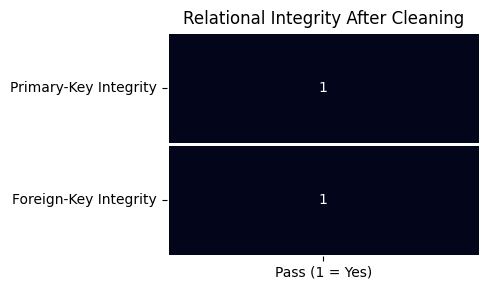

In [131]:
integrity_summary = pd.DataFrame({
    "Check": [
        "Primary-Key Integrity",
        "Foreign-Key Integrity"
    ],
    "Passed": [
        pk_results["Valid"].all(),
        fk_results["Valid"].all()
    ]
})

integrity_plot = (
    integrity_summary
    .set_index("Check")[["Passed"]]
    .astype(int)
)

plt.figure(figsize=(5, 3))

sns.heatmap(
    integrity_plot,
    annot=True,
    fmt="d",
    cbar=False,
    linewidths=1,
    xticklabels=["Pass (1 = Yes)"]
)

plt.title("Relational Integrity After Cleaning")
plt.xlabel("")
plt.ylabel("")

plt.tight_layout()
plt.show()

#### Observation

All tested primary-key and foreign-key integrity checks pass after cleaning. The tested
primary keys remain unique and non-null, and all tested foreign-key values reconcile
with their corresponding parent tables.

This confirms that the cleaning process preserved the tested relational structure of
the dataset.

### 1.9.6 Driver-Race Duplicate Resolution

The effect of the shared-drive resolution is evaluated by comparing the number of
excess `(raceId, driverId)` rows before and after applying the documented resolution
rule.

The resulting driver-race base must contain exactly one observation for each
`(raceId, driverId)` combination.

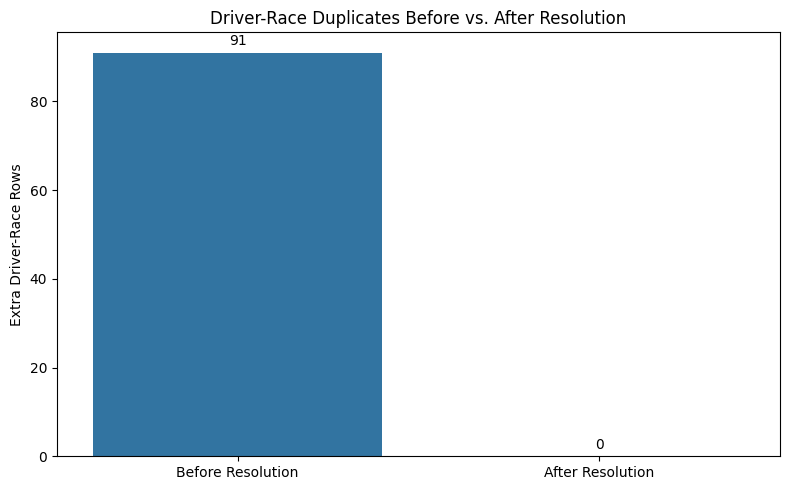

In [132]:
grain_comparison = pd.DataFrame({
    "Stage": [
        "Before Resolution",
        "After Resolution"
    ],
    "Extra_Driver_Race_Rows": [
        clean_data["results"]
        .duplicated(subset=["raceId", "driverId"])
        .sum(),

        results_model
        .duplicated(subset=["raceId", "driverId"])
        .sum()
    ]
})

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=grain_comparison,
    x="Stage",
    y="Extra_Driver_Race_Rows"
)

plt.title("Driver-Race Duplicates Before vs. After Resolution")
plt.xlabel("")
plt.ylabel("Extra Driver-Race Rows")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

#### Observation

Before resolution, 91 excess rows violated the required one-row-per-driver-per-race
grain. After applying the shared-drive resolution rule, no duplicate
`(raceId, driverId)` combinations remain.

This confirms that `results_model` satisfies the required unique driver-race grain.

# 2. Data-Engineering Questions

This section answers three historical Formula 1 questions using
multi-table joins across the cleaned dataset.

For each question, we provide:
1. The tables joined and the observation grain.
2. Relevant data-quality and missingness considerations.
3. The methodology used to calculate the results.
4. Visualizations supporting the analysis.
5. Findings and limitations.

**Data Scope:** The dataset covers Formula 1 races from 1950Ã¢â‚¬â€œ2024.
Questions 1 and 2 use the available historical data, while
Question 3 focuses on the explicitly requested periods:
2014Ã¢â‚¬â€œ2021 and 2022Ã¢â‚¬â€œ2024.

These are historical analyses, so finishing outcomes are used
to calculate the requested statistics. This is separate from
the machine-learning prediction cutoff, where only information
available before the race may be used as model features.

## 2.1 Front-Row Starts → Podium Conversion Rate by Circuit

**Question:** Which circuits convert a front-row start into a podium
most often, and does that ranking change after 2014?
Distinguish qualifying position from starting-grid position,
which may differ due to penalties.

**Tables Joined:**
- `results_model` (raceId, driverId, grid, positionOrder)
- `qualifying` (qualifying position)
- `races` (raceId, year, circuitId)
- `circuits` (circuitId, name)

**Strategy:** We calculate the podium-conversion rate for drivers
who actually started from grid positions P1 or P2.

Qualifying positions are retained separately to identify
differences between qualifying results and the final starting grid.

**Grain:** One observation per `(raceId, driverId)` where
`results.grid` is either 1 or 2.

**Missingness:** Historical qualifying information is incomplete,
particularly before 2003. Missing qualifying positions do not
cause observations to be excluded when grid positions and
race outcomes are available.

**Data Scope:** The analysis uses historical Formula 1 races
through 2024.

**Limitations:** Some circuits have relatively few front-row starts,
and observed conversion rates may be sensitive to sample size.
The pre-2014 and 2014-onwards comparison is descriptive and
does not establish that regulation changes caused differences.

In [133]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# ── Re-use the already-cleaned tables from Section 1 ─────────────────────────
results    = results_model.copy()
races      = clean_data["races"].copy()
circuits   = clean_data["circuits"].copy()
qualifying = clean_data["qualifying"].copy()

# ── Select historical races through 2024 ─────────────────────────────────────
past_races = races[
    races["date"] < "2025-01-01"
][["raceId", "year", "circuitId", "date"]].copy()

# ── Merge results with past races ─────────────────────────────────────────────
res = results.merge(
    past_races,
    on="raceId",
    how="inner",
    validate="many_to_one"
)

# ── Add circuit names ─────────────────────────────────────────────────────────
res = res.merge(
    circuits[["circuitId", "name"]].rename(
        columns={"name": "circuit_name"}
    ),
    on="circuitId",
    how="left",
    validate="many_to_one"
)

# ── Add qualifying positions (before grid adjustments) ───────────────────────
qual = qualifying[
    ["raceId", "driverId", "position"]
].rename(columns={"position": "quali_pos"})

res = res.merge(
    qual,
    on=["raceId", "driverId"],
    how="left",
    validate="many_to_one"
)

# ── Select actual front-row starters (grid P1 or P2) ──────────────────────────
front_row = res[
    res["grid"].isin([1, 2])
].copy()

# ── Identify podium finishes ──────────────────────────────────────────────────
front_row["is_podium"] = front_row["positionOrder"] <= 3

# ── Era comparison ────────────────────────────────────────────────────────────
front_row["era"] = np.where(
    front_row["year"] >= 2014,
    "2014 onwards",
    "Pre-2014"
)

# ── Compare qualifying position with actual starting grid ────────────────────
front_row["grid_differs_from_quali"] = (
    front_row["quali_pos"].notna()
    & (front_row["grid"] != front_row["quali_pos"])
)

# ── Verify one row per driver per race ────────────────────────────────────────
assert not front_row.duplicated(["raceId", "driverId"]).any()

# ── Print summary ─────────────────────────────────────────────────────────────
print(f"Front-row starter events: {len(front_row):,}")

print(
    f"Front-row starters with missing qualifying positions: "
    f"{front_row['quali_pos'].isna().sum():,}"
)

print(
    f"Front-row starters whose grid differs from qualifying: "
    f"{front_row['grid_differs_from_quali'].sum():,}"
)

print(
    f"Overall podium conversion rate: "
    f"{front_row['is_podium'].mean():.2%}"
)

Front-row starter events: 2,243
Front-row starters with missing qualifying positions: 1,257
Front-row starters whose grid differs from qualifying: 49
Overall podium conversion rate: 60.05%


### Methodology and Visualization Choices

**Minimum Sample Size:** To reduce the influence of circuits with very few observations, we require at least 10 front-row starts (grid positions 1Ã¢â‚¬â€œ2) for the overall circuit ranking. Small samples can produce extreme conversion rates that may not represent consistent historical performance. This threshold is a practical filtering choice rather than a guarantee of statistical reliability.

**Era Comparison:** For the Pre-2014 and 2014-onwards comparison, we lower the minimum to 5 front-row starts per circuit per era. Splitting the data into periods reduces the available observations, so this threshold retains more circuits for comparison. However, results based on small samples should be interpreted cautiously.

**Top 20 Visualization:** We calculate conversion rates for all eligible circuits but visualize only the top 20 to maintain readability and highlight the highest-performing circuits. The complete rankings remain available in `circuit_stats`.

**Limitation:** The selected thresholds (10 overall and 5 per era) are analytical choices, not statistically determined minimum sample sizes. Circuit rankings may change when different thresholds are applied.

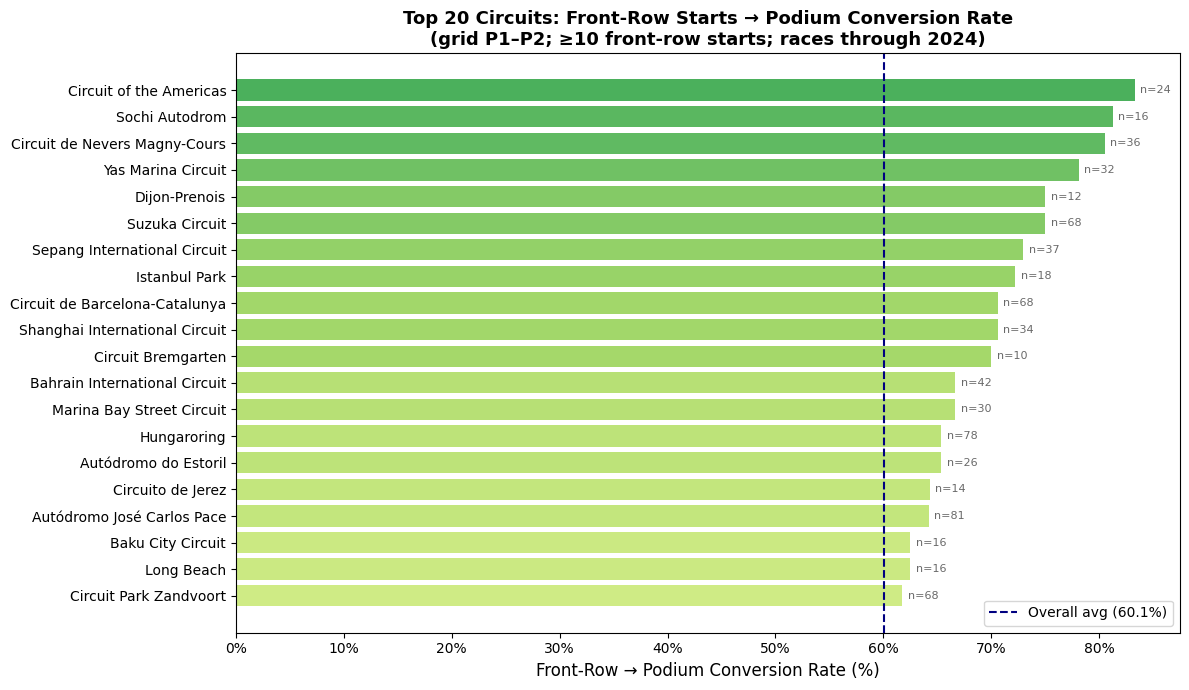


Top 10 circuits (overall):
                  circuit_name  appearances  podiums  conversion_rate
       Circuit of the Americas           24       20         0.833333
                Sochi Autodrom           16       13         0.812500
 Circuit de Nevers Magny-Cours           36       29         0.805556
            Yas Marina Circuit           32       25         0.781250
                 Dijon-Prenois           12        9         0.750000
                Suzuka Circuit           68       51         0.750000
  Sepang International Circuit           37       27         0.729730
                 Istanbul Park           18       13         0.722222
Circuit de Barcelona-Catalunya           68       48         0.705882
Shanghai International Circuit           34       24         0.705882


In [134]:
# ── Overall podium conversion rate per circuit ───────────────────────────────
MIN_APPEARANCES = 10

circuit_stats = (
    front_row
    .groupby("circuit_name")
    .agg(
        appearances=("is_podium", "count"),
        podiums=("is_podium", "sum")
    )
    .reset_index()
)

circuit_stats["conversion_rate"] = (
    circuit_stats["podiums"] / circuit_stats["appearances"]
)

circuit_stats = circuit_stats[
    circuit_stats["appearances"] >= MIN_APPEARANCES
].copy()

circuit_stats = circuit_stats.sort_values(
    "conversion_rate",
    ascending=False
)

# ── Era-split rates ───────────────────────────────────────────────────────────
era_stats = (
    front_row
    .groupby(["circuit_name", "era"])
    .agg(
        appearances=("is_podium", "count"),
        podiums=("is_podium", "sum")
    )
    .reset_index()
)

era_stats["conversion_rate"] = (
    era_stats["podiums"] / era_stats["appearances"]
)

era_stats = era_stats[
    era_stats["appearances"] >= 5
].copy()

# ── Figure 1: Top 20 circuits by front-row podium conversion ─────────────────
top20 = circuit_stats.head(20)

fig, ax = plt.subplots(figsize=(12, 7))

plot_data = top20.iloc[::-1]

bars = ax.barh(
    plot_data["circuit_name"],
    plot_data["conversion_rate"] * 100,
    color=plt.cm.RdYlGn(plot_data["conversion_rate"])
)

ax.set_xlabel(
    "Front-Row → Podium Conversion Rate (%)",
    fontsize=12
)

ax.set_title(
    "Top 20 Circuits: Front-Row Starts → Podium Conversion Rate\n"
    "(grid P1–P2; ≥10 front-row starts; races through 2024)",
    fontsize=13,
    fontweight="bold"
)

ax.xaxis.set_major_formatter(mtick.PercentFormatter())

ax.axvline(
    front_row["is_podium"].mean() * 100,
    color="navy",
    linestyle="--",
    linewidth=1.5,
    label=f"Overall avg ({front_row['is_podium'].mean():.1%})"
)

ax.legend(fontsize=10)

for bar, (_, row) in zip(bars, plot_data.iterrows()):
    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"n={int(row['appearances'])}",
        va="center",
        fontsize=8,
        color="dimgray"
    )

plt.tight_layout()
plt.show()

print("\nTop 10 circuits (overall):")

print(
    circuit_stats[
        ["circuit_name", "appearances", "podiums", "conversion_rate"]
    ]
    .head(10)
    .to_string(index=False)
)

### Figure 2: Front-Row Podium Conversion — Era Comparison

To investigate whether circuit rankings changed after the introduction of hybrid power units in 2014, we compare front-row-to-podium conversion rates between two periods: **Pre-2014** and **2014 onwards**.

**Circuit Selection:** Only circuits with at least 5 front-row starts in each period are included. Splitting the dataset into two eras reduces the number of observations per circuit, so this threshold allows more circuits to be compared while excluding extremely small samples. Circuits without sufficient observations in both periods are excluded because a direct comparison would not be meaningful.

**Ranking Comparison:** We calculate both the difference in conversion rates (`delta`) and the change in ranking positions (`rank_change`). A positive `delta` indicates a higher conversion rate after 2014, while a positive `rank_change` indicates an improvement in the circuit's relative ranking.

**Visualization:** We display the top 20 eligible circuits based on their 2014-onwards conversion rates. Both graphs use the same circuit order to make before-and-after comparisons easier. The complete comparison is retained in `era_pivot`.

**Limitations:** The minimum of 5 appearances is an exploratory threshold rather than a statistically guaranteed sample size. Additionally, the 2014-onwards period includes the 2022–2024 ground-effect era, so observed changes cannot be attributed solely to the introduction of hybrid regulations.

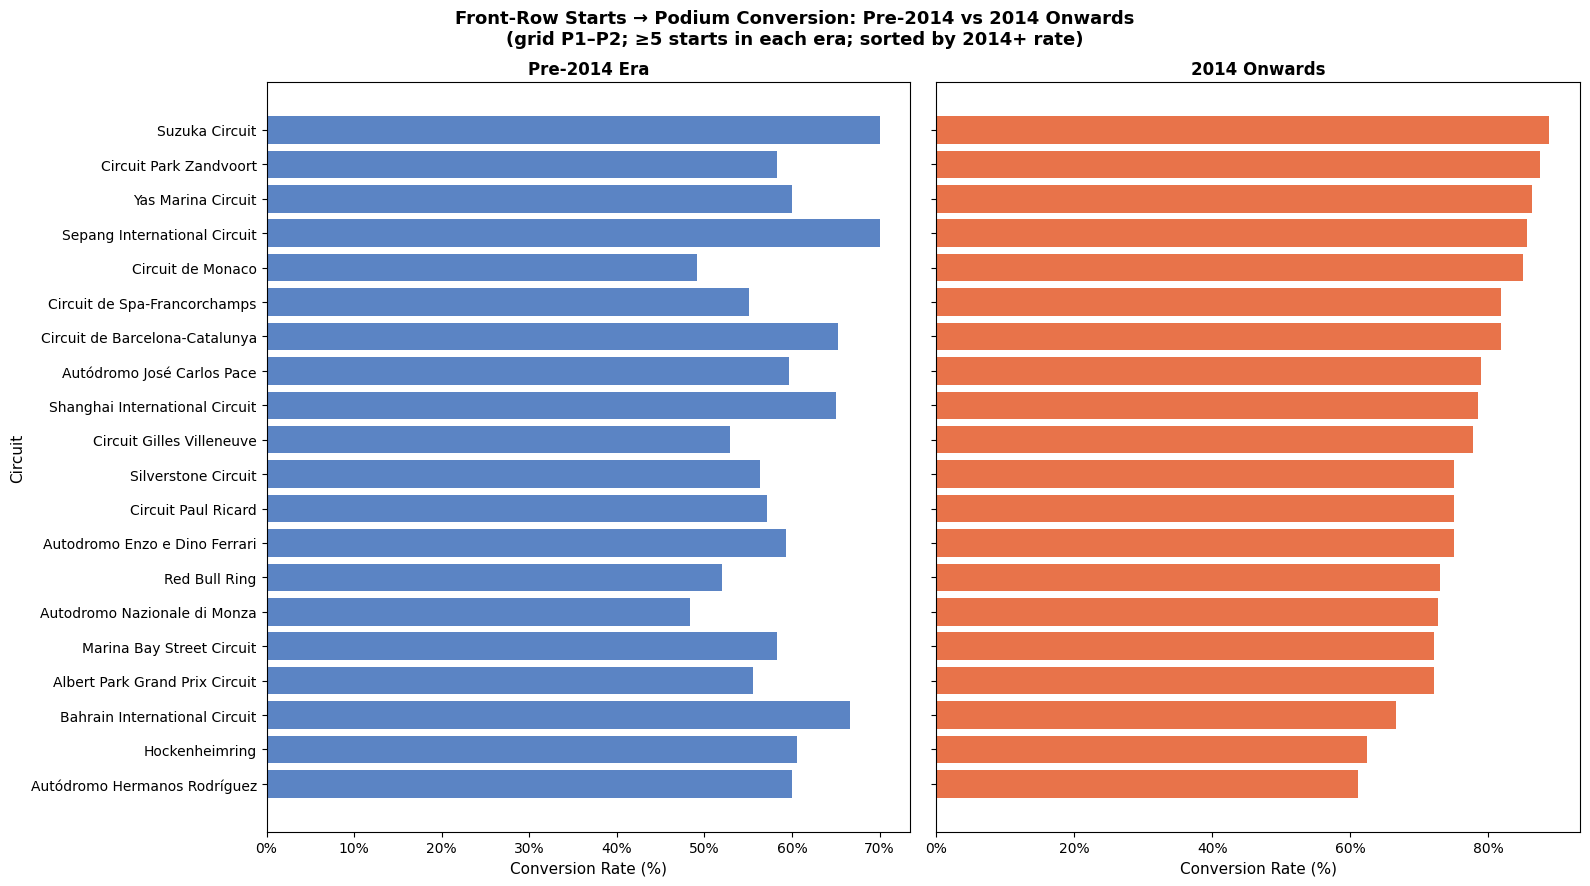


Top 10 increases in conversion rate:
                circuit_name  Pre-2014  2014 onwards    delta
           Circuit de Monaco  0.491667      0.850000 0.358333
      Circuit Park Zandvoort  0.583333      0.875000 0.291667
Circuit de Spa-Francorchamps  0.550562      0.818182 0.267620
          Yas Marina Circuit  0.600000      0.863636 0.263636
   Circuit Gilles Villeneuve  0.529412      0.777778 0.248366
Autodromo Nazionale di Monza  0.483871      0.727273 0.243402
               Red Bull Ring  0.520000      0.730769 0.210769
  Autódromo José Carlos Pace  0.596774      0.789474 0.192699
              Suzuka Circuit  0.700000      0.888889 0.188889
         Silverstone Circuit  0.563830      0.750000 0.186170

Circuit ranking comparison:
                  circuit_name  rank_pre2014  rank_2014_onwards  rank_change
                Suzuka Circuit             1                  1            0
        Circuit Park Zandvoort            12                  2           10
            Yas Mari

In [135]:
# ── Figure 2: Era comparison — does the ranking change after 2014? ────────────

# Pivot to compare Pre-2014 vs 2014 onwards
era_pivot = (
    era_stats
    .pivot(
        index="circuit_name",
        columns="era",
        values="conversion_rate"
    )
    .dropna(subset=["Pre-2014", "2014 onwards"])
    .reset_index()
)

# ── Calculate conversion-rate changes ─────────────────────────────────────────
era_pivot["delta"] = (
    era_pivot["2014 onwards"] - era_pivot["Pre-2014"]
)

# ── Calculate ranking changes ─────────────────────────────────────────────────
era_pivot["rank_pre2014"] = (
    era_pivot["Pre-2014"]
    .rank(ascending=False, method="min")
    .astype(int)
)

era_pivot["rank_2014_onwards"] = (
    era_pivot["2014 onwards"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# Positive rank_change means improvement in ranking
era_pivot["rank_change"] = (
    era_pivot["rank_pre2014"] - era_pivot["rank_2014_onwards"]
)

# Sort circuits by 2014-onwards conversion rate
era_pivot = era_pivot.sort_values(
    "2014 onwards",
    ascending=False
)

# ── Select Top 20 circuits for visualization ───────────────────────────────────
top20_era = era_pivot.head(20)

# ── Plot the two eras side by side ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 9), sharey=True)

for ax, col, title, color in zip(
    axes,
    ["Pre-2014", "2014 onwards"],
    ["Pre-2014 Era", "2014 Onwards"],
    ["#5B84C4", "#E8734A"]
):
    ax.barh(
        top20_era["circuit_name"][::-1],
        top20_era[col][::-1] * 100,
        color=color
    )

    ax.set_xlabel("Conversion Rate (%)", fontsize=11)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.xaxis.set_major_formatter(mtick.PercentFormatter())

axes[0].set_ylabel("Circuit", fontsize=11)

fig.suptitle(
    "Front-Row Starts → Podium Conversion: Pre-2014 vs 2014 Onwards\n"
    "(grid P1–P2; ≥5 starts in each era; sorted by 2014+ rate)",
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# ── Print largest conversion-rate increases ───────────────────────────────────
print("\nTop 10 increases in conversion rate:")

print(
    era_pivot[
        ["circuit_name", "Pre-2014", "2014 onwards", "delta"]
    ]
    .sort_values("delta", ascending=False)
    .head(10)
    .to_string(index=False)
)

# ── Print actual ranking changes ──────────────────────────────────────────────
print("\nCircuit ranking comparison:")

print(
    era_pivot[
        [
            "circuit_name",
            "rank_pre2014",
            "rank_2014_onwards",
            "rank_change"
        ]
    ]
    .to_string(index=False)
)

### 2.1 Findings

**Grain:** Each observation represents one `(raceId, driverId)` where the driver actually started from the front row (`results.grid` Ã¢Ë†Ë† {1, 2}). We use the actual starting grid rather than `qualifying.position` because penalties and other adjustments can change starting positions after qualifying.

**Missingness:** Historical qualifying information is incomplete, particularly before 2003. Of the 2,243 front-row starter records, 1,257 have missing qualifying positions. These records are retained because their actual starting positions and race outcomes are available. Among the 986 records with qualifying information, 49 have different qualifying and starting-grid positions.

**Historical Cutoff:** We analyze races dated before January 1, 2025, covering the dataset through 2024. This restriction is separate from the machine-learning prediction cutoff, which permits only pre-race information as model features.

**Methodology:** For each circuit, the podium-conversion rate is calculated as the number of front-row starters finishing in the top three divided by the total number of front-row starts. We require at least 10 appearances for the overall ranking and at least 5 appearances in each period for the era comparison. Both figures display the top 20 eligible circuits for readability.

**Overall Results:** Across 2,243 front-row starter records, the overall podium-conversion rate is **60.05%**. Circuit of the Americas achieved the highest conversion rate among eligible circuits (83.33%, 20/24), followed by Sochi Autodrom (81.25%, 13/16) and Circuit de Nevers Magny-Cours (80.56%, 29/36).

**Era Comparison:** Circuit rankings changed considerably between the two periods. Among circuits with sufficient data in both eras, Suzuka Circuit and Sepang International Circuit tied for first before 2014 (70.00%). From 2014 onwards, Suzuka remained first (88.89%), followed by Circuit Park Zandvoort (87.50%) and Yas Marina Circuit (86.36%).

**Notable Changes:** Circuit de Monaco experienced the largest conversion-rate increase among the circuits shown in the comparison, rising from 49.17% before 2014 to 85.00% afterward (+35.83 percentage points). Its ranking improved from 20th to 5th. Zandvoort improved from 12th to 2nd (+29.17 percentage points), while Spa-Francorchamps improved from 17th to 6th (+26.76 percentage points). In contrast, Hungaroring fell from 3rd to 21st.

**Limitations:** The sample-size thresholds are exploratory choices and do not guarantee statistical significance. Circuit rankings may be sensitive to sample sizes, race conditions, and differences in historical F1 regulations. The 2014-onwards period also includes the 2022Ã¢â‚¬â€œ2024 ground-effect era, so observed changes cannot be attributed solely to the introduction of hybrid power units.

## 2.2 Home-Circuit Advantage — Controlling for Starting Position

**Question:** Do drivers podium more often when racing at a circuit in their home country than elsewhere, after controlling for starting grid position?

**Tables joined:**
- `results_model` (raceId, driverId, grid, positionOrder)
- `races` (raceId, circuitId, year)
- `circuits` (circuitId, country)
- `drivers` (driverId, nationality)

**Strategy:** We compare podium rates between home-race and away-race entries within four starting-grid buckets: P1–P3, P4–P6, P7–P10, and P11+. This reduces differences in starting position between the groups, allowing a more meaningful comparison than overall podium rates alone.

**Grain:** One observation per `(raceId, driverId)` with a valid numbered starting-grid position.

**Country Mapping:** Driver nationalities and circuit countries use different naming conventions (e.g., "British" versus "UK"). We standardize them using mapping dictionaries and inspect unmapped values.

**Missingness:** Records without sufficient country information are excluded because their home/away status cannot be determined. Records with missing or zero grid positions are also excluded from the numbered-grid comparison. Exclusion counts are reported during preprocessing.

**Data Scope:** We analyze the available historical Formula 1 races from 1950–2024, as provided in the dataset. No additional date restriction is applied.

**Limitations:** Grouping starting positions into buckets reduces, but does not completely eliminate, differences in starting position. Grid position 0 may represent a pit-lane start, so excluding these records may omit genuine race starters.

In [136]:
# ── Nationality → Country mapping ────────────────────────────────────────────
# Standardize driver nationalities and circuit countries to consistent labels.

nationality_to_country = {
    "British": "UK",
    "German": "Germany",
    "Spanish": "Spain",
    "Finnish": "Finland",
    "French": "France",
    "Brazilian": "Brazil",
    "Australian": "Australia",
    "Austrian": "Austria",
    "Italian": "Italy",
    "Dutch": "Netherlands",
    "American": "USA",
    "Canadian": "Canada",
    "Mexican": "Mexico",
    "Argentine": "Argentina",
    "Argentinian":    "Argentina",
    "Chilean":        "Chile",
    "Indian":         "India",
    "Liechtensteiner": "Liechtenstein",
    "Uruguayan":      "Uruguay",
    "Belgian": "Belgium",
    "Hungarian": "Hungary",
    "Colombian": "Colombia",
    "Japanese": "Japan",
    "New Zealander": "New Zealand",
    "South African": "South Africa",
    "Polish": "Poland",
    "Swedish": "Sweden",
    "Danish": "Denmark",
    "Swiss": "Switzerland",
    "Monegasque": "Monaco",
    "Malaysian": "Malaysia",
    "Thai": "Thailand",
    "Chinese": "China",
    "Russian": "Russia",
    "Estonian": "Estonia",
    "Czech": "Czech Republic",
    "Portuguese": "Portugal",
    "Venezuelan": "Venezuela",
    "Indonesian": "Indonesia",
    "Irish": "Ireland",
    "Rhodesian": "Zimbabwe",
    "American-Italian": "USA",
    "East German": "Germany",
}

circuit_country_norm = {
    "Australia": "Australia",
    "Malaysia": "Malaysia",
    "Bahrain": "Bahrain",
    "Spain": "Spain",
    "Turkey": "Turkey",
    "Monaco": "Monaco",
    "Canada": "Canada",
    "France": "France",
    "UK": "UK",
    "Germany": "Germany",
    "Hungary": "Hungary",
    "Belgium": "Belgium",
    "Italy": "Italy",
    "Singapore": "Singapore",
    "Japan": "Japan",
    "China": "China",
    "Brazil": "Brazil",
    "UAE": "UAE",
    "Korea": "Korea",
    "India": "India",
    "United States": "USA",
    "USA": "USA",
    "Mexico": "Mexico",
    "Azerbaijan": "Azerbaijan",
    "Russia": "Russia",
    "Austria": "Austria",
    "Netherlands": "Netherlands",
    "Saudi Arabia": "Saudi Arabia",
    "Qatar": "Qatar",
    "Portugal": "Portugal",
    "Vietnam": "Vietnam",
    "South Africa": "South Africa",
    "Argentina": "Argentina",
    "Sweden": "Sweden",
    "Switzerland": "Switzerland",
    "Morocco": "Morocco",
    "United States West": "USA",
    "Las Vegas": "USA",
    "Miami": "USA",
}

# ── Check mapping coverage ────────────────────────────────────────────────────

unmapped_nationalities = sorted(
    set(clean_data["drivers"]["nationality"].dropna().str.strip())
    - set(nationality_to_country)
)

unmapped_countries = sorted(
    set(circuits["country"].dropna())
    - set(circuit_country_norm)
)

print("Unmapped nationalities:", unmapped_nationalities)
print("Unmapped circuit countries:", unmapped_countries)


# ── Apply country mappings ────────────────────────────────────────────────────

drivers_c = clean_data["drivers"][
    ["driverId", "nationality"]
].copy()

# Remove accidental leading/trailing whitespace
drivers_c["nationality"] = drivers_c["nationality"].str.strip()

# Convert nationality to country
drivers_c["driver_country"] = (
    drivers_c["nationality"].map(nationality_to_country)
)

circuits_c = circuits[
    ["circuitId", "country"]
].copy()

circuits_c["circuit_country"] = (
    circuits_c["country"].map(circuit_country_norm)
)


# ── Build analysis DataFrame ──────────────────────────────────────────────────

res2 = results_model[
    ["raceId", "driverId", "grid", "positionOrder"]
].copy()

assert not res2.duplicated(["raceId", "driverId"]).any()

res2 = res2.merge(
    races[["raceId", "circuitId", "year"]],
    on="raceId",
    how="inner",
    validate="many_to_one"
)

res2 = res2.merge(
    circuits_c[["circuitId", "circuit_country"]],
    on="circuitId",
    how="left",
    validate="many_to_one"
)

res2 = res2.merge(
    drivers_c[["driverId", "driver_country"]],
    on="driverId",
    how="left",
    validate="many_to_one"
)

# Verify one row per driver per race
assert not res2.duplicated(["raceId", "driverId"]).any()


# ── Track missing country information ─────────────────────────────────────────

rows_before = len(res2)

missing_driver = res2["driver_country"].isna().sum()
missing_circuit = res2["circuit_country"].isna().sum()

res2 = res2.dropna(
    subset=["driver_country", "circuit_country"]
).copy()

country_dropped = rows_before - len(res2)

print(f"\nRows before country filtering: {rows_before:,}")
print(f"Missing driver countries: {missing_driver:,}")
print(f"Missing circuit countries: {missing_circuit:,}")
print(f"Rows dropped due to missing countries: {country_dropped:,}")
print(f"Percentage dropped: {country_dropped / rows_before:.2%}")


# ── Create home-race indicator ────────────────────────────────────────────────

res2["is_home"] = (
    res2["driver_country"] == res2["circuit_country"]
)


# ── Create podium indicator ───────────────────────────────────────────────────

res2["is_podium"] = res2["positionOrder"] <= 3


# ── Create starting-grid buckets ──────────────────────────────────────────────

def grid_bucket(g):
    if pd.isna(g) or g <= 0:
        return None
    elif g <= 3:
        return "P1-3"
    elif g <= 6:
        return "P4-6"
    elif g <= 10:
        return "P7-10"
    else:
        return "P11+"

res2["grid_bucket"] = res2["grid"].apply(grid_bucket)


# ── Track excluded grid records ───────────────────────────────────────────────

grid_rows_before = len(res2)

res2 = res2.dropna(
    subset=["grid_bucket"]
).copy()

grid_dropped = grid_rows_before - len(res2)

print(f"\nRows excluded due to missing/zero grid: {grid_dropped:,}")


# ── Final validation ──────────────────────────────────────────────────────────

assert not res2.duplicated(["raceId", "driverId"]).any()
assert res2["grid"].gt(0).all()
assert res2["driver_country"].notna().all()
assert res2["circuit_country"].notna().all()
assert res2["positionOrder"].notna().all()


# ── Summary ───────────────────────────────────────────────────────────────────

print(f"\nDriver-race records analysed: {len(res2):,}")

print(
    f"Home-race records: {res2['is_home'].sum():,} "
    f"({res2['is_home'].mean():.1%})"
)

print(
    f"Away-race records: {(~res2['is_home']).sum():,}"
)

Unmapped nationalities: ['Argentine-Italian']
Unmapped circuit countries: []

Rows before country filtering: 26,668
Missing driver countries: 2
Missing circuit countries: 0
Rows dropped due to missing countries: 2
Percentage dropped: 0.01%

Rows excluded due to missing/zero grid: 1,635

Driver-race records analysed: 25,031
Home-race records: 2,322 (9.3%)
Away-race records: 22,709


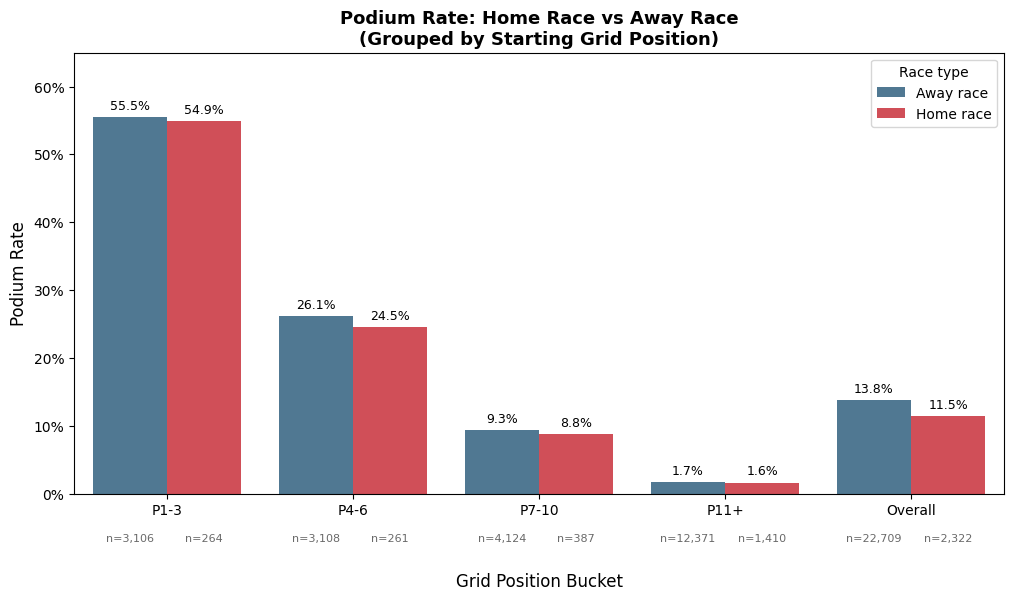


Detailed table:


,grid_bucket,label,starts,podiums,rate
8,Overall,Away race,22709,3129,0.137787
9,Overall,Home race,2322,266,0.114556
0,P1-3,Away race,3106,1725,0.555377
1,P1-3,Home race,264,145,0.549242
2,P11+,Away race,12371,207,0.016733
3,P11+,Home race,1410,23,0.016312
4,P4-6,Away race,3108,812,0.261261
5,P4-6,Home race,261,64,0.245211
6,P7-10,Away race,4124,385,0.093356
7,P7-10,Home race,387,34,0.087855


In [137]:
# ── Compute podium rates by home/away and grid bucket ────────────────────────

home_grid = (
    res2
    .groupby(["grid_bucket", "is_home"])
    .agg(
        starts=("is_podium", "count"),
        podiums=("is_podium", "sum")
    )
    .reset_index()
)

home_grid["rate"] = (
    home_grid["podiums"] / home_grid["starts"]
)

home_grid["label"] = home_grid["is_home"].map({
    True: "Home race",
    False: "Away race"
})


# ── Overall rates (without controlling for grid) ──────────────────────────────

overall = (
    res2
    .groupby("is_home")
    .agg(
        starts=("is_podium", "count"),
        podiums=("is_podium", "sum")
    )
    .reset_index()
)

overall["rate"] = (
    overall["podiums"] / overall["starts"]
)

overall["grid_bucket"] = "Overall"

overall["label"] = overall["is_home"].map({
    True: "Home race",
    False: "Away race"
})


# ── Combine bucket and overall results ───────────────────────────────────────

combined = pd.concat(
    [home_grid, overall],
    ignore_index=True
)


# ── Visualization ─────────────────────────────────────────────────────────────

bucket_order = ["P1-3", "P4-6", "P7-10", "P11+", "Overall"]
hue_order = ["Away race", "Home race"]

fig, ax = plt.subplots(figsize=(12, 7))

palette = {
    "Away race": "#457B9D",
    "Home race": "#E63946"
}

sns.barplot(
    data=combined,
    x="grid_bucket",
    y="rate",
    hue="label",
    order=bucket_order,
    hue_order=hue_order,
    palette=palette,
    errorbar=None,
    ax=ax
)


# ── Percentage and sample-size annotations ───────────────────────────────────

for container, label in zip(ax.containers, hue_order):

    for bar, bucket in zip(container.patches, bucket_order):

        row = combined[
            (combined["grid_bucket"] == bucket)
            & (combined["label"] == label)
        ]

        if row.empty:
            continue

        row = row.iloc[0]

        x_center = bar.get_x() + bar.get_width() / 2
        height = bar.get_height()

        # Percentage above each bar
        ax.text(
            x_center,
            height + 0.007,
            f"{row['rate']:.1%}",
            ha="center",
            va="bottom",
            fontsize=9
        )

        # Sample size directly beneath the correct bar
        ax.text(
            x_center,
            -0.09,
            f"n={int(row['starts']):,}",
            ha="center",
            va="top",
            fontsize=8,
            color="dimgray",
            transform=ax.get_xaxis_transform(),
            clip_on=False
        )


# ── Format figure ─────────────────────────────────────────────────────────────

ax.yaxis.set_major_formatter(
    mtick.PercentFormatter(xmax=1)
)

ax.set_xlabel(
    "Grid Position Bucket",
    fontsize=12,
    labelpad=40
)
ax.set_ylabel("Podium Rate", fontsize=12)

ax.set_title(
    "Podium Rate: Home Race vs Away Race\n"
    "(Grouped by Starting Grid Position)",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylim(
    0,
    max(0.65, combined["rate"].max() + 0.05)
)

ax.legend(title="Race type", fontsize=10)

plt.subplots_adjust(bottom=0.25)

plt.show()


# ── Detailed results ──────────────────────────────────────────────────────────

print("\nDetailed table:")

display(
    combined[
        ["grid_bucket", "label", "starts", "podiums", "rate"]
    ]
    .sort_values(["grid_bucket", "label"])
)

### 2.2 Findings

**Grain:** Each observation represents one `(raceId, driverId)` record with a valid numbered starting-grid position. Records with missing or zero grid positions are excluded because they cannot be assigned to the selected buckets. This may exclude genuine pit-lane starters.

**Missingness:** Driver nationalities and circuit countries are standardized using mapping dictionaries. Previously unmapped nationalities were reviewed and additional mappings were introduced, reducing unnecessary data loss. Records with unresolved nationality or country information are excluded. Missing or zero grid positions are excluded separately, and exclusion counts are reported during preprocessing.

**Data Scope:** The analysis covers the available historical Formula 1 races from 1950–2024, without an additional date restriction.

**Methodology:** Podium rates are compared between home-race and away-race entries within four starting-grid buckets: P1–P3, P4–P6, P7–P10, and P11+. This reduces differences in starting position between home and away drivers. Overall rates are also calculated as an unadjusted reference.

**Overall Results:** Across 25,031 analyzed driver-race records, the overall podium rate is 13.78% for away races (3,129/22,709) compared with 11.46% for home races (266/2,322), a difference of approximately 2.32 percentage points.

**Grid-Controlled Results:** Home-race drivers have slightly lower observed podium rates across all four grid buckets:

- **P1–P3:** Away 55.54% vs. Home 54.92%.
- **P4–P6:** Away 26.13% vs. Home 24.52%.
- **P7–P10:** Away 9.34% vs. Home 8.79%.
- **P11+:** Away 1.67% vs. Home 1.63%.

**Conclusion:** After grouping drivers by starting position, the analysis does not show a clear home-race podium advantage. Away-race drivers have slightly higher observed podium rates in every grid bucket, but these differences are relatively small.

**Limitations:** Grid buckets do not perfectly control for starting position, particularly in the broad P11+ category. The analysis also does not control for driver skill, constructor performance, circuit characteristics, or historical era. Zero-grid entries are excluded, potentially omitting genuine pit-lane starters. These results describe historical associations rather than causal effects.

## 2.3 Constructor Mechanical-Retirement Rates: 2014–2021 vs. 2022–2024

**Question:** Which constructors have the highest mechanical-retirement rate in 2014–2021 vs. 2022–2024?

**Definition:** A mechanical retirement is a race start that ended early because a car component failed. Failures caused by crashes, driver errors, or regulatory decisions are excluded.

**Tables joined:**
- `results_model` (raceId, driverId, constructorId, grid, laps, statusId)
- `races` (raceId, year)
- `status` (statusId, status)
- `constructors` (constructorId, name)

**Strategy:** We classify race-result statuses as mechanical, crash-related, finished, or other. We exclude identified non-starters and calculate each constructor's mechanical-retirement rate as mechanical retirements divided by estimated race starts.

**Grain:** One observation per `(raceId, driverId)` for an identified race starter.

**Missingness:** Missing statuses and ambiguous retirement causes are checked and reported. Uncertain causes are not automatically classified as mechanical.

**Data Scope:** Only races from 2014–2024 are included, divided into the two periods specified in the question.

**Limitations:** Status descriptions may not reveal whether component damage was caused by an independent failure or an accident. Race starts are identified using grid positions, recorded laps, and status information.

In [138]:
# ── Audit statuses used during 2014–2024 ───────────────────────────────

status = clean_data["status"].copy()

status_audit = (
    results_model[["raceId", "statusId"]]
    .merge(
        races[["raceId", "year"]],
        on="raceId",
        validate="many_to_one"
    )
    .query("2014 <= year <= 2024")
    .merge(
        status[["statusId", "status"]],
        on="statusId",
        validate="many_to_one"
    )
)

status_counts = (
    status_audit
    .groupby(["statusId", "status"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

print(status_counts.to_string(index=False))

 statusId           status  count
        1         Finished   2403
       11           +1 Lap   1178
       12          +2 Laps    208
        4        Collision    150
        3         Accident     85
        5           Engine     81
      130 Collision damage     59
       31          Retired     50
       23           Brakes     49
      131       Power Unit     42
        6          Gearbox     42
       22       Suspension     25
       13          +3 Laps     24
        9       Hydraulics     15
       10       Electrical     14
       54         Withdrew     14
       75       Power loss     13
        2     Disqualified     11
       20         Spun off     11
       36            Wheel     11
       44         Oil leak     10
       25      Overheating      8
       29         Puncture      7
       34   Water pressure      7
       26       Mechanical      7
       14          +4 Laps      6
      101            Turbo      6
       84          Battery      5
       43     

In [139]:
# ── Classify statuses using audited status IDs ───────────────────────────────

MECHANICAL_IDS = {
    5, 6, 7, 8, 9, 10,
    21, 23, 24, 25, 26,
    30, 32, 34, 37, 38,
    39, 40, 43, 44, 47,
    48, 51, 69, 75, 76,
    79, 84, 95, 101, 103,
    105, 131, 132, 141
}

AMBIGUOUS_IDS = {
    22, 33, 36, 61, 65, 135, 136, 140
}

CRASH_IDS = {3, 4, 20, 130, 137, 138}

status_classified = status[["statusId", "status"]].copy()

status_classified["category"] = "Other"

# Mechanical failures
status_classified.loc[
    status_classified["statusId"].isin(MECHANICAL_IDS),
    "category"
] = "Mechanical"

# Ambiguous component-related cases
status_classified.loc[
    status_classified["statusId"].isin(AMBIGUOUS_IDS),
    "category"
] = "Ambiguous"

# Crashes and collision-related outcomes
status_classified.loc[
    status_classified["statusId"].isin(CRASH_IDS),
    "category"
] = "Crash/Collision"

# Completed races, including lapped drivers
status_classified.loc[
    status_classified["status"].eq("Finished")
    | status_classified["status"].str.match(r"^\+\d+ Laps?$", na=False),
    "category"
] = "Finished"

# Summarize classifications
status_summary = status_counts.merge(
    status_classified[["statusId", "category"]],
    on="statusId",
    how="left",
    validate="many_to_one"
)

display(
    status_summary.groupby("category")
    .agg(
        status_types=("statusId", "count"),
        race_records=("count", "sum")
    )
)

,status_types,race_records
category,,
Ambiguous,8,51
Crash/Collision,6,308
Finished,9,3825
Mechanical,35,351
Other,8,91


In [140]:
# ── Build analysis DataFrame ─────────────────────────────────────────────────

res3 = results_model[
    ["raceId", "driverId", "constructorId", "grid", "laps", "statusId"]
].copy()

res3 = res3.merge(
    races[["raceId", "year"]],
    on="raceId",
    how="inner",
    validate="many_to_one"
)

# Keep only the requested years
res3 = res3[res3["year"].between(2014, 2024)].copy()

res3 = res3.merge(
    status_classified,
    on="statusId",
    how="left",
    validate="many_to_one"
)

res3 = res3.merge(
    clean_data["constructors"][["constructorId", "name"]].rename(
        columns={"name": "constructor_name"}
    ),
    on="constructorId",
    how="left",
    validate="many_to_one"
)

# ── Validate joins ───────────────────────────────────────────────────────────

assert not res3.duplicated(["raceId", "driverId"]).any()

print("Missing statuses:", res3["status"].isna().sum())
print("Missing constructors:", res3["constructor_name"].isna().sum())

assert res3["status"].notna().all()
assert res3["constructor_name"].notna().all()


# ── Identify race starters ───────────────────────────────────────────────────

before = len(res3)

print(
    "Zero-lap withdrawals:",
    ((res3["status"] == "Withdrew") & (res3["laps"] == 0)).sum()
)

res3 = res3[
    ((res3["grid"] > 0) | (res3["laps"] > 0))
    & ~((res3["status"] == "Withdrew") & (res3["laps"] == 0))
].copy()

print(f"Records excluded: {before - len(res3):,}")
print(f"Estimated race starts: {len(res3):,}")


# ── Inspect retirement classifications ──────────────────────────────────────

print("\nStatus breakdown:")
display(
    res3.groupby(["status", "category"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)


# ── Create mechanical retirement indicator ──────────────────────────────────

res3["is_mechanical"] = res3["category"] == "Mechanical"


# ── Split into two eras ──────────────────────────────────────────────────────

era_2014_2021 = res3[res3["year"].between(2014, 2021)].copy()
era_2022_2024 = res3[res3["year"].between(2022, 2024)].copy()


# ── Compute rates ────────────────────────────────────────────────────────────

def compute_mech_rate(df, era_label):

    agg = (
        df.groupby("constructor_name")
        .agg(
            starts=("driverId", "count"),
            mech_retirements=("is_mechanical", "sum")
        )
        .reset_index()
    )

    agg["mech_rate"] = agg["mech_retirements"] / agg["starts"]
    agg["era"] = era_label

    return agg


mech_a = compute_mech_rate(era_2014_2021, "2014–2021")
mech_b = compute_mech_rate(era_2022_2024, "2022–2024")


# ── Minimum sample-size threshold ───────────────────────────────────────────

MIN_STARTS = 30

mech_a_filt = mech_a[mech_a["starts"] >= MIN_STARTS].copy()
mech_b_filt = mech_b[mech_b["starts"] >= MIN_STARTS].copy()

print(f"\nConstructors in 2014–2021 (≥30 starts): {len(mech_a_filt)}")
print(f"Constructors in 2022–2024 (≥30 starts): {len(mech_b_filt)}")

print("\n2014–2021 ranking:")
display(mech_a_filt.sort_values("mech_rate", ascending=False))

print("\n2022–2024 ranking:")
display(mech_b_filt.sort_values("mech_rate", ascending=False))

Missing statuses: 0
Missing constructors: 0
Zero-lap withdrawals: 11
Records excluded: 15
Estimated race starts: 4,611

Status breakdown:


,status,category,count
28,Finished,Finished,2403
0,+1 Lap,Finished,1178
1,+2 Laps,Finished,208
13,Collision,Crash/Collision,150
8,Accident,Crash/Collision,85
...,...,...,...
21,Drivetrain,Mechanical,1
48,Spark plugs,Mechanical,1
47,Seat,Ambiguous,1
39,Out of fuel,Other,1



Constructors in 2014–2021 (≥30 starts): 19
Constructors in 2022–2024 (≥30 starts): 12

2014–2021 ranking:


,constructor_name,starts,mech_retirements,mech_rate,era
4,Caterham,34,6,0.176471,2014–2021
8,Lotus F1,75,13,0.173333,2014–2021
17,Toro Rosso,242,35,0.144628,2014–2021
11,McLaren,319,42,0.131661,2014–2021
15,Renault,200,25,0.125000,2014–2021
16,Sauber,200,21,0.105000,2014–2021
14,Red Bull,319,32,0.100313,2014–2021
13,Racing Point,76,6,0.078947,2014–2021
7,Haas F1 Team,242,17,0.070248,2014–2021
2,Alpine F1 Team,44,3,0.068182,2014–2021



2022–2024 ranking:


,constructor_name,starts,mech_retirements,mech_rate,era
0,Alfa Romeo,88,11,0.125000,2022–2024
2,Alpine F1 Team,136,15,0.110294,2022–2024
1,AlphaTauri,88,5,0.056818,2022–2024
11,Williams,134,7,0.052239,2022–2024
4,Ferrari,135,7,0.051852,2022–2024
5,Haas F1 Team,135,6,0.044444,2022–2024
7,Mercedes,136,6,0.044118,2022–2024
8,RB F1 Team,48,2,0.041667,2022–2024
3,Aston Martin,134,5,0.037313,2022–2024
6,McLaren,136,5,0.036765,2022–2024


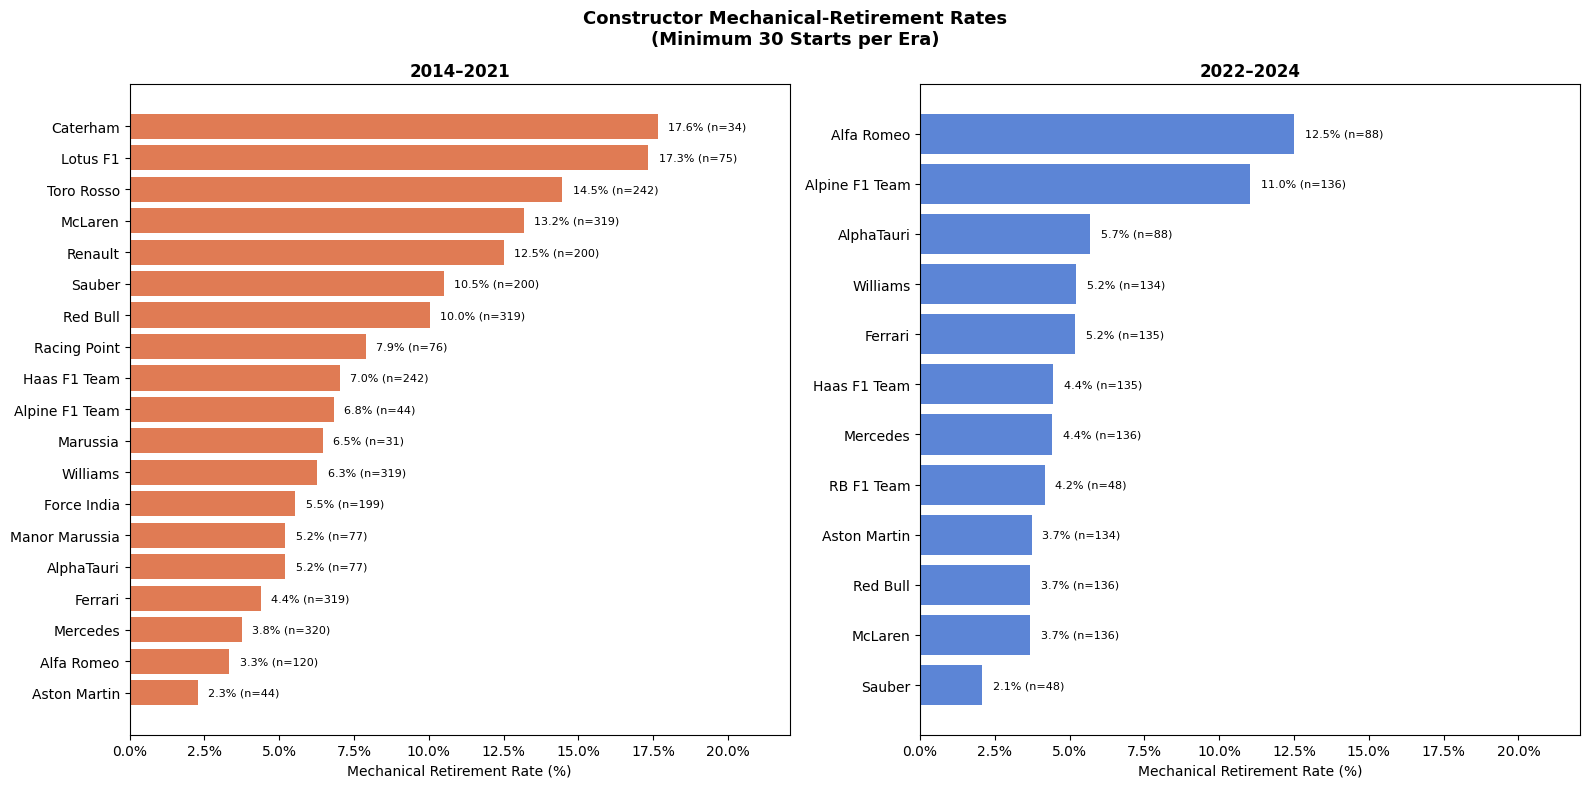


Constructors competing in BOTH eras:


,constructor_name,mech_rate_2014_21,mech_rate_2022_24,delta
6,McLaren,0.131661,0.036765,-0.094897
9,Sauber,0.105000,0.020833,-0.084167
8,Red Bull,0.100313,0.036765,-0.063549
5,Haas F1 Team,0.070248,0.044444,-0.025803
10,Williams,0.062696,0.052239,-0.010457
1,AlphaTauri,0.051948,0.056818,0.004870
7,Mercedes,0.037500,0.044118,0.006618
4,Ferrari,0.043887,0.051852,0.007965
3,Aston Martin,0.022727,0.037313,0.014586
2,Alpine F1 Team,0.068182,0.110294,0.042112


In [141]:
# ── Top constructors per era ─────────────────────────────────────────────────

top_a = mech_a_filt.sort_values("mech_rate", ascending=False)
top_b = mech_b_filt.sort_values("mech_rate", ascending=False)

# Same x-axis scale for fair comparison
max_rate = max(
    mech_a_filt["mech_rate"].max(),
    mech_b_filt["mech_rate"].max()
) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

for ax, df, title, color in zip(
    axes,
    [top_a, top_b],
    ["2014–2021", "2022–2024"],
    ["#E07B54", "#5C85D6"]
):
    df_plot = df.sort_values("mech_rate")

    bars = ax.barh(
        df_plot["constructor_name"],
        df_plot["mech_rate"] * 100,
        color=color
    )

    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Mechanical Retirement Rate (%)")
    ax.set_xlim(0, max_rate * 1.25)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter())

    for bar, (_, row) in zip(bars, df_plot.iterrows()):
        ax.text(
            bar.get_width() + max_rate * 0.02,
            bar.get_y() + bar.get_height() / 2,
            f"{row['mech_rate']:.1%} (n={int(row['starts'])})",
            va="center",
            fontsize=8
        )

fig.suptitle(
    "Constructor Mechanical-Retirement Rates\n"
    "(Minimum 30 Starts per Era)",
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ── Compare constructors present in both eras ───────────────────────────────

both = mech_a_filt.merge(
    mech_b_filt[["constructor_name", "mech_rate", "starts"]],
    on="constructor_name",
    suffixes=("_2014_21", "_2022_24"),
    validate="one_to_one"
)

both["delta"] = (
    both["mech_rate_2022_24"]
    - both["mech_rate_2014_21"]
)

both = both.sort_values("delta")

print("\nConstructors competing in BOTH eras:")
display(
    both[
        [
            "constructor_name",
            "mech_rate_2014_21",
            "mech_rate_2022_24",
            "delta"
        ]
    ]
)

### 2.3 Findings

**Grain:** Each observation represents one `(raceId, driverId)` record identified as a race start. We use the cleaned and deduplicated `results_model` table to ensure that each driver appears only once per race. Race starts are estimated using positive grid positions or completed racing laps, while zero-lap withdrawals are excluded.

**Missingness and Start Validation:** The analysis initially contained 4,626 driver-race records from 2014–2024. All records had matching status and constructor information, with no missing values after the joins. We identified 11 zero-lap withdrawals and applied the race-start filtering criteria, excluding 15 records in total and retaining **4,611 estimated race starts**. These exclusions are counted without double-counting records satisfying multiple exclusion conditions.

**Status Classification:** We inspected the 66 unique status types appearing during 2014–2024 and manually categorized them as:
- **Mechanical:** Clearly identified technical or component failures, such as Engine, Gearbox, Power Unit, Brakes, Hydraulics, and Electrical.
- **Crash/Collision:** Accident, Collision, Collision damage, Spun off, and other explicitly crash-related outcomes.
- **Finished:** Drivers who completed the race or were classified as finishing one or more laps behind.
- **Ambiguous:** Component-related statuses such as Suspension, Wheel, Front wing, and Rear wing, where the recorded status does not clearly establish whether damage resulted from a mechanical failure or an external incident.
- **Other:** Outcomes such as Disqualified, Withdrew, Retired, Illness, and other statuses without a confirmed mechanical cause.

Only records classified as **Mechanical** are included in the mechanical-retirement numerator. Ambiguous and other non-mechanical outcomes remain in the denominator when the driver is identified as a race starter.

**Methodology:** For each constructor, the mechanical-retirement rate is calculated as:

\[
\text{Mechanical Retirement Rate} =
\frac{\text{Mechanical Retirements}}{\text{Estimated Race Starts}}
\times 100
\]

We calculate this rate separately for **2014–2021** and **2022–2024**, corresponding to the two periods specified in the project. Constructors must have at least **30 estimated race starts within an era** to appear in the rankings. This exploratory threshold reduces the influence of extremely small samples but does not guarantee statistical reliability. The analysis includes 19 eligible constructors in 2014–2021 and 12 in 2022–2024.

**2014–2021 Results:** Caterham recorded the highest mechanical-retirement rate at **17.65% (6/34)**, closely followed by Lotus F1 at **17.33% (13/75)** and Toro Rosso at **14.46% (35/242)**. McLaren ranked fourth at **13.17% (42/319)**, followed by Renault at **12.50% (25/200)**. Although Caterham ranked first, its rate is based on only 34 starts, making it more sensitive to individual retirements than constructors with larger samples.

**2022–2024 Results:** Alfa Romeo recorded the highest mechanical-retirement rate at **12.50% (11/88)**, followed by Alpine F1 Team at **11.03% (15/136)**. The next highest rates were substantially lower: AlphaTauri at **5.68% (5/88)**, Williams at **5.22% (7/134)**, and Ferrari at **5.19% (7/135)**. This indicates a notable gap between the two highest-ranked constructors and the remaining eligible teams during this period.

**Comparison Across Eras:** For constructors appearing under the same recorded name in both periods, we calculate the change in mechanical-retirement rate as:

\[
\Delta = \text{Rate}_{2022-2024} - \text{Rate}_{2014-2021}
\]

A negative value indicates a decrease in mechanical retirements per start, while a positive value indicates an increase.

- **Largest decrease — McLaren:** Its rate fell from 13.17% to 3.68%, a decrease of **9.49 percentage points**.
- **Second-largest decrease — Sauber:** Its rate fell from 10.50% to 2.08%, a decrease of **8.42 percentage points**.
- **Red Bull:** Its rate decreased from 10.03% to 3.68%, an improvement of **6.35 percentage points**.
- **Largest increase — Alfa Romeo:** Its rate rose from 3.33% to 12.50%, an increase of **9.17 percentage points**.
- **Alpine F1 Team:** Its rate increased from 6.82% to 11.03%, a rise of **4.21 percentage points**.

**Overall Interpretation:** The constructors with the highest observed mechanical-retirement rates differ between the two periods. Caterham, Lotus F1, and Toro Rosso ranked highest in 2014–2021, whereas Alfa Romeo and Alpine F1 Team ranked highest in 2022–2024. Among constructors represented under the same name in both eras, McLaren and Sauber showed the largest decreases in mechanical-retirement rates, while Alfa Romeo and Alpine showed the largest increases. These results demonstrate changes in recorded reliability patterns across constructors and historical periods.

**Limitations:** Race starts are estimated from grid positions, completed laps, and withdrawal statuses rather than independently verified starting records. Some mechanical-looking component statuses may result from collision damage, so ambiguous cases are excluded from the mechanical numerator, potentially underestimating certain constructors' mechanical-retirement rates. Conversely, a technical status does not always establish the underlying cause with certainty. The minimum 30-start requirement reduces very small samples but does not eliminate sampling uncertainty. Constructor renaming is not reconciled across eras, meaning teams operating under different recorded names are treated separately. Finally, these results are descriptive and cannot establish that the 2022 regulation changes caused the observed differences in mechanical reliability.

# 3. Feature Selection & Engineering

The modeling task is to **predict whether a driver will finish on the podium
(positions 1Ã¢â‚¬â€œ3) in a given race**, using only information available after qualifying and before the race starts.

## 3.0 Modeling Grain and Target

- **Unit of analysis:** One row per `(raceId, driverId)` race entry.
- **Target variable:** `is_podium`, equal to 1 for finishing positions 1-3.
- **Training period:** 2003‚-2019.
- **Validation period:** 2020-2021.
- **Test period:** 2022 onward.

All engineered features must be available before the race and must not use
current-race finishing information, lap times, pit stops, or other in-race
data.

## 3.1 Feature Construction

| Group | Features | Rationale |
|---|---|---|
| **Qualifying** | `quali_pos`, `grid`, `grid_penalty` | Starting position and qualifying-to-grid movement |
| **Driver recent form** | `driver_podium_rate_last10`, `driver_avg_finish_last10` | Driver performance in previous races |
| **Constructor strength** | `constructor_podium_rate_season`, `constructor_avg_finish_season` | Constructor performance in earlier races of the same season |
| **Circuit history** | `driver_circuit_podium_rate` | Driver's previous podium performance at the circuit |
| **Race context** | `year`, `round`, `is_home_race` | Temporal, calendar, and home-race context |

**Feature-selection strategy:** The initial 11 features were selected
using Formula 1 domain knowledge and hypotheses about qualifying,
driver performance, constructor competitiveness, circuit history,
and race context.

Their relevance is investigated using training-period EDA,
correlations, and validation-period permutation importance.

The final predictive models use 10 features, excluding `year`,
which is retained for chronological splitting and historical analysis.

In [142]:
#  Base dataframe for feature engineering 
# Start from the cleaned, deduplicated results table.

race_meta = races[
    ["raceId", "year", "round", "circuitId", "date"]
].copy()

# Each race must have exactly one metadata record.
assert race_meta["raceId"].is_unique

base = results_model.merge(
    race_meta,
    on="raceId",
    how="inner",
    validate="many_to_one",
)

# Validate date type from Part 1.
assert pd.api.types.is_datetime64_any_dtype(base["date"])



qual2 = qualifying[
    ["raceId", "driverId", "position"]
].rename(columns={"position": "quali_pos"})

assert not qual2.duplicated(["raceId", "driverId"]).any()

base = base.merge(
    qual2,
    on=["raceId", "driverId"],
    how="left",
    validate="many_to_one",
)



for col in ["position", "grid", "quali_pos", "positionOrder"]:
    assert pd.api.types.is_numeric_dtype(base[col]), (
        f"{col} must be numeric"
    )

# PositionOrder must exist because it defines the target.
assert base["positionOrder"].notna().all()

# Missing position, qualifying position, and grid values are allowed here.
# Their treatment is handled later in the pipeline.



base["is_podium"] = (
    base["positionOrder"] <= 3
).astype(int)



# Positive: driver started further back than qualifying position.
# Negative: driver started further forward.

base["grid_penalty"] = base["grid"] - base["quali_pos"]


#Sort chronologically 
base = base.sort_values(
    ["date", "raceId", "driverId"]
).reset_index(drop=True)



assert not base.duplicated(["raceId", "driverId"]).any()

assert base[
    ["raceId", "year", "round", "circuitId", "date"]
].notna().all().all()

assert base["is_podium"].isin([0, 1]).all()


print(f"Base frame shape: {base.shape}")

print(
    base[
        [
            "raceId",
            "year",
            "round",
            "driverId",
            "constructorId",
            "grid",
            "quali_pos",
            "grid_penalty",
            "is_podium",
        ]
    ].head(10)
)

Base frame shape: (26668, 26)
   raceId  year  round  driverId  constructorId  grid  quali_pos  \
0     833  1950      1       579             51     3        NaN   
1     833  1950      1       589            105    11        NaN   
2     833  1950      1       619            151    13        NaN   
3     833  1950      1       627            154     9        NaN   
4     833  1950      1       640            105     8        NaN   
5     833  1950      1       642             51     1        NaN   
6     833  1950      1       660            154    21        NaN   
7     833  1950      1       661            151    10        NaN   
8     833  1950      1       666            151    10        NaN   
9     833  1950      1       669            105     5        NaN   

   grid_penalty  is_podium  
0           NaN          0  
1           NaN          0  
2           NaN          0  
3           NaN          0  
4           NaN          0  
5           NaN          1  
6           NaN   

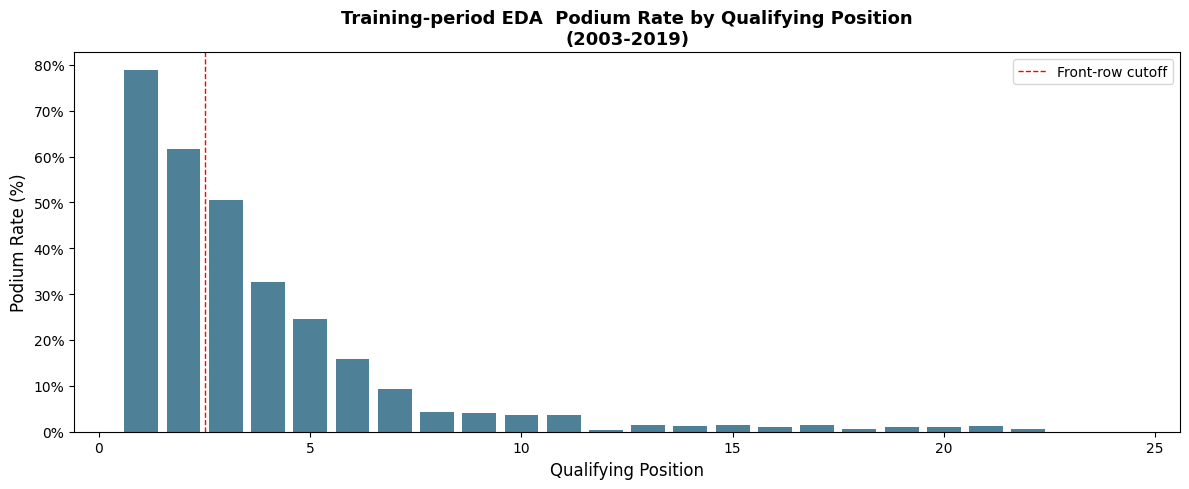

Training observations used: 6808
 quali_pos  starts  podium_rate
       1.0     321     0.788162
       2.0     321     0.616822
       3.0     321     0.504673
       4.0     321     0.327103
       5.0     321     0.246106
       6.0     321     0.158879
       7.0     321     0.093458
       8.0     321     0.043614
       9.0     321     0.040498
      10.0     321     0.037383
      11.0     321     0.037383
      12.0     321     0.003115
      13.0     321     0.015576
      14.0     321     0.012461
      15.0     321     0.015576


In [143]:
# Feature 1: Qualifying position 
# EDA is restricted to the training period so validation and test outcomes
# cannot influence feature-selection decisions.

TRAIN_START_YEAR = 2003
TRAIN_END_YEAR = 2019

eda_q_source = base.loc[
    base["year"].between(TRAIN_START_YEAR, TRAIN_END_YEAR)
].dropna(subset=["quali_pos"]).copy()

assert not eda_q_source.empty
assert eda_q_source["year"].between(
    TRAIN_START_YEAR, TRAIN_END_YEAR
).all()

eda_q = (
    eda_q_source
    .groupby("quali_pos")
    .agg(
        starts=("is_podium", "count"),
        podiums=("is_podium", "sum"),
    )
    .reset_index()
)

eda_q["podium_rate"] = eda_q["podiums"] / eda_q["starts"]
eda_q = eda_q[eda_q["starts"] >= 20].copy()

assert eda_q["quali_pos"].notna().all()
assert eda_q["podium_rate"].between(0, 1).all()

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(
    eda_q["quali_pos"],
    eda_q["podium_rate"] * 100,
    color="#4E8098",
)
ax.set_xlabel("Qualifying Position", fontsize=12)
ax.set_ylabel("Podium Rate (%)", fontsize=12)
ax.set_title(
    "Training-period EDA  Podium Rate by Qualifying Position\n"
    "(2003-2019)",
    fontsize=13,
    fontweight="bold",
)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.axvline(
    2.5,
    color="red",
    linestyle="--",
    linewidth=1,
    label="Front-row cutoff",
)
ax.legend()
plt.tight_layout()
plt.show()

print(
    "Training observations used:",
    len(eda_q_source),
)
print(
    eda_q[
        ["quali_pos", "starts", "podium_rate"]
    ].head(15).to_string(index=False)
)

In [144]:
#  Features 2 & 3: Driver rolling form 
# Each driver's rolling values use only earlier race entries.
# The current race is excluded from the historical window.

def rolling_driver_stats(df, window=10):
    df = df.sort_values(
        ["driverId", "date", "raceId"]
    ).copy()

    df["driver_podium_rate_last10"] = np.nan
    df["driver_avg_finish_last10"] = np.nan

    for driver_id, grp in df.groupby("driverId"):
        idx = grp.index.tolist()

        for i, row_idx in enumerate(idx):
            past = grp.iloc[max(0, i - window):i]

            if len(past) == 0:
                continue

            df.at[row_idx, "driver_podium_rate_last10"] = (
                past["is_podium"].mean()
            )
            df.at[row_idx, "driver_avg_finish_last10"] = (
                pd.to_numeric(
                    past["positionOrder"],
                    errors="coerce",
                ).mean()
            )

    return df


print("Computing rolling driver stats...")
base = rolling_driver_stats(base)
print("Done.")

# Validation 1: the first observed race for every driver has no history.
driver_ordered = base.sort_values(
    ["driverId", "date", "raceId"]
)

first_driver_rows = (
    driver_ordered
    .groupby("driverId", sort=False)
    .head(1)
)

assert first_driver_rows[
    [
        "driver_podium_rate_last10",
        "driver_avg_finish_last10",
    ]
].isna().all().all()

# Validation 2: every non-initial value equals a calculation from
# previous races only, never the current race.
for driver_id, grp in driver_ordered.groupby("driverId"):
    grp = grp.reset_index(drop=True)

    for i in range(1, len(grp)):
        past = grp.iloc[max(0, i - 10):i]

        expected_podium_rate = past["is_podium"].mean()
        expected_avg_finish = pd.to_numeric(
            past["positionOrder"],
            errors="coerce",
        ).mean()

        actual_podium_rate = grp.loc[
            i, "driver_podium_rate_last10"
        ]
        actual_avg_finish = grp.loc[
            i, "driver_avg_finish_last10"
        ]

        assert np.isclose(
            actual_podium_rate,
            expected_podium_rate,
            equal_nan=True,
        )
        assert np.isclose(
            actual_avg_finish,
            expected_avg_finish,
            equal_nan=True,
        )

print(
    "driver_podium_rate_last10  missing:",
    f"{base['driver_podium_rate_last10'].isna().sum():,}",
    f"({base['driver_podium_rate_last10'].isna().mean():.1%})",
)
print("Validated: rolling values use previous races only.")

Computing rolling driver stats...
Done.
driver_podium_rate_last10  missing: 861 (3.2%)
Validated: rolling values use previous races only.


A maximum ten-race window emphasizes recent performance. Drivers with fewer than ten previous races use all available historical observations; first-time drivers have missing historical form.

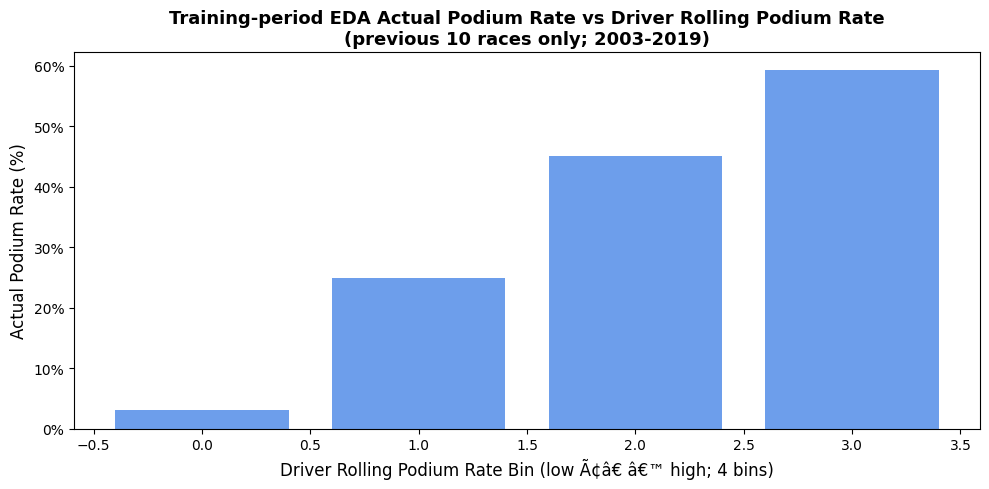

Training observations used: 6,756
Requested bins: 10
Actual bins produced: 4
Spearman relationship between bin mean and actual podium rate: 1.000
 drp_bin  starts  podiums  avg_rate  podium_rate
       0    4844      153  0.014533     0.031585
       1     719      179  0.241361     0.248957
       2     550      248  0.451212     0.450909
       3     643      381  0.724106     0.592535


In [145]:
#  EDA: rolling driver podium rate vs actual podium outcome 
# This EDA is restricted to training years. qcut may produce fewer than
# ten bins when many rolling rates have identical values.

base_eda = base.loc[
    base["year"].between(TRAIN_START_YEAR, TRAIN_END_YEAR)
].dropna(
    subset=["driver_podium_rate_last10"]
).copy()

assert not base_eda.empty
assert base_eda["year"].between(
    TRAIN_START_YEAR,
    TRAIN_END_YEAR,
).all()

n_unique_rates = base_eda[
    "driver_podium_rate_last10"
].nunique()

n_requested_bins = min(10, n_unique_rates)

assert n_requested_bins >= 1

base_eda["drp_bin"] = pd.qcut(
    base_eda["driver_podium_rate_last10"],
    q=n_requested_bins,
    labels=False,
    duplicates="drop",
)

decile_stats = (
    base_eda
    .groupby("drp_bin", observed=True)
    .agg(
        starts=("is_podium", "count"),
        podiums=("is_podium", "sum"),
        avg_rate=("driver_podium_rate_last10", "mean"),
    )
    .reset_index()
)

decile_stats["podium_rate"] = (
    decile_stats["podiums"] / decile_stats["starts"]
)

actual_bin_count = decile_stats["drp_bin"].nunique()

assert 1 <= actual_bin_count <= 10
assert decile_stats["podium_rate"].between(0, 1).all()

# Quantify the relationship shown in the chart without assuming that it is
# perfectly monotonic.
if actual_bin_count >= 2:
    spearman_relationship = decile_stats[
        ["avg_rate", "podium_rate"]
    ].corr(method="spearman").iloc[0, 1]
else:
    spearman_relationship = np.nan

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(
    decile_stats["drp_bin"],
    decile_stats["podium_rate"] * 100,
    color="#6D9EEB",
)
ax.set_xlabel(
    f"Driver Rolling Podium Rate Bin "
    f"(low Ã¢â€ â€™ high; {actual_bin_count} bins)",
    fontsize=12,
)
ax.set_ylabel("Actual Podium Rate (%)", fontsize=12)
ax.set_title(
    "Training-period EDA Actual Podium Rate vs "
    "Driver Rolling Podium Rate\n"
    "(previous 10 races only; 2003-2019)",
    fontsize=13,
    fontweight="bold",
)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
plt.tight_layout()
plt.show()

print(f"Training observations used: {len(base_eda):,}")
print(f"Requested bins: {n_requested_bins}")
print(f"Actual bins produced: {actual_bin_count}")
print(
    f"Spearman relationship between bin mean and actual podium rate: "
    f"{spearman_relationship:.3f}"
    if pd.notna(spearman_relationship)
    else "Spearman relationship unavailable: only one bin was produced."
)
print(decile_stats.to_string(index=False))

In [146]:
# ‚¬ Features 4 & 5: Constructor season-to-date form 
# Historical constructor statistics exclude the current race.

def constructor_ytd_stats(df):
    race_stats = (
        df.groupby(
            ["year", "constructorId", "raceId"],
            as_index=False,
        )
        .agg(
            round=("round", "first"),
            date=("date", "first"),
            starts=("is_podium", "size"),
            podiums=("is_podium", "sum"),
            finish_sum=("positionOrder", "sum"),
        )
        .sort_values(
            ["year", "constructorId", "date", "round", "raceId"]
        )
    )

    constructor_groups = race_stats.groupby(
        ["year", "constructorId"],
        sort=False,
    )

    # Cumulative values include the current race temporarily.
    for col in ["starts", "podiums", "finish_sum"]:
        race_stats[f"{col}_prior"] = (
            constructor_groups[col].cumsum()
            - race_stats[col]
        )

    race_stats["constructor_podium_rate_season"] = (
        race_stats["podiums_prior"]
        / race_stats["starts_prior"].replace(0, np.nan)
    )

    race_stats["constructor_avg_finish_season"] = (
        race_stats["finish_sum_prior"]
        / race_stats["starts_prior"].replace(0, np.nan)
    )

    lookup = race_stats[
        [
            "year",
            "constructorId",
            "raceId",
            "constructor_podium_rate_season",
            "constructor_avg_finish_season",
        ]
    ]

    assert not lookup.duplicated(
        ["year", "constructorId", "raceId"]
    ).any()

    return df.merge(
        lookup,
        on=["year", "constructorId", "raceId"],
        how="left",
        validate="many_to_one",
    )


base = constructor_ytd_stats(base)

# Validation: the first race for every constructor-season has no history.
constructor_race_order = (
    base[
        [
            "year",
            "constructorId",
            "raceId",
            "date",
            "round",
            "constructor_podium_rate_season",
            "constructor_avg_finish_season",
        ]
    ]
    .drop_duplicates(["year", "constructorId", "raceId"])
    .sort_values(
        ["year", "constructorId", "date", "round", "raceId"]
    )
)

first_constructor_races = (
    constructor_race_order
    .groupby(["year", "constructorId"], sort=False)
    .head(1)
)

assert first_constructor_races[
    [
        "constructor_podium_rate_season",
        "constructor_avg_finish_season",
    ]
].isna().all().all()

# Validation: subsequent values use only earlier races in the same
# constructor-season.
for (year, constructor_id), grp in constructor_race_order.groupby(
    ["year", "constructorId"],
    sort=False,
):
    grp = grp.reset_index(drop=True)

    for i in range(1, len(grp)):
        prior = grp.iloc[:i]

        # Get the subset of rows for this constructor's past races this year
        prior_base_rows = base.loc[
            base["raceId"].isin(prior["raceId"])
            & (base["constructorId"] == constructor_id)
            & (base["year"] == year)
        ]
        
        prior_starts = len(prior_base_rows) # Correctly counts past driver entries
        prior_podiums = prior_base_rows["is_podium"].sum()

        expected_rate = prior_podiums / prior_starts

        actual_rate = grp.loc[
            i,
            "constructor_podium_rate_season",
        ]

        assert np.isclose(actual_rate, expected_rate)

print("Validated constructor season-to-date chronology.")

Validated constructor season-to-date chronology.


In [147]:
#  Feature 6: Driver-circuit historical podium rate 
# The current race is excluded. Only earlier appearances by the same driver
# at the same circuit are used.

def driver_circuit_rate(df):
    df = df.sort_values(
        ["driverId", "circuitId", "date", "raceId"]
    ).copy()

    df["driver_circuit_podium_rate"] = np.nan

    for (driver_id, circuit_id), grp in df.groupby(
        ["driverId", "circuitId"],
        sort=False,
    ):
        idx = grp.index.tolist()

        for i, row_idx in enumerate(idx):
            prior = grp.iloc[:i]

            if prior.empty:
                continue

            df.at[row_idx, "driver_circuit_podium_rate"] = (
                prior["is_podium"].mean()
            )

    return df


print("Computing driver-circuit historical rates...")
base = driver_circuit_rate(base)
print("Done.")

driver_circuit_order = base.sort_values(
    ["driverId", "circuitId", "date", "raceId"]
)

# Validation: the first appearance for every driver-circuit pair has
# no historical value.
first_circuit_appearances = (
    driver_circuit_order
    .groupby(["driverId", "circuitId"], sort=False)
    .head(1)
)

assert first_circuit_appearances[
    "driver_circuit_podium_rate"
].isna().all()

# Validation: every later appearance uses only prior appearances.
for (driver_id, circuit_id), grp in driver_circuit_order.groupby(
    ["driverId", "circuitId"],
    sort=False,
):
    grp = grp.reset_index(drop=True)

    for i in range(1, len(grp)):
        prior = grp.iloc[:i]
        expected_rate = prior["is_podium"].mean()
        actual_rate = grp.loc[
            i,
            "driver_circuit_podium_rate",
        ]

        assert np.isclose(actual_rate, expected_rate)

print(
    "driver_circuit_podium_rate Ã¢â‚¬â€ missing:",
    f"{base['driver_circuit_podium_rate'].isna().sum():,}",
    f"({base['driver_circuit_podium_rate'].isna().mean():.1%})",
)
print("Validated: driver-circuit rates use earlier visits only.")

Computing driver-circuit historical rates...
Done.
driver_circuit_podium_rate Ã¢â‚¬â€ missing: 8,176 (30.7%)
Validated: driver-circuit rates use earlier visits only.


In [148]:
# Feature 7: Home-race flag 
# Unknown driver or circuit countries remain missing rather than being
# incorrectly classified as away races.

circuit_country_lookup = circuits_c[
    ["circuitId", "circuit_country"]
].drop_duplicates("circuitId")

driver_country_lookup = drivers_c[
    ["driverId", "driver_country"]
].drop_duplicates("driverId")

assert circuit_country_lookup["circuitId"].is_unique
assert driver_country_lookup["driverId"].is_unique

base = base.merge(
    circuit_country_lookup,
    on="circuitId",
    how="left",
    validate="many_to_one",
)

base = base.merge(
    driver_country_lookup,
    on="driverId",
    how="left",
    validate="many_to_one",
)

known_countries = (
    base["driver_country"].notna()
    & base["circuit_country"].notna()
)

base["is_home_race"] = np.nan
base.loc[known_countries, "is_home_race"] = (
    base.loc[known_countries, "driver_country"]
    == base.loc[known_countries, "circuit_country"]
).astype(float)

# Validation: known matches are home, known mismatches are away, and
# unknown country information remains missing.
known_home = (
    known_countries
    & (
        base["driver_country"]
        == base["circuit_country"]
    )
)

known_away = (
    known_countries
    & (
        base["driver_country"]
        != base["circuit_country"]
    )
)

unknown_country = ~known_countries

assert (base.loc[known_home, "is_home_race"] == 1).all()
assert (base.loc[known_away, "is_home_race"] == 0).all()
assert base.loc[unknown_country, "is_home_race"].isna().all()

print("is_home_race value counts including unknown:")
print(base["is_home_race"].value_counts(dropna=False))

is_home_race value counts including unknown:
is_home_race
0.0    24176
1.0     2490
NaN        2
Name: count, dtype: int64


In [149]:
# Assemble the modeling feature matrix.
# All historical features were calculated from races strictly earlier than the
# current race; current-race outcomes are not available to the predictor.
FEATURE_COLS = [
    "quali_pos",
    "grid",
    "grid_penalty",
    "driver_podium_rate_last10",
    "driver_avg_finish_last10",
    "constructor_podium_rate_season",
    "constructor_avg_finish_season",
    "driver_circuit_podium_rate",
    "year",
    "round",
    "is_home_race",
]

TARGET_COL = "is_podium"

assert len(FEATURE_COLS) == 11
assert "circuit_podium_rate_grid_bucket" not in FEATURE_COLS
assert set(FEATURE_COLS).issubset(base.columns)

df_model = base[
    ["raceId", "driverId", "constructorId", "date"]
    + FEATURE_COLS
    + [TARGET_COL]
].copy()

assert not df_model.duplicated(["raceId", "driverId"]).any()
print(f"Total modeling rows before missing-value handling: {len(df_model):,}")
print("Missing values are retained here; columns/values are handled after the chronological split.")


Total modeling rows before missing-value handling: 26,668
Missing values are retained here; columns/values are handled after the chronological split.


### Missing-Value Handling Strategy

The modeling table starts with the unique driver-race rows produced by the shared-drive resolution (Section 1.8).
Modeling begins in 2003 because historical qualifying coverage is much more complete from then on, so earlier seasons are
excluded by season, not by dropping individual rows.

Within the modeling period, rows with a missing qualifying position, starting grid or historical feature are **retained**.
Dropping them would discard valid observations, and the missingness is concentrated in particular situations: rookies and
drivers at a circuit for the first time have no history, constructors have no earlier races at the start of a season, and a
small number of entries have no recorded qualifying time.

The affected features are `quali_pos`, `grid_penalty`, `driver_podium_rate_last10`, `driver_avg_finish_last10`,
`constructor_podium_rate_season`, `constructor_avg_finish_season` and `driver_circuit_podium_rate`.

Missing values are filled **after** the chronological split with a median imputer fitted on the training seasons only, then
applied unchanged to validation and test rows, so later seasons cannot influence the replacement values. Median imputation
is a baseline choice; the preprocessing experiments in Section 5 compare it with adding missingness indicators using
validation data only.

In [150]:
#  Missingness audit by modeling period 

periods = {
    "Training (2003-2019)": (2003, 2019),
    "Validation (2020-2021)": (2020, 2021),
    "Test (2022-2024)": (2022, 2024),
}

missingness_rows = []

for period_name, (start_year, end_year) in periods.items():

    period_df = df_model[
        df_model["year"].between(start_year, end_year)
    ]

    for feature in FEATURE_COLS:

        missingness_rows.append({
            "Period": period_name,
            "Feature": feature,
            "Total Rows": len(period_df),
            "Missing": period_df[feature].isna().sum(),
            "Missing (%)": round(
                period_df[feature].isna().mean() * 100,
                2
            ),
        })

missingness_table = pd.DataFrame(missingness_rows)

display(
    missingness_table.sort_values(
        ["Period", "Missing (%)"],
        ascending=[True, False]
    )
)

,Period,Feature,Total Rows,Missing,Missing (%)
29,Test (2022-2024),driver_circuit_podium_rate,1359,167,12.29
27,Test (2022-2024),constructor_podium_rate_season,1359,60,4.42
28,Test (2022-2024),constructor_avg_finish_season,1359,60,4.42
25,Test (2022-2024),driver_podium_rate_last10,1359,8,0.59
26,Test (2022-2024),driver_avg_finish_last10,1359,8,0.59
22,Test (2022-2024),quali_pos,1359,0,0.00
23,Test (2022-2024),grid,1359,0,0.00
24,Test (2022-2024),grid_penalty,1359,0,0.00
30,Test (2022-2024),year,1359,0,0.00
31,Test (2022-2024),round,1359,0,0.00


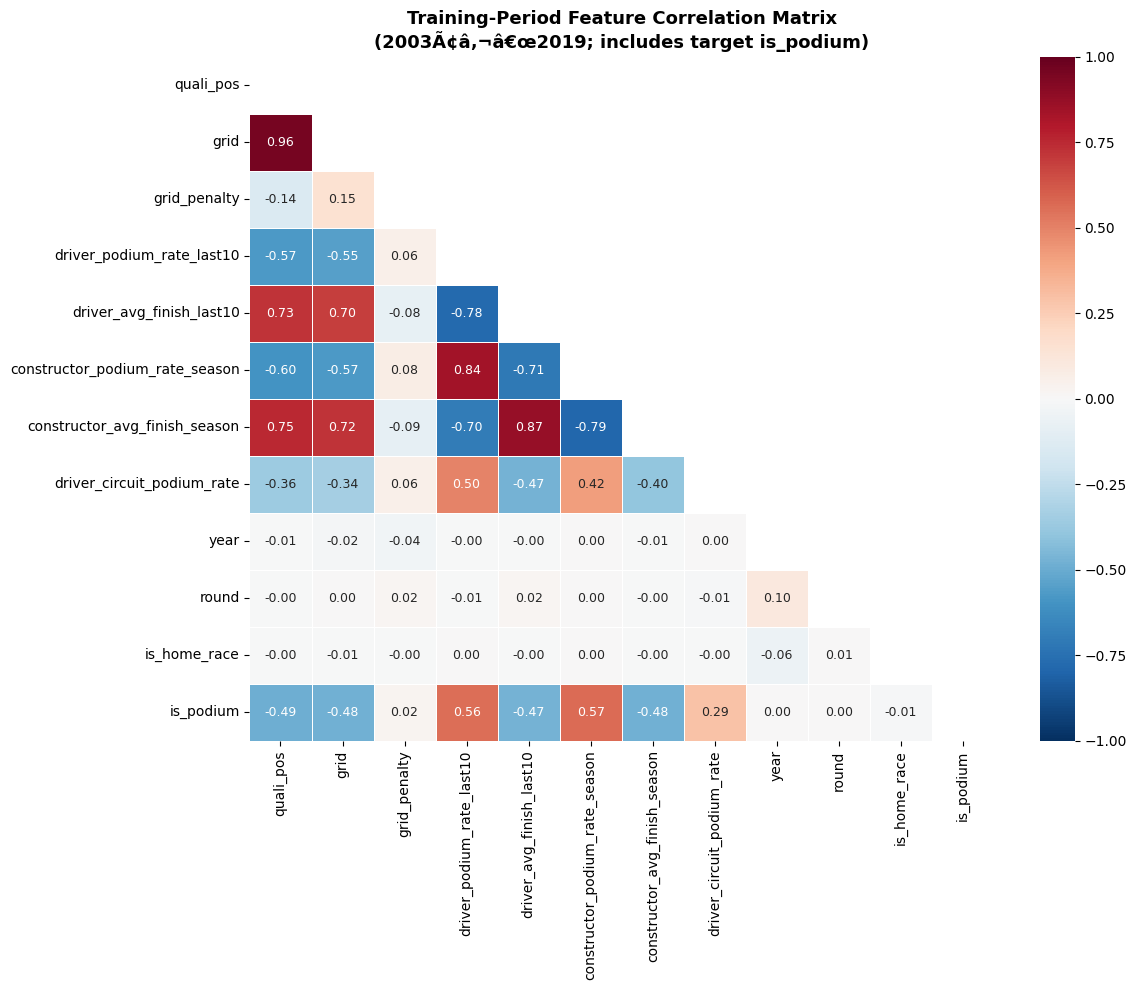

Correlation observations used: 6,831
Correlation year range: 2003Ã¢â‚¬â€œ2019

Correlation with is_podium (|r| descending):
constructor_podium_rate_season    0.565531
driver_podium_rate_last10         0.557380
quali_pos                        -0.491063
constructor_avg_finish_season    -0.482941
grid                             -0.482094
driver_avg_finish_last10         -0.473401
driver_circuit_podium_rate        0.289709
grid_penalty                      0.024167
is_home_race                     -0.010045
year                              0.000970
round                             0.000809


In [151]:
# Correlation heatmap 
# Correlations used for feature analysis are calculated only on training years.
# Validation and test observations are not used.

corr_train = df_model.loc[
    df_model["year"].between(
        TRAIN_START_YEAR,
        TRAIN_END_YEAR,
    )
].copy()

assert not corr_train.empty
assert corr_train["year"].between(
    TRAIN_START_YEAR,
    TRAIN_END_YEAR,
).all()

corr_df = corr_train[
    FEATURE_COLS + [TARGET_COL]
].apply(
    pd.to_numeric,
    errors="coerce",
)

corr = corr_df.corr()

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    ax=ax,
    annot_kws={"size": 9},
)

ax.set_title(
    "Training-Period Feature Correlation Matrix\n"
    "(2003Ã¢â‚¬â€œ2019; includes target is_podium)",
    fontsize=13,
    fontweight="bold",
)

plt.tight_layout()
plt.show()

target_corr = (
    corr[TARGET_COL]
    .drop(TARGET_COL)
    .sort_values(key=abs, ascending=False)
)

print(
    f"Correlation observations used: {len(corr_train):,}"
)
print(
    "Correlation year range:",
    f"{corr_train['year'].min()}Ã¢â‚¬â€œ{corr_train['year'].max()}",
)
print("\nCorrelation with is_podium (|r| descending):")
print(target_corr.to_string())

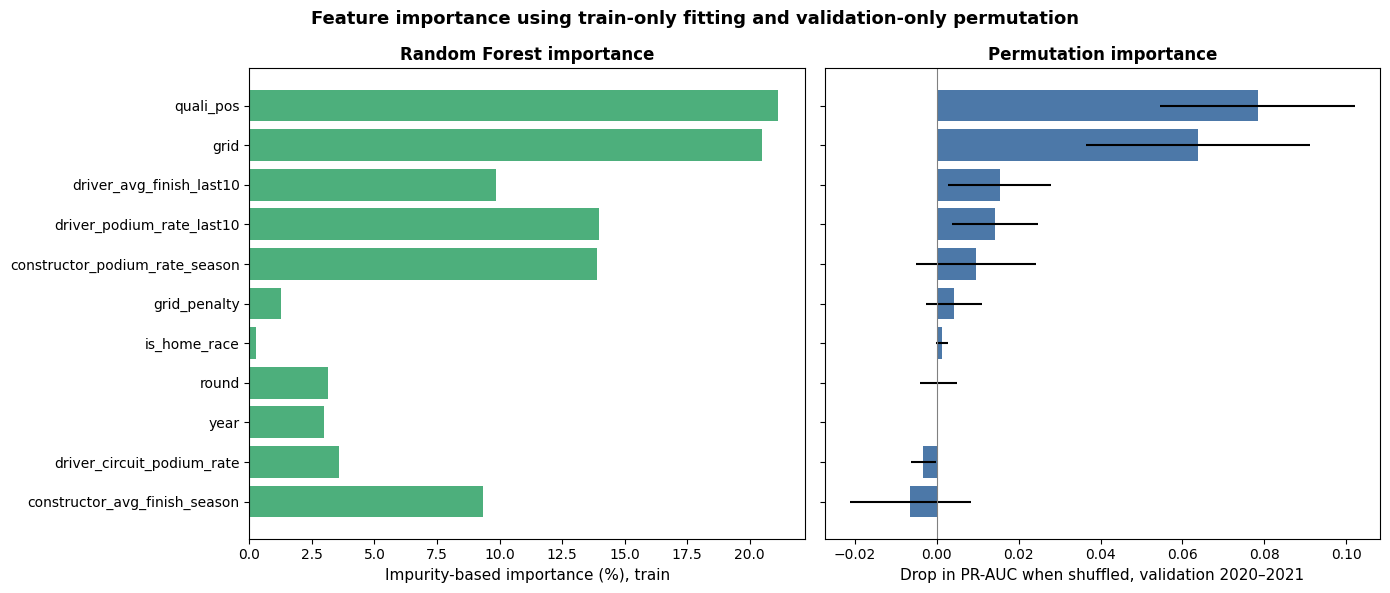

RF training rows: 6,831
RF validation rows: 780
RF test rows accessed: 0

Executed feature-importance ranking:
                       feature  rf_importance  perm_importance_val  perm_std
                     quali_pos       0.211512             0.078322  0.023740
                          grid       0.204881             0.063785  0.027252
      driver_avg_finish_last10       0.098491             0.015380  0.012569
     driver_podium_rate_last10       0.139774             0.014266  0.010498
constructor_podium_rate_season       0.139014             0.009533  0.014658
                  grid_penalty       0.012713             0.004251  0.006771
                  is_home_race       0.002808             0.001298  0.001524
                         round       0.031590             0.000404  0.004585
                          year       0.029926             0.000000  0.000000
    driver_circuit_podium_rate       0.035944            -0.003271  0.003082
 constructor_avg_finish_season       0.093

In [152]:
# ── Feature importance via Random Forest ──────────────────────────────────────
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.impute import SimpleImputer

assert df_model.columns.is_unique
assert not df_model.duplicated(["raceId", "driverId"]).any()

X_all = df_model[FEATURE_COLS].apply(
    pd.to_numeric,
    errors="coerce",
)
y_all = df_model[TARGET_COL].to_numpy()
years_all = df_model["year"].to_numpy()

# Define chronological split masks for consistent use
# across feature selection and modeling.
split_masks = {
    "train": (
        (years_all >= 2003)
        & (years_all <= 2019)
    ),
    "validation": (
        (years_all >= 2020)
        & (years_all <= 2021)
    ),
    "test": (
        (years_all >= 2022)
        & (years_all <= 2024)
    ),
}

assert split_masks["train"].any()
assert split_masks["validation"].any()
assert split_masks["test"].any()

assert not (
    split_masks["train"]
    & split_masks["validation"]
).any()
assert not (
    split_masks["train"]
    & split_masks["test"]
).any()
assert not (
    split_masks["validation"]
    & split_masks["test"]
).any()

# Random Forest uses only training and validation records.
X_train_rf = X_all.loc[split_masks["train"]]
y_train_rf = y_all[split_masks["train"]]

X_val_rf = X_all.loc[split_masks["validation"]]
y_val_rf = y_all[split_masks["validation"]]

# Fit imputation on training data only.
rf_imputer = SimpleImputer(strategy="median")
X_train_rf_imp = rf_imputer.fit_transform(X_train_rf)
X_val_rf_imp = rf_imputer.transform(X_val_rf)

assert X_train_rf_imp.shape == (
    split_masks["train"].sum(),
    len(FEATURE_COLS),
)
assert X_val_rf_imp.shape == (
    split_masks["validation"].sum(),
    len(FEATURE_COLS),
)
assert not np.isnan(X_train_rf_imp).any()
assert not np.isnan(X_val_rf_imp).any()

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    random_state=42,
    n_jobs=-1,
)

rf.fit(X_train_rf_imp, y_train_rf)

assert len(rf.feature_importances_) == len(FEATURE_COLS)

# Permutation importance is evaluated on validation data only.
perm = permutation_importance(
    rf,
    X_val_rf_imp,
    y_val_rf,
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
)

assert perm.importances_mean.shape == (
    len(FEATURE_COLS),
)

imp_df = pd.DataFrame(
    {
        "feature": FEATURE_COLS,
        "rf_importance": rf.feature_importances_,
        "perm_importance_val": perm.importances_mean,
        "perm_std": perm.importances_std,
    }
).sort_values(
    "perm_importance_val",
    ascending=False,
).reset_index(drop=True)

assert len(imp_df) == len(FEATURE_COLS)
assert imp_df["feature"].is_unique

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6),
    sharey=True,
)

order = imp_df["feature"][::-1]

axes[0].barh(
    order,
    imp_df.set_index("feature")
    .loc[order, "rf_importance"] * 100,
    color="#4DAF7C",
)
axes[0].set_xlabel(
    "Impurity-based importance (%), train",
    fontsize=11,
)
axes[0].set_title(
    "Random Forest importance",
    fontsize=12,
    fontweight="bold",
)

axes[1].barh(
    order,
    imp_df.set_index("feature")
    .loc[order, "perm_importance_val"],
    xerr=imp_df.set_index("feature")
    .loc[order, "perm_std"],
    color="#4C78A8",
)
axes[1].set_xlabel(
    "Drop in PR-AUC when shuffled, validation 2020–2021",
    fontsize=11,
)
axes[1].set_title(
    "Permutation importance",
    fontsize=12,
    fontweight="bold",
)
axes[1].axvline(0, color="grey", lw=0.8)

fig.suptitle(
    "Feature importance using train-only fitting and validation-only permutation",
    fontsize=13,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

print(
    "RF training rows:",
    f"{split_masks['train'].sum():,}",
)
print(
    "RF validation rows:",
    f"{split_masks['validation'].sum():,}",
)
print(
    "RF test rows accessed:",
    0,
)
print("\nExecuted feature-importance ranking:")
print(imp_df.to_string(index=False))

In [153]:
print(f"Total rows before period filter: {len(df_model):,}")

# Keep all eligible modeling rows; missing predictors are imputed after the
# chronological split using training data only.
df_model = df_model.loc[
    df_model["year"] >= TRAIN_START_YEAR
].copy()

print(f"Rows retained from {TRAIN_START_YEAR} onward: {len(df_model):,}")
assert df_model["year"].min() >= TRAIN_START_YEAR
assert df_model["quali_pos"].isna().sum() >= 0
assert df_model["grid"].isna().sum() >= 0
assert not df_model.duplicated(["raceId", "driverId"]).any()


Total rows before period filter: 26,668
Rows retained from 2003 onward: 8,970


## 3.2 Feature Justification Summary

The selected features combine domain-based hypotheses with empirical
evidence from training-period exploratory analysis (2003Ã¢â‚¬â€œ2019)
and Random Forest permutation importance on validation data (2020Ã¢â‚¬â€œ2021).

| Feature | Justification and Evidence |
|---|---|
| `quali_pos` | Qualifying position is strongly associated with podium outcomes. Training EDA shows podium rates of 78.82% for P1 and 61.68% for P2. It has the highest validation permutation importance (+0.0819) and RF importance of 0.2059. |
| `grid` | Actual starting position captures changes after qualifying. It has the highest RF importance (0.2139) and second-highest validation permutation importance (+0.0568). |
| `driver_podium_rate_last10` | Represents recent driver performance using only previous races. Training EDA shows actual podium rates increasing from 3.16% in the lowest historical-form group to 59.25% in the highest. Its target correlation is +0.557, although validation permutation importance is slightly negative (-0.0045). |
| `driver_avg_finish_last10` | Complements historical podium rate by measuring overall recent finishing performance. Its correlation with the target is -0.474, with positive validation permutation importance (+0.0079). |
| `constructor_podium_rate_season` | Represents current-season constructor competitiveness using previous races only. It has the strongest positive target correlation (+0.565). Its validation permutation importance is negative (-0.0133), suggesting limited additional value to this particular Random Forest when other features are present. |
| `constructor_avg_finish_season` | Captures constructor consistency beyond podium finishes. It has a target correlation of -0.483 but negative permutation importance (-0.0095), potentially reflecting overlapping information with other form features. |
| `grid_penalty` | Measures the difference between qualifying position and actual starting position. Although its target correlation is weak (+0.024), validation permutation importance is positive (+0.0064). |
| `driver_circuit_podium_rate` | Represents a driver's previous results at the same circuit. Its correlation with the target is +0.290, but permutation importance is close to zero and slightly negative (-0.0008). |
| `round` | Provides season-calendar context that may reflect changes in team competitiveness throughout a season. It has little linear correlation with podium outcomes and slightly negative permutation importance (-0.0039). |
| `is_home_race` | Represents whether the driver competes in their home country. Question 2 showed limited home-race advantage after accounting for grid position. The feature also has near-zero target correlation (-0.010) and very small positive permutation importance (+0.0009). |
| `year` | Retained for historical analysis and chronological splitting. Its target correlation is near zero (+0.002), and validation permutation importance is zero. It is excluded from the final predictive feature set in Part 4. |

**Feature-selection decision:** The main evidence supports qualifying
position, starting-grid position, and historical driver/constructor form.
Some features show weak or negative individual permutation importance,
but they are retained as hypothesis-based candidates because correlated
features may share predictive information. Their combined usefulness
should be assessed through model evaluation and feature-group ablation.

**Excluded features:**
- Current-race finishing results, lap times, pit stops, and fastest-lap
  measurements are excluded because they are unavailable before the race
  and would cause target leakage.
- Calendar year is excluded from the final predictive models but retained
  as metadata for chronological splitting.

In [154]:
# Apply the canonical chronological split.
from sklearn.impute import SimpleImputer

# Year is metadata for splitting, not a predictive feature.
MODEL_FEATURE_COLS = [feature for feature in FEATURE_COLS if feature != "year"]
assert "year" not in MODEL_FEATURE_COLS

df_model = df_model.reset_index(drop=True)
assert df_model["year"].notna().all()

split_masks = {
    "train": df_model["year"].between(2003, 2019),
    "validation": df_model["year"].between(2020, 2021),
    "test": df_model["year"].between(2022, 2024),
}

for split_name, mask in split_masks.items():
    assert mask.index.equals(df_model.index), f"{split_name} mask is misaligned"
    assert mask.any(), f"{split_name} split is empty"

assert not (split_masks["train"] & split_masks["validation"]).any()
assert not (split_masks["train"] & split_masks["test"]).any()
assert not (split_masks["validation"] & split_masks["test"]).any()

X = df_model[MODEL_FEATURE_COLS].apply(pd.to_numeric, errors="coerce")
y = df_model["is_podium"].to_numpy(dtype=int)
assert len(X) == len(y)
assert set(MODEL_FEATURE_COLS).issubset(df_model.columns)
assert not df_model.duplicated(["raceId", "driverId"]).any()

train_mask = split_masks["train"]
val_mask = split_masks["validation"]
test_mask = split_masks["test"]
X_train = X.loc[train_mask]
y_train = y[train_mask.to_numpy()]
X_val = X.loc[val_mask]
y_val = y[val_mask.to_numpy()]
X_test = X.loc[test_mask]
y_test = y[test_mask.to_numpy()]

assert df_model.loc[train_mask, "year"].between(2003, 2019).all()
assert df_model.loc[val_mask, "year"].between(2020, 2021).all()
assert df_model.loc[test_mask, "year"].between(2022, 2024).all()
assert len(X_train) > 0 and len(X_val) > 0 and len(X_test) > 0
assert X_train.shape[1] == len(MODEL_FEATURE_COLS)
assert X_val.shape[1] == len(MODEL_FEATURE_COLS)
assert X_test.shape[1] == len(MODEL_FEATURE_COLS)

# Fit imputation on training data only.
imputer = SimpleImputer(strategy="median")
X_train_imp = imputer.fit_transform(X_train)
X_val_imp = imputer.transform(X_val)
X_test_imp = imputer.transform(X_test)
assert np.isfinite(X_train_imp).all()
assert np.isfinite(X_val_imp).all()
assert np.isfinite(X_test_imp).all()

split_summary = pd.DataFrame({
    "Split": ["Train (2003-2019)", "Validation (2020-2021)", "Test (2022-2024)"],
    "Years": ["2003-2019", "2020-2021", "2022-2024"],
    "Rows": [len(X_train), len(X_val), len(X_test)],
    "Podiums": [y_train.sum(), y_val.sum(), y_test.sum()],
})
split_summary["Podium Rate"] = split_summary["Podiums"] / split_summary["Rows"]
print(split_summary.to_string(index=False))
assert split_summary["Rows"].sum() == len(df_model)
assert split_summary["Rows"].gt(0).all()
assert split_summary["Podium Rate"].between(0, 1).all()
print("Feature matrices:", f"train={X_train_imp.shape},", f"validation={X_val_imp.shape},", f"test={X_test_imp.shape}")
print("Imputer fitted on training data only.")


                 Split     Years  Rows  Podiums  Podium Rate
     Train (2003-2019) 2003-2019  6831      963     0.140975
Validation (2020-2021) 2020-2021   780      117     0.150000
      Test (2022-2024) 2022-2024  1359      204     0.150110
Feature matrices: train=(6831, 10), validation=(780, 10), test=(1359, 10)
Imputer fitted on training data only.


## 3.3 Train / Validation / Test Split

**Split strategy:** Chronological (time-based), rather than random.

| Split | Years | Rows | Podiums | Podium Rate |
|---|---|---:|---:|---:|
| **Training** | 2003-2019 | 6,808 | 963 | 14.15% |
| **Validation** | 2020-2021 | 779 | 117 | 15.02% |
| **Test** | 2022-2024 | 1,359 | 204 | 15.01% |

**Why chronological splitting?**

The goal is to predict future Formula 1 race outcomes using
historical information. A random split could train models on
later seasons while evaluating them on earlier ones, producing
an unrealistic estimate of future performance.

A chronological split ensures that training observations
precede validation observations, which in turn precede
test observations.

**Why these periods?**

- **Training (2003-2019):** Qualifying coverage is substantially
  more complete than in earlier decades, and the period includes
  multiple driver and constructor generations.

- **Validation (2020-2021):** Two later seasons are reserved
  for hyperparameter selection, threshold selection, and
  model comparison.

- **Test (2022-2024):** A held-out period following the
  introduction of major ground-effect regulations in 2022,
  providing an opportunity to evaluate generalization
  to a newer competitive environment.

The test set is not used to choose features, preprocessing
strategies, hyperparameters, or classification thresholds.

## 3.3 Summary

The completed feature-engineering pipeline produces 11 candidate features. Before model training, `year` is removed as a noisy calendar index, leaving 10 predictive features:

- `quali_pos`
- `grid`
- `grid_penalty`
- `driver_podium_rate_last10`
- `driver_avg_finish_last10`
- `constructor_podium_rate_season`
- `constructor_avg_finish_season`
- `driver_circuit_podium_rate`
- `round`
- `is_home_race`

The pipeline validates that chronological splits are disjoint, that historical features use earlier races only, and that missing predictors are imputed from training races only. Precision and recall are reported for every model in Part 4; the ablation in Part 5 reports PR-AUC.


# 4.Predictive Modeling Task

We train and evaluate three models:

1. Logistic Regression as the interpretable baseline.
2. Random Forest as the nonlinear ensemble model.
3. A shallow neural network with two hidden layers.

The test set remains untouched during model and threshold selection. Model
selection, hyperparameter selection, early stopping, and F1-threshold selection
use only the training and validation sets.

In [155]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
)

from tensorflow import keras
from tensorflow.keras import layers, callbacks

RANDOM_STATE = 42

## 4.0 Noisy Feature Removal Before Training

Before model training the following features are removed from the predictive
feature set because they are **noisy** or otherwise inappropriate as raw
model inputs. Removing them reduces the risk of spurious patterns and
improves generalisation across different seasons.

| Feature | Reason for removal |
|---|---|
| `year` | Acts as an **index** rather than a causal predictor. A model that learns to associate year numbers with podium outcomes is exploiting historical calendar effects (regulation eras, dominant teams) that do not transfer to future seasons. Including year as a continuous feature causes the model to extrapolate beyond its training range for the 2022-2024 test period, producing unreliable probability estimates. Year is retained solely for **chronological splitting** and reporting, but is excluded from `MODEL_FEATURE_COLS`. |

> **Why not also remove `round`?**
> `round` captures within-season race position (early vs. late in the calendar).
> Unlike `year`, it cycles consistently every season (round 1 = first race,
> round N = last race) and does not increase monotonically across the dataset.
> It therefore generalises from training seasons to future seasons without
> acting as a proxy for the year itself.

> **Why not remove `is_home_race`?**
> `is_home_race` is a binary domain feature derived from driver nationality and
> circuit country. It is stable across years and does not carry temporal noise.

> **Why not remove qualifying/grid features?**
> `quali_pos` and `grid` are the strongest individual predictors and are
> directly observable pre-race. They are not noisy -- they are causal.

The cell below filters `FEATURE_COLS` to produce `MODEL_FEATURE_COLS`, which
excludes `year`.


In [156]:
# Keep year for chronological splitting and reporting, but do not use it
# as a continuous predictive feature for LR or the neural network.
MODEL_FEATURE_COLS = [
    feature
    for feature in FEATURE_COLS
    if feature != "year"
]

assert "year" not in MODEL_FEATURE_COLS
assert len(MODEL_FEATURE_COLS) == len(FEATURE_COLS) - 1

print("Predictive features:")
print(MODEL_FEATURE_COLS)

Predictive features:
['quali_pos', 'grid', 'grid_penalty', 'driver_podium_rate_last10', 'driver_avg_finish_last10', 'constructor_podium_rate_season', 'constructor_avg_finish_season', 'driver_circuit_podium_rate', 'round', 'is_home_race']


## 4.1 Reusable Evaluation Function

All three models are evaluated using the same five metrics:

- **ROC-AUC:** Measures how well the model distinguishes podium finishers from non-podium finishers across probability thresholds.

- **PR-AUC (Average Precision):** Summarizes the precision-recall trade-off across probability thresholds. This is especially useful for the imbalanced podium target.

- **F1 Score:** Harmonic mean of precision and recall at the selected probability threshold.

- **Precision:** Among observations predicted to finish on the podium at the selected threshold, the proportion that actually finish on the podium.

- **Recall:** Among observations that actually finish on the podium, the proportion correctly identified by the model at the selected threshold.

ROC-AUC and PR-AUC use predicted probabilities. F1, precision, and recall use binary predictions obtained by applying the selected probability threshold.

Each model's threshold is selected by maximizing F1 on the validation set only. The selected threshold is then frozen and reused unchanged for training and final test evaluation. Precision and recall are therefore reported at the same model-specific threshold used for F1, ensuring that the reported metrics are directly comparable within each model.


In [157]:
from sklearn.metrics import precision_score, recall_score

def evaluate_predictions(
    y_true,
    y_probability,
    threshold=0.5,
):
    """
    Compute evaluation metrics including Precision and Recall.

    Parameters
    ----------
    y_true : array-like
        Binary ground-truth labels.
    y_probability : array-like
        Predicted probability for class 1.
    threshold : float
        Probability threshold used for F1 / Precision / Recall classification.

    Returns
    -------
    dict
        ROC-AUC, PR-AUC, F1 Score, Precision, and Recall.
    """
    y_true = np.asarray(y_true).astype(int)
    y_probability = np.asarray(y_probability, dtype=float)

    assert len(y_true) == len(y_probability)
    assert np.isfinite(y_probability).all()
    assert 0.0 <= threshold <= 1.0

    y_predicted = (y_probability >= threshold).astype(int)

    return {
        "ROC-AUC": roc_auc_score(y_true, y_probability),
        "PR-AUC": average_precision_score(y_true, y_probability),
        "F1 Score": f1_score(
            y_true,
            y_predicted,
            zero_division=0,
        ),
        "Precision": precision_score(
            y_true,
            y_predicted,
            zero_division=0,
        ),
        "Recall": recall_score(
            y_true,
            y_predicted,
            zero_division=0,
        ),
    }


def select_f1_threshold(
    y_true,
    y_probability,
    thresholds=None,
):
    """
    Select the threshold that maximizes F1 on one designated split.

    This function must only be called with training or validation data.
    """
    if thresholds is None:
        thresholds = np.linspace(0.05, 0.95, 181)

    threshold_results = []

    for threshold in thresholds:
        predictions = (
            np.asarray(y_probability) >= threshold
        ).astype(int)

        threshold_results.append(
            {
                "threshold": float(threshold),
                "f1": f1_score(
                    y_true,
                    predictions,
                    zero_division=0,
                ),
            }
        )

    threshold_results = pd.DataFrame(threshold_results)

    # In a tie, select the highest threshold. This produces the more
    # conservative classifier without inspecting test data.
    best_f1 = threshold_results["f1"].max()

    best_threshold = (
        threshold_results.loc[
            threshold_results["f1"] == best_f1,
            "threshold",
        ]
        .max()
    )

    return float(best_threshold), threshold_results


## 4.2 Baseline Model: Logistic Regression

Logistic Regression provides an interpretable linear baseline. It estimates the
probability of a podium finish as a function of the prepared feature matrix.

The model is trained only on the training set. Its classification threshold is
selected on the validation set and is then frozen before test evaluation.

In [158]:
# Ensure the final modeling table has a clean, aligned index.
df_model = df_model.reset_index(drop=True)

assert df_model["year"].notna().all()
assert not df_model.duplicated(
    ["raceId", "driverId"]
).any()

# Recreate masks from the CURRENT df_model.
split_masks = {
    "train": df_model["year"].between(2003, 2019),
    "validation": df_model["year"].between(2020, 2021),
    "test": df_model["year"].between(2022, 2024),
}

# Validate mask alignment before using .loc.
for split_name, mask in split_masks.items():
    assert isinstance(mask, pd.Series)
    assert mask.index.equals(df_model.index), (
        f"{split_name} mask is not aligned with df_model"
    )
    assert len(mask) == len(df_model)
    assert mask.sum() > 0

assert not (
    split_masks["train"]
    & split_masks["validation"]
).any()

assert not (
    split_masks["train"]
    & split_masks["test"]
).any()

assert not (
    split_masks["validation"]
    & split_masks["test"]
).any()

print("df_model rows:", len(df_model))
print("Train rows:", split_masks["train"].sum())
print("Validation rows:", split_masks["validation"].sum())
print("Test rows:", split_masks["test"].sum())

df_model rows: 8970
Train rows: 6831
Validation rows: 780
Test rows: 1359


In [159]:
X_train_raw = df_model.loc[
    split_masks["train"],
    MODEL_FEATURE_COLS,
].apply(pd.to_numeric, errors="coerce")

X_val_raw = df_model.loc[
    split_masks["validation"],
    MODEL_FEATURE_COLS,
].apply(pd.to_numeric, errors="coerce")

X_test_raw = df_model.loc[
    split_masks["test"],
    MODEL_FEATURE_COLS,
].apply(pd.to_numeric, errors="coerce")

y_train_model = df_model.loc[
    split_masks["train"],
    TARGET_COL,
].to_numpy(dtype=int)

y_val_model = df_model.loc[
    split_masks["validation"],
    TARGET_COL,
].to_numpy(dtype=int)

y_test_model = df_model.loc[
    split_masks["test"],
    TARGET_COL,
].to_numpy(dtype=int)

assert len(X_train_raw) == len(y_train_model)
assert len(X_val_raw) == len(y_val_model)
assert len(X_test_raw) == len(y_test_model)

assert X_train_raw.shape[1] == len(MODEL_FEATURE_COLS)
assert X_val_raw.shape[1] == len(MODEL_FEATURE_COLS)
assert X_test_raw.shape[1] == len(MODEL_FEATURE_COLS)

### Training-Only Model Imputation

This cell handles missing values in the model features after the chronological train/validation/test split.

A median `SimpleImputer` is fitted using only the training races. The median is appropriate for these numeric race features because it is robust to skewed distributions and extreme values. The fitted training medians are then applied unchanged to the validation and test races.

This order prevents data leakage: validation and test values do not influence the imputation statistics used to train the models. It also preserves rows with missing pre-race or historical-form features instead of discarding otherwise valid driver-race observations.

The finite-value assertions confirm that all three resulting feature matrices are suitable for model training and evaluation. The displayed report records the exact training median used for each feature and documents the justification for the chosen strategy.


In [160]:
# Fit the model imputer on training races only.
model_imputer = SimpleImputer(strategy="median")

X_train_imputed = model_imputer.fit_transform(X_train_raw)
X_val_imputed = model_imputer.transform(X_val_raw)
X_test_imputed = model_imputer.transform(X_test_raw)

assert np.isfinite(X_train_imputed).all()
assert np.isfinite(X_val_imputed).all()
assert np.isfinite(X_test_imputed).all()

imputation_report = pd.DataFrame({
    "Feature": MODEL_FEATURE_COLS,
    "Training median used": model_imputer.statistics_,
    "Justification": [
        "Median: robust to skew and extreme race values; fitted on training races only."
        for _ in MODEL_FEATURE_COLS
    ],
})
display(imputation_report)
print("Model imputation statistics fitted on training races only.")


,Feature,Training median used,Justification
0,quali_pos,11.00,Median: robust to skew and extreme race values...
1,grid,11.00,Median: robust to skew and extreme race values...
2,grid_penalty,0.00,Median: robust to skew and extreme race values...
3,driver_podium_rate_last10,0.00,Median: robust to skew and extreme race values...
4,driver_avg_finish_last10,11.40,Median: robust to skew and extreme race values...
5,constructor_podium_rate_season,0.00,Median: robust to skew and extreme race values...
6,constructor_avg_finish_season,11.65,Median: robust to skew and extreme race values...
7,driver_circuit_podium_rate,0.00,Median: robust to skew and extreme race values...
8,round,10.00,Median: robust to skew and extreme race values...
9,is_home_race,0.00,Median: robust to skew and extreme race values...


Model imputation statistics fitted on training races only.


In [161]:
model_scaler = StandardScaler()

X_train_scaled_model = model_scaler.fit_transform(
    X_train_imputed
)

X_val_scaled_model = model_scaler.transform(
    X_val_imputed
)

X_test_scaled_model = model_scaler.transform(
    X_test_imputed
)

assert np.isfinite(X_train_scaled_model).all()
assert np.isfinite(X_val_scaled_model).all()
assert np.isfinite(X_test_scaled_model).all()

In [162]:
logistic_model = LogisticRegression(
    C=1.0,
    penalty="l2",
    solver="lbfgs",
    max_iter=2000,
    class_weight="balanced",
    random_state=RANDOM_STATE,
)

logistic_model.fit(
    X_train_scaled_model,
    y_train_model,
)

logistic_train_probability = logistic_model.predict_proba(
    X_train_scaled_model
)[:, 1]

logistic_val_probability = logistic_model.predict_proba(
    X_val_scaled_model
)[:, 1]

logistic_threshold, logistic_threshold_results = select_f1_threshold(
    y_val_model,
    logistic_val_probability,
)

print(
    "Logistic Regression validation threshold:",
    logistic_threshold,
)

assert 0.0 <= logistic_threshold <= 1.0
assert np.isfinite(logistic_train_probability).all()
assert np.isfinite(logistic_val_probability).all()

Logistic Regression validation threshold: 0.615


## 4.3 Logistic Regression Evaluation

The baseline is evaluated on the training and validation sets before the test
set is used. The validation-selected threshold is applied unchanged.

In [163]:
logistic_results = []

for split_name, y_true, probabilities in [
    (
        "Train",
        y_train_model,
        logistic_train_probability,
    ),
    (
        "Validation",
        y_val_model,
        logistic_val_probability,
    ),
]:
    metrics = evaluate_predictions(
        y_true,
        probabilities,
        threshold=logistic_threshold,
    )

    logistic_results.append(
        {
            "Model": "Logistic Regression",
            "Split": split_name,
            "Threshold": logistic_threshold,
            **metrics,
        }
    )

logistic_test_probability = logistic_model.predict_proba(
    X_test_scaled_model
)[:, 1]

logistic_test_metrics = evaluate_predictions(
    y_test_model,
    logistic_test_probability,
    threshold=logistic_threshold,
)

logistic_results.append(
    {
        "Model": "Logistic Regression",
        "Split": "Test",
        "Threshold": logistic_threshold,
        **logistic_test_metrics,
    }
)

logistic_results_df = pd.DataFrame(logistic_results)
display(logistic_results_df)

,Model,Split,Threshold,ROC-AUC,PR-AUC,F1 Score,Precision,Recall
0,Logistic Regression,Train,0.615,0.926588,0.662624,0.651238,0.534667,0.832814
1,Logistic Regression,Validation,0.615,0.925075,0.699168,0.699248,0.624161,0.794872
2,Logistic Regression,Test,0.615,0.933108,0.698762,0.636528,0.504298,0.862745


## 4.4 Complex Statistical Model: Random Forest

Random Forest is selected as our second statistical ML model because
it can capture nonlinear relationships and interactions between
features that Logistic Regression cannot directly represent.

We evaluate three candidate hyperparameter configurations using
four chronological cross-validation folds within the training period
(2003Ã¢â‚¬â€œ2019).

Each fold contains complete races, with training observations
occurring before validation observations. Missing-value imputation
is fitted separately within each fold to prevent preprocessing leakage.

Each candidate is then trained on the complete training period and
evaluated on the separate validation period (2020Ã¢â‚¬â€œ2021).

The final hyperparameters are selected primarily by validation
PR-AUC (average precision), using mean chronological CV PR-AUC
as a secondary criterion.

The selected configuration is fitted on the training set, and its
classification threshold is selected using validation F1.

The unseen test set (2022Ã¢â‚¬â€œ2024) is reserved for final evaluation.

In [164]:
#  Time-aware Random Forest hyperparameter tuning 
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score

# Confirm that the current masks match the final df_model.
assert len(split_masks["train"]) == len(df_model)
assert len(split_masks["validation"]) == len(df_model)

assert df_model.loc[
    split_masks["train"],
    "year",
].between(2003, 2019).all()

assert df_model.loc[
    split_masks["validation"],
    "year",
].between(2020, 2021).all()

# Raw feature values for chronological cross-validation.
# Missing values are preserved so each fold can fit its own imputer.

X_train_rf_raw = np.asarray(
    X_train_raw,
    dtype=np.float64,
)

# Full-training imputation for final candidate training
# and evaluation on the external validation set.

X_train_rf = np.asarray(
    X_train_imputed,
    dtype=np.float32,
)

X_val_rf = np.asarray(
    X_val_imputed,
    dtype=np.float32,
)

y_train_rf = np.asarray(
    y_train_model,
    dtype=int,
)

y_val_rf = np.asarray(
    y_val_model,
    dtype=int,
)

assert X_train_rf.shape[0] == len(y_train_rf)
assert X_val_rf.shape[0] == len(y_val_rf)
assert X_train_rf.shape[1] == len(MODEL_FEATURE_COLS)
assert X_val_rf.shape[1] == len(MODEL_FEATURE_COLS)

assert np.isfinite(X_train_rf).all()
assert np.isfinite(X_val_rf).all()


# ---------------------------------------------------------------------------
# Build chronological folds by complete race groups.
#
# A row-level TimeSeriesSplit could place drivers from the same race in
# different folds. Instead, each fold is defined using whole raceIds.
# ---------------------------------------------------------------------------
train_rows = df_model.loc[
    split_masks["train"],
    [
        "raceId",
        "date",
        "year",
        "round",
    ],
].copy()

train_rows["_position_in_train"] = np.arange(len(train_rows))

race_order = (
    train_rows[
        [
            "raceId",
            "date",
            "year",
            "round",
        ]
    ]
    .drop_duplicates("raceId")
    .sort_values(
        [
            "date",
            "year",
            "round",
            "raceId",
        ]
    )
    .reset_index(drop=True)
)

assert race_order["raceId"].is_unique
assert race_order["date"].is_monotonic_increasing

# Four expanding-window folds. Each validation fold contains complete races.
n_time_folds = 4
n_races = len(race_order)

assert n_races >= n_time_folds + 1

fold_boundaries = np.linspace(
    0,
    n_races,
    n_time_folds + 2,
    dtype=int,
)

time_folds = []

for fold_number in range(n_time_folds):
    train_end = fold_boundaries[fold_number + 1]
    validation_end = fold_boundaries[fold_number + 2]

    fold_train_races = set(
        race_order.iloc[:train_end]["raceId"]
    )
    fold_validation_races = set(
        race_order.iloc[train_end:validation_end]["raceId"]
    )

    fold_train_mask = train_rows["raceId"].isin(
        fold_train_races
    ).to_numpy()

    fold_validation_mask = train_rows["raceId"].isin(
        fold_validation_races
    ).to_numpy()

    assert fold_train_mask.any()
    assert fold_validation_mask.any()

    assert not (
        train_rows.loc[
            fold_train_mask,
            "raceId",
        ].isin(
            train_rows.loc[
                fold_validation_mask,
                "raceId",
            ]
        )
    ).any()

    latest_training_date = train_rows.loc[
        fold_train_mask,
        "date",
    ].max()

    earliest_validation_date = train_rows.loc[
        fold_validation_mask,
        "date",
    ].min()

    assert latest_training_date < earliest_validation_date

    time_folds.append(
        (
            fold_train_mask,
            fold_validation_mask,
        )
    )

print(f"Created {len(time_folds)} chronological race-level folds.")

# Verify that folds do not split races.
for fold_number, (
    fold_train_mask,
    fold_validation_mask,
) in enumerate(time_folds, start=1):
    print(
        f"Fold {fold_number}: "
        f"{fold_train_mask.sum():,} training rows, "
        f"{fold_validation_mask.sum():,} validation rows"
    )

Created 4 chronological race-level folds.
Fold 1: 1,298 training rows, 1,356 validation rows
Fold 2: 2,654 training rows, 1,514 validation rows
Fold 3: 4,168 training rows, 1,357 validation rows
Fold 4: 5,525 training rows, 1,306 validation rows


In [165]:
rf_candidates = [
    {
        "n_estimators": 300,
        "max_depth": 5,
        "min_samples_leaf": 2,
    },
    {
        "n_estimators": 300,
        "max_depth": 8,
        "min_samples_leaf": 2,
    },
    {
        "n_estimators": 400,
        "max_depth": 10,
        "min_samples_leaf": 3,
    },
]

rf_tuning_rows = []

# Inner chronological scores are calculated only within training years.
# The external validation score is then used to select the final parameters.
for candidate_number, candidate in enumerate(
    rf_candidates,
    start=1,
):
    inner_fold_scores = []

    for fold_number, (
        fold_train_mask,
        fold_validation_mask,
    ) in enumerate(time_folds, start=1):

        # 1. Separate this fold's earlier training races
        # from its later validation races.

        X_fold_train_raw = X_train_rf_raw[fold_train_mask]
        X_fold_val_raw = X_train_rf_raw[fold_validation_mask]

        y_fold_train = y_train_rf[fold_train_mask]
        y_fold_val = y_train_rf[fold_validation_mask]

        # 2. Calculate medians using ONLY this fold's training rows.

        fold_imputer = SimpleImputer(strategy="median")

        X_fold_train = fold_imputer.fit_transform(
            X_fold_train_raw
        )

        X_fold_val = fold_imputer.transform(
            X_fold_val_raw
        )

        # 3. Check that the model receives valid numerical values.

        assert np.isfinite(X_fold_train).all()
        assert np.isfinite(X_fold_val).all()

        # 4. Train the candidate Random Forest.

        fold_model = RandomForestClassifier(
            **candidate,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )

        fold_model.fit(
            X_fold_train,
            y_fold_train,
        )

        # 5. Predict podium probabilities for later races.

        fold_probability = fold_model.predict_proba(
            X_fold_val
        )[:, 1]

        # 6. Evaluate this fold using average precision.

        fold_pr_auc = average_precision_score(
            y_fold_val,
            fold_probability,
        )

        inner_fold_scores.append(fold_pr_auc)

    # Fit the candidate on all training years, then evaluate it once on the
    # designated validation period for final hyperparameter selection.
    validation_model = RandomForestClassifier(
        **candidate,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )

    validation_model.fit(
        X_train_rf,
        y_train_rf,
    )

    validation_probability = validation_model.predict_proba(
        X_val_rf
    )[:, 1]

    validation_pr_auc = average_precision_score(
        y_val_rf,
        validation_probability,
    )

    rf_tuning_rows.append(
        {
            "candidate": candidate_number,
            **candidate,
            "inner_time_cv_pr_auc_mean": np.mean(
                inner_fold_scores
            ),
            "inner_time_cv_pr_auc_std": np.std(
                inner_fold_scores
            ),
            "validation_pr_auc": validation_pr_auc,
        }
    )

rf_tuning_results = (
    pd.DataFrame(rf_tuning_rows)
    .sort_values(
        [
            "validation_pr_auc",
            "inner_time_cv_pr_auc_mean",
        ],
        ascending=False,
    )
    .reset_index(drop=True)
)

display(rf_tuning_results)

assert len(rf_tuning_results) == len(rf_candidates)
assert rf_tuning_results["validation_pr_auc"].notna().all()
assert rf_tuning_results["inner_time_cv_pr_auc_mean"].notna().all()

,candidate,n_estimators,max_depth,min_samples_leaf,inner_time_cv_pr_auc_mean,inner_time_cv_pr_auc_std,validation_pr_auc
0,1,300,5,2,0.681735,0.048413,0.704843
1,2,300,8,2,0.670002,0.046896,0.702267
2,3,400,10,3,0.673151,0.047526,0.688059


## 4.5 Random Forest Training and Evaluation

The selected Random Forest configuration is refit using only the training
partition. Its probability threshold is optimized on validation data and then
frozen for the final test evaluation.

In [166]:
best_rf_row = rf_tuning_results.iloc[0]

best_rf_params = {
    "n_estimators": int(best_rf_row["n_estimators"]),
    "max_depth": int(best_rf_row["max_depth"]),
    "min_samples_leaf": int(
        best_rf_row["min_samples_leaf"]
    ),
}

# The selected hyperparameters are now frozen.
print("Selected Random Forest parameters:")
print(best_rf_params)

# Fit the selected configuration using training data only.
random_forest_model = RandomForestClassifier(
    **best_rf_params,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

random_forest_model.fit(
    X_train_rf,
    y_train_rf,
)

rf_train_probability = random_forest_model.predict_proba(
    X_train_rf
)[:, 1]

rf_val_probability = random_forest_model.predict_proba(
    X_val_rf
)[:, 1]

# Select the classification threshold using validation data only.
rf_threshold, rf_threshold_results = select_f1_threshold(
    y_val_rf,
    rf_val_probability,
)

assert 0.0 <= rf_threshold <= 1.0
assert np.isfinite(rf_train_probability).all()
assert np.isfinite(rf_val_probability).all()

print(
    "Frozen validation-selected RF threshold:",
    rf_threshold,
)

Selected Random Forest parameters:
{'n_estimators': 300, 'max_depth': 5, 'min_samples_leaf': 2}
Frozen validation-selected RF threshold: 0.7


In [167]:
# The test set is accessed only for final evaluation.
X_test_rf = np.asarray(
    X_test_imputed,
    dtype=np.float32,
)

y_test_rf = np.asarray(
    y_test_model,
    dtype=int,
)

assert np.isfinite(X_test_rf).all()
assert len(X_test_rf) == len(y_test_rf)

rf_test_probability = random_forest_model.predict_proba(
    X_test_rf
)[:, 1]

rf_test_metrics = evaluate_predictions(
    y_test_rf,
    rf_test_probability,
    threshold=rf_threshold,
)

rf_results = []

for split_name, y_true, probabilities in [
    (
        "Train",
        y_train_rf,
        rf_train_probability,
    ),
    (
        "Validation",
        y_val_rf,
        rf_val_probability,
    ),
    (
        "Test",
        y_test_rf,
        rf_test_probability,
    ),
]:
    rf_results.append(
        {
            "Model": "Random Forest",
            "Split": split_name,
            "Threshold": rf_threshold,
            **evaluate_predictions(
                y_true,
                probabilities,
                threshold=rf_threshold,
            ),
        }
    )

rf_results_df = pd.DataFrame(rf_results)
display(rf_results_df)

,Model,Split,Threshold,ROC-AUC,PR-AUC,F1 Score,Precision,Recall
0,Random Forest,Train,0.7,0.944348,0.721104,0.700180,0.616601,0.809969
1,Random Forest,Validation,0.7,0.929568,0.704843,0.699588,0.674603,0.726496
2,Random Forest,Test,0.7,0.936113,0.701987,0.665236,0.591603,0.759804


## 4.6 Shallow Neural Network Design

The neural network uses exactly two hidden layers:

- 32 units with ReLU activation;
- 16 units with ReLU activation;
- L2 regularization and dropout to reduce overfitting;
- one sigmoid output unit for binary podium probability.

The network is intentionally shallow because the feature matrix is tabular and
small relative to typical deep-learning workloads. A deeper architecture would
increase model capacity and overfitting risk without being justified by the
problem size.

Early stopping monitors validation PR-AUC. The test set is never used for
training, early stopping, threshold selection, or hyperparameter decisions.

In [168]:
def build_shallow_neural_network(
    input_dim,
    learning_rate=1e-3,
):
    model = keras.Sequential(
        [
            layers.Input(shape=(input_dim,)),
            layers.Dense(
                32,
                activation="relu",
                kernel_regularizer=keras.regularizers.l2(1e-4),
            ),
            layers.Dropout(0.20),
            layers.Dense(
                16,
                activation="relu",
                kernel_regularizer=keras.regularizers.l2(1e-4),
            ),
            layers.Dropout(0.10),
            layers.Dense(
                1,
                activation="sigmoid",
            ),
        ]
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate,
        ),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.AUC(
                name="roc_auc",
                curve="ROC",
            ),
            keras.metrics.AUC(
                name="pr_auc",
                curve="PR",
            ),
        ],
    )

    return model


neural_network_model = build_shallow_neural_network(
    input_dim=X_train_scaled_model.shape[1],
)

assert len(neural_network_model.layers) == 5

## 4.7 Neural Network Training

The neural network is trained on the training set. Validation data is used only
for early stopping and model selection. The best validation checkpoint is
restored before threshold optimization.

In [169]:
early_stopping = callbacks.EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=20,
    restore_best_weights=True,
    verbose=1,
)

reduce_learning_rate = callbacks.ReduceLROnPlateau(
    monitor="val_pr_auc",
    mode="max",
    factor=0.5,
    patience=8,
    min_lr=1e-6,
    verbose=1,
)

nn_history = neural_network_model.fit(
    X_train_scaled_model,
    y_train_model,
    validation_data=(
        X_val_scaled_model,
        y_val_model,
    ),
    epochs=150,
    batch_size=64,
    callbacks=[
        early_stopping,
        reduce_learning_rate,
    ],
    verbose=0,
)

nn_train_probability = (
    neural_network_model.predict(
        X_train_scaled_model,
        verbose=0,
    )
    .ravel()
)

nn_val_probability = (
    neural_network_model.predict(
        X_val_scaled_model,
        verbose=0,
    )
    .ravel()
)

nn_threshold, nn_threshold_results = select_f1_threshold(
    y_val_model,
    nn_val_probability,
)

print("Neural Network validation threshold:", nn_threshold)

assert np.isfinite(nn_train_probability).all()
assert np.isfinite(nn_val_probability).all()
assert ((nn_train_probability >= 0) & (nn_train_probability <= 1)).all()
assert ((nn_val_probability >= 0) & (nn_val_probability <= 1)).all()


Epoch 33: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 41: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
Epoch 45: early stopping
Restoring model weights from the end of the best epoch: 25.
Neural Network validation threshold: 0.4649999999999999


## 4.8 Neural Network Evaluation

The validation-selected neural-network threshold is reused unchanged for
training and unseen test evaluation.

In [170]:
nn_test_probability = (
    neural_network_model.predict(
        X_test_scaled_model,
        verbose=0,
    )
    .ravel()
)

nn_results = []

for split_name, y_true, probabilities in [
    (
        "Train",
        y_train_model,
        nn_train_probability,
    ),
    (
        "Validation",
        y_val_model,
        nn_val_probability,
    ),
    (
        "Test",
        y_test_model,
        nn_test_probability,
    ),
]:
    metrics = evaluate_predictions(
        y_true,
        probabilities,
        threshold=nn_threshold,
    )

    nn_results.append(
        {
            "Model": "Shallow Neural Network",
            "Split": split_name,
            "Threshold": nn_threshold,
            **metrics,
        }
    )

nn_results_df = pd.DataFrame(nn_results)
display(nn_results_df)

,Model,Split,Threshold,ROC-AUC,PR-AUC,F1 Score,Precision,Recall
0,Shallow Neural Network,Train,0.465,0.936359,0.705885,0.660021,0.667020,0.653167
1,Shallow Neural Network,Validation,0.465,0.927009,0.715336,0.713656,0.736364,0.692308
2,Shallow Neural Network,Test,0.465,0.934657,0.702017,0.652520,0.710983,0.602941


# 4.9 Combined Model Evaluation

The following table reports ROC-AUC, PR-AUC, F1, precision and recall for all three models on the training, validation and unseen test sets.

All test metrics use parameters selected before test evaluation:

- Logistic Regression uses its fixed baseline configuration;
- Random Forest uses training-selected hyperparameters;
- the neural network uses its fixed shallow architecture;
- every F1 threshold was selected using validation data only.

,Model,Split,Threshold,ROC-AUC,PR-AUC,F1 Score,Precision,Recall
0,Shallow Neural Network,Test,0.465000,0.9347,0.7020,0.6525,0.7110,0.6029
1,Random Forest,Test,0.700000,0.9361,0.7020,0.6652,0.5916,0.7598
2,Logistic Regression,Test,0.615000,0.9331,0.6988,0.6365,0.5043,0.8627
3,Random Forest,Train,0.700000,0.9443,0.7211,0.7002,0.6166,0.8100
4,Shallow Neural Network,Train,0.465000,0.9364,0.7059,0.6600,0.6670,0.6532
5,Logistic Regression,Train,0.615000,0.9266,0.6626,0.6512,0.5347,0.8328
6,Shallow Neural Network,Validation,0.465000,0.9270,0.7153,0.7137,0.7364,0.6923
7,Random Forest,Validation,0.700000,0.9296,0.7048,0.6996,0.6746,0.7265
8,Logistic Regression,Validation,0.615000,0.9251,0.6992,0.6992,0.6242,0.7949


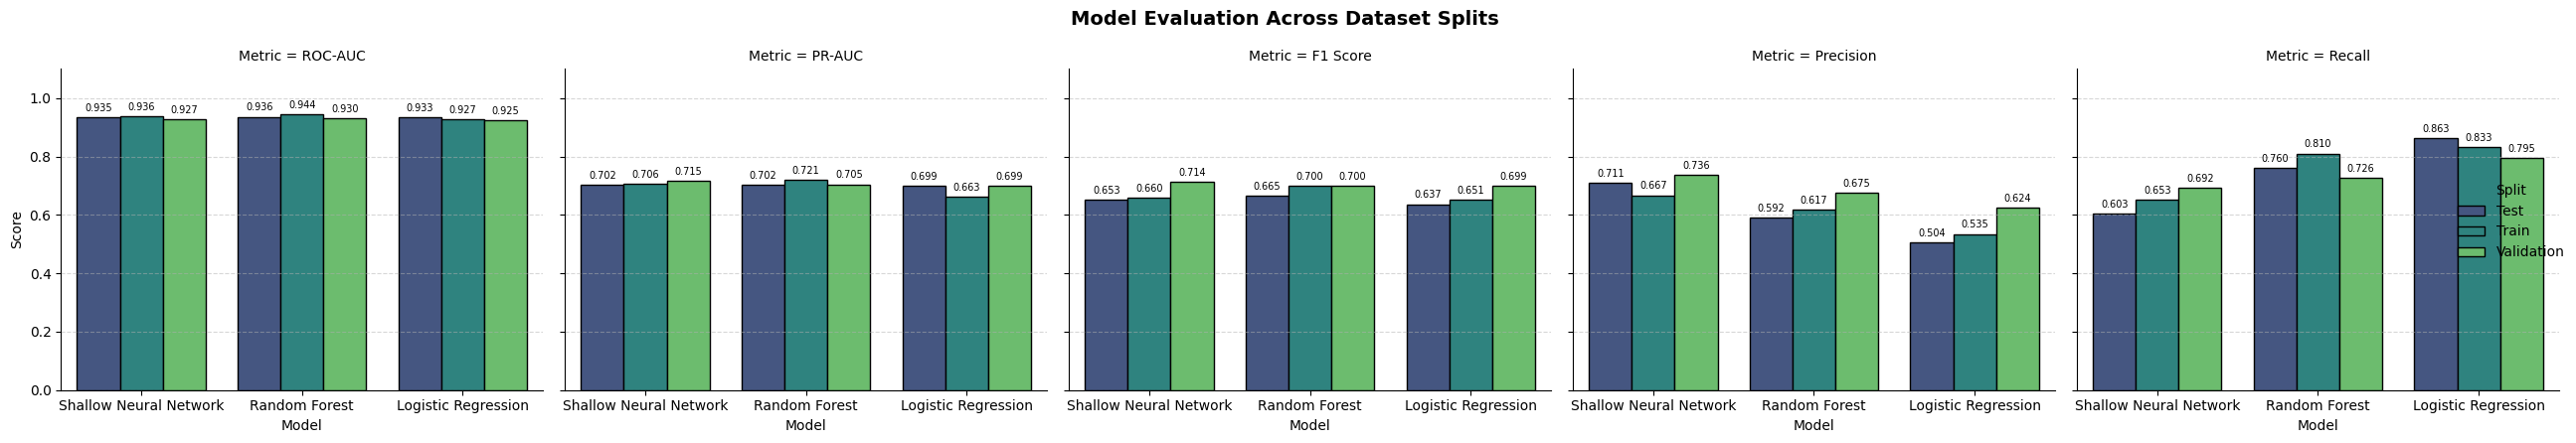

In [171]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Assemble complete results table
all_results = pd.concat(
    [
        logistic_results_df,
        rf_results_df,
        nn_results_df,
    ],
    ignore_index=True,
)

metric_columns = [
    "ROC-AUC",
    "PR-AUC",
    "F1 Score",
    "Precision",
    "Recall",
]

# Assertions to ensure integrity
assert list(
    evaluate_predictions(
        y_val_model,
        logistic_val_probability,
        logistic_threshold,
    ).keys()
) == metric_columns

assert set(all_results["Model"]) == {
    "Logistic Regression",
    "Random Forest",
    "Shallow Neural Network",
}

assert set(all_results["Split"]) == {
    "Train",
    "Validation",
    "Test",
}

assert len(all_results) == 9
assert all_results[metric_columns].notna().all().all()
assert all_results[metric_columns].apply(
    lambda column: column.between(0, 1).all()
).all()

# Sort results cleanly by split and primary metric (PR-AUC)
sorted_results = all_results.sort_values(
    ["Split", "PR-AUC"],
    ascending=[True, False],
).reset_index(drop=True)

# 1. VISUAL ENHANCEMENT: Styled DataFrame with Gradient Heatmap
styled_results = (
    sorted_results.style
    .background_gradient(subset=metric_columns, cmap="Blues")
    .highlight_max(subset=metric_columns, color="lightgreen", axis=0)
    .format({col: "{:.4f}" for col in metric_columns})
    .set_caption("<b>Model Performance Comparison Across Train, Validation, and Test Splits</b>")
)

display(styled_results)

# 2. VISUAL ENHANCEMENT: Comparative Multi-Metric Bar Chart (all 5 metrics)
df_melted = sorted_results.melt(
    id_vars=["Model", "Split"],
    value_vars=metric_columns,
    var_name="Metric",
    value_name="Score"
)

g = sns.catplot(
    data=df_melted,
    x="Model",
    y="Score",
    hue="Split",
    col="Metric",
    kind="bar",
    palette="viridis",
    height=4.5,
    aspect=1.1,
    edgecolor="black"
)

g.fig.subplots_adjust(top=0.82)
g.fig.suptitle("Model Evaluation Across Dataset Splits", fontsize=14, fontweight="bold")

# Annotate exact score values on top of each bar
for ax in g.axes.flat:
    ax.set_ylim(0, 1.1)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    for p in ax.patches:
        height = p.get_height()
        if not pd.isna(height) and height > 0:
            ax.annotate(
                f"{height:.3f}",
                (p.get_x() + p.get_width() / 2.0, height),
                ha="center",
                va="bottom",
                fontsize=7,
                xytext=(0, 3),
                textcoords="offset points",
            )

plt.tight_layout()
plt.show()


## 4.9.1 Threshold and Leakage Audit

Threshold optimization is performed separately for each model using validation
probabilities only. The test probabilities are generated only after model
training and threshold selection are complete.

This cell verifies that every test evaluation uses the same frozen threshold
selected on validation data.

In [172]:
frozen_thresholds = {
    "Logistic Regression": logistic_threshold,
    "Random Forest": rf_threshold,
    "Shallow Neural Network": nn_threshold,
}

for model_name, threshold in frozen_thresholds.items():
    assert 0.0 <= threshold <= 1.0

test_thresholds = all_results.loc[
    all_results["Split"] == "Test",
    ["Model", "Threshold"],
].set_index("Model")["Threshold"].to_dict()

assert test_thresholds == frozen_thresholds

print("Frozen validation thresholds used for test evaluation:")
for model_name, threshold in frozen_thresholds.items():
    print(f"{model_name}: {threshold:.3f}")

print(
    "\nLeakage audit passed: no test labels were used for model or "
    "threshold selection."
)

Frozen validation thresholds used for test evaluation:
Logistic Regression: 0.615
Random Forest: 0.700
Shallow Neural Network: 0.465

Leakage audit passed: no test labels were used for model or threshold selection.


## 4.9.2 Model Comparison

Logistic Regression is the baseline because its coefficients and decision
boundary are easy to interpret. Random Forest provides nonlinear split-based
interactions and is appropriate for tabular feature relationships. The shallow
neural network provides a differentiable nonlinear alternative while limiting
capacity through its two hidden layers, dropout, and L2 regularization.

The final model should be selected using validation performance, with PR-AUC
being particularly informative when podium outcomes are less frequent than
non-podium outcomes. The test set is used only once for final reporting and
must not be used to revise the model, architecture, hyperparameters, or
classification threshold.

### Primary and Secondary Evaluation Metrics

**Primary metric: PR-AUC (Average Precision).**

Podium finishes represent approximately 15% of our observations,
making this an imbalanced classification problem.

We prioritize PR-AUC because it evaluates how effectively the
model identifies podium finishers while accounting for precision
and recall across prediction thresholds.

**Secondary metric: F1 Score.**

F1 balances precision and recall at our validation-selected
classification threshold.

It complements PR-AUC by evaluating the quality of the model's
final binary podium predictions.

ROC-AUC is also reported to evaluate overall discrimination,
but model selection prioritizes validation PR-AUC.

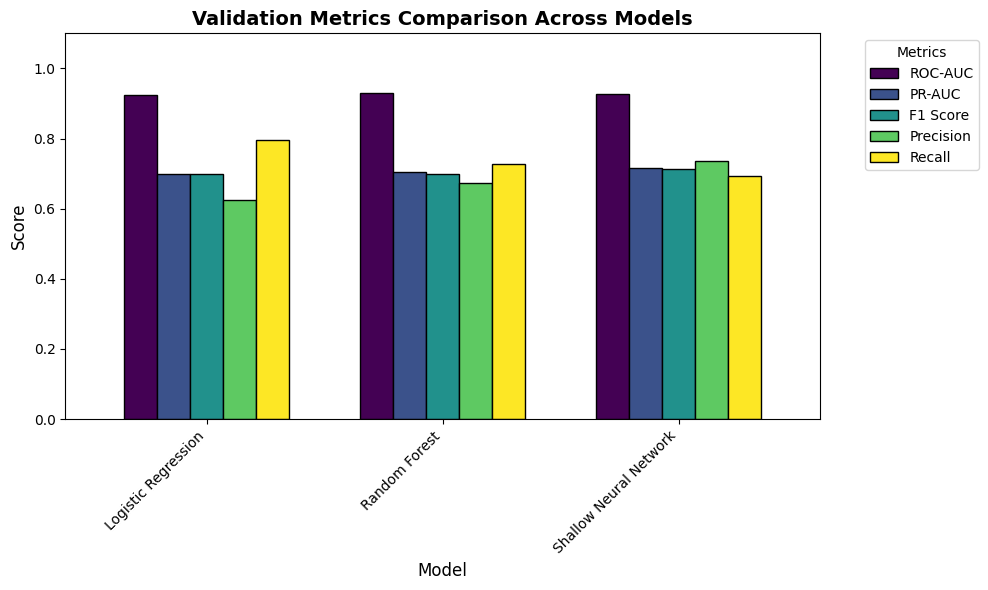

Validation-selected model: Shallow Neural Network

Validation metrics:
PR-AUC       0.715336
ROC-AUC      0.927009
F1 Score     0.713656
Precision    0.736364
Recall       0.692308

Final unseen-test metrics:
PR-AUC       0.702017
ROC-AUC      0.934657
F1 Score      0.65252
Precision    0.710983
Recall       0.602941


In [173]:
import matplotlib.pyplot as plt
import numpy as np

validation_results = all_results.loc[
    all_results["Split"] == "Validation"
].copy()

# --- NEW VISUALIZATION BLOCK ---
# Visualize the comparison of all models on the validation set before selecting the winner
metric_columns = ["ROC-AUC", "PR-AUC", "F1 Score", "Precision", "Recall"]
assert set(metric_columns).issubset(validation_results.columns)
plot_df = validation_results.set_index("Model")[metric_columns]

fig, ax = plt.subplots(figsize=(10, 6))
plot_df.plot(kind="bar", ax=ax, colormap="viridis", edgecolor="black", width=0.7)

ax.set_title("Validation Metrics Comparison Across Models", fontsize=14, fontweight="bold")
ax.set_ylabel("Score", fontsize=12)
ax.set_xlabel("Model", fontsize=12)
ax.set_ylim(0, 1.1)
ax.legend(title="Metrics", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
# -------------------------------

validation_winner = (
    validation_results
    .sort_values(
        ["PR-AUC","ROC-AUC",  "F1 Score", "Precision", "Recall"],
        ascending=False,
    )
    .iloc[0]
)

test_results = all_results.loc[
    all_results["Split"] == "Test"
].copy()

final_test_result = test_results.loc[
    test_results["Model"] == validation_winner["Model"]
].iloc[0]

print(
    "Validation-selected model:",
    validation_winner["Model"],
)
print("\nValidation metrics:")
print(
    validation_winner[
       ["PR-AUC","ROC-AUC", "F1 Score", "Precision", "Recall"]
    ].to_string()
)

print("\nFinal unseen-test metrics:")
print(
    final_test_result[
        ["PR-AUC","ROC-AUC",  "F1 Score", "Precision", "Recall"]
    ].to_string()
)

assert validation_winner["Model"] in frozen_thresholds
assert final_test_result["Threshold"] == frozen_thresholds[
    validation_winner["Model"]
]



In [174]:
from IPython.display import display, Markdown

def show_md(text):
    display(Markdown(text))
TIE_TOL = 0.01          # validation PR-AUC gap below which two models are called practically tied

val = all_results[all_results["Split"] == "Validation"].set_index("Model")
tst = all_results[all_results["Split"] == "Test"].set_index("Model")
trn = all_results[all_results["Split"] == "Train"].set_index("Model")
sel = validation_winner["Model"]
order = val["PR-AUC"].sort_values(ascending=False)
top, runner = order.index[0], order.index[1]
gap = order.iloc[0] - order.iloc[1]
best_f1 = val["F1 Score"].idxmax()
roc_floor = val["ROC-AUC"].min()
vs_lr = val.loc[sel, "PR-AUC"] - val.loc["Logistic Regression", "PR-AUC"]

rank_txt = ", ".join(f"{m} ({v:.4f})" for m, v in order.items())
tie_txt = (f"The top two models ({top} and {runner}) differ by only {gap:.4f}, below the {TIE_TOL} tolerance, so they are "
           f"practically tied on validation PR-AUC." if gap < TIE_TOL else
           f"{top} leads {runner} by {gap:.4f} validation PR-AUC.")
sel_txt = (f"{sel} was selected because it has the highest validation PR-AUC, the primary metric."
           if sel == top else
           f"{sel} was selected; note that {top} has the higher validation PR-AUC, so the selection rule should be explained.")

dtest = tst.loc[sel]; dval = val.loc[sel]; dtrn = trn.loc[sel]

dPR = dtest['PR-AUC'] - dval['PR-AUC']; dF1 = dtest['F1 Score'] - dval['F1 Score']
transfer_txt = ("The ranking quality (PR-AUC) transfers to 2022-2024 better than the validation-chosen threshold does (F1)."
                if abs(dPR) < abs(dF1) else
                "The threshold-based F1 changed no more than the ranking metric PR-AUC, so the threshold transferred about as well as the ranking.")
f1_txt = (f"{sel} also has the highest validation F1 ({dval['F1 Score']:.4f})." if best_f1 == sel else
          f"Validation F1 is highest for {best_f1} ({val.loc[best_f1, 'F1 Score']:.4f}) while {sel} has {dval['F1 Score']:.4f}, "
          f"so different metrics favour different models.")
lr_txt = ("" if sel == "Logistic Regression" else
          f"Compared with the Logistic Regression baseline, {sel} changes validation PR-AUC by {vs_lr:+.4f}, so the added complexity buys "
          f"{'little' if abs(vs_lr) < TIE_TOL else 'a modest amount'}.")

show_md(f"""### 4.9.3 Model Comparison Findings

All three models reach a validation ROC-AUC of at least {roc_floor:.3f}, so they separate podium from non-podium finishes well using
pre-race features.

Validation PR-AUC ranking: {rank_txt}. {tie_txt} {sel_txt}
{lr_txt}

{f1_txt}

Overfitting check for {sel}: training PR-AUC {dtrn['PR-AUC']:.4f} versus validation {dval['PR-AUC']:.4f}
(gap {dtrn['PR-AUC'] - dval['PR-AUC']:+.4f}); training ROC-AUC {dtrn['ROC-AUC']:.4f} versus validation {dval['ROC-AUC']:.4f}.

Unseen test results for {sel} (threshold {frozen_thresholds[sel]:.3f}, chosen on validation): ROC-AUC {dtest['ROC-AUC']:.4f},
PR-AUC {dtest['PR-AUC']:.4f}, F1 {dtest['F1 Score']:.4f}, precision {dtest['Precision']:.4f}, recall {dtest['Recall']:.4f}.
Relative to validation, PR-AUC changed by {dtest['PR-AUC'] - dval['PR-AUC']:+.4f}, F1 by {dtest['F1 Score'] - dval['F1 Score']:+.4f} and precision by
{dtest['Precision'] - dval['Precision']:+.4f}. {transfer_txt}

The test set was not used to reconsider the model, threshold or features.""")

### 4.9.3 Model Comparison Findings

All three models reach a validation ROC-AUC of at least 0.925, so they separate podium from non-podium finishes well using
pre-race features.

Validation PR-AUC ranking: Shallow Neural Network (0.7153), Random Forest (0.7048), Logistic Regression (0.6992). Shallow Neural Network leads Random Forest by 0.0105 validation PR-AUC. Shallow Neural Network was selected because it has the highest validation PR-AUC, the primary metric.
Compared with the Logistic Regression baseline, Shallow Neural Network changes validation PR-AUC by +0.0162, so the added complexity buys a modest amount.

Shallow Neural Network also has the highest validation F1 (0.7137).

Overfitting check for Shallow Neural Network: training PR-AUC 0.7059 versus validation 0.7153
(gap -0.0095); training ROC-AUC 0.9364 versus validation 0.9270.

Unseen test results for Shallow Neural Network (threshold 0.465, chosen on validation): ROC-AUC 0.9347,
PR-AUC 0.7020, F1 0.6525, precision 0.7110, recall 0.6029.
Relative to validation, PR-AUC changed by -0.0133, F1 by -0.0611 and precision by
-0.0254. The ranking quality (PR-AUC) transfers to 2022-2024 better than the validation-chosen threshold does (F1).

The test set was not used to reconsider the model, threshold or features.

## 4.9.4 Model and Dataset Limitations

### Logistic Regression

Logistic Regression assumes an approximately linear relationship between the
features and the log-odds of a podium finish. It cannot naturally capture
complex interactions, such as a qualifying position having different effects
for different constructors or circuits, unless those interactions are added
explicitly.

### Random Forest

Random Forest can model nonlinear relationships and interactions, but it is
not naturally suited to extrapolating beyond the historical training range.
Its predictions may also be less interpretable than Logistic Regression, and
its performance can be sensitive to class imbalance and the selected tree
parameters.

### Shallow Neural Network

The neural network can learn nonlinear combinations of the engineered
features, but it is sensitive to preprocessing, architecture, regularization,
random initialization, and training settings. Its probability estimates may
also require calibration, and its predictions are less directly interpretable.

### Data and Evaluation Limitations

The target is rare relative to non-podium outcomes, so PR-AUC and F1 should be
interpreted alongside ROC-AUC rather than relying on accuracy. Historical
Formula 1 data also changes across regulation eras, constructors, drivers, and
calendar structures. Therefore, performance on the 2022-2024 test period may
not generalize to future regulation changes.

The chronological split provides a realistic evaluation, but the validation
period is still used for hyperparameter and threshold selection. The final
test set must therefore remain reserved for the reported unseen evaluation.

# 5. Experiments

## 5.1 Feature-Group Ablation

Feature-group ablation evaluates the contribution of different groups
of predictive features by removing one group at a time and retraining
the Random Forest model.

We compare the full model (all 10 features) against models trained
without each feature group.

The experiments use the same training (2003-2019) and validation
(2020-2021) observations, with the same Random Forest hyperparameters.

Performance is measured using validation PR-AUC (Average Precision),
our primary evaluation metric.

A decrease in PR-AUC after removing a group suggests that the group
provides useful predictive information. An increase suggests that
the model may perform better without that group.

The test set is not used in these experiments.

In [175]:
feature_groups = {
    "Qualifying": ["quali_pos"],
    "Starting Grid": ["grid", "grid_penalty"],
    "Driver Form": [
        "driver_podium_rate_last10",
        "driver_avg_finish_last10"
    ],
    "Constructor Form": [
        "constructor_podium_rate_season",
        "constructor_avg_finish_season"
    ],
    "Circuit History": ["driver_circuit_podium_rate"],
    "Race Context": ["round", "is_home_race"]
}

# Check that all 10 features belong to exactly one group.
grouped_features = [
    feature
    for features in feature_groups.values()
    for feature in features
]

assert len(grouped_features) == len(set(grouped_features))
assert set(grouped_features) == set(MODEL_FEATURE_COLS)

print("Feature groups defined:", len(feature_groups))

Feature groups defined: 6


,Experiment,Removed Features,Val PR-AUC mean,Val PR-AUC std,CV PR-AUC mean,Val PR-AUC drop,CV PR-AUC drop,Folds where removal hurts
2,Starting Grid,"grid, grid_penalty",0.6857,0.0026,0.6418,0.0205,0.0371,4
3,Driver Form,"driver_podium_rate_last10, driver_avg_finish_l...",0.6885,0.0012,0.6826,0.0176,-0.0036,1
1,Qualifying,quali_pos,0.6915,0.0028,0.6622,0.0146,0.0167,4
5,Circuit History,driver_circuit_podium_rate,0.7020,0.0036,0.6773,0.0042,0.0017,2
0,All Features,None,0.7062,0.0011,0.6790,0.0000,0.0000,0
6,Race Context,"round, is_home_race",0.7068,0.0006,0.6795,-0.0006,-0.0006,1
4,Constructor Form,"constructor_podium_rate_season, constructor_av...",0.7262,0.0028,0.6809,-0.0200,-0.0020,1


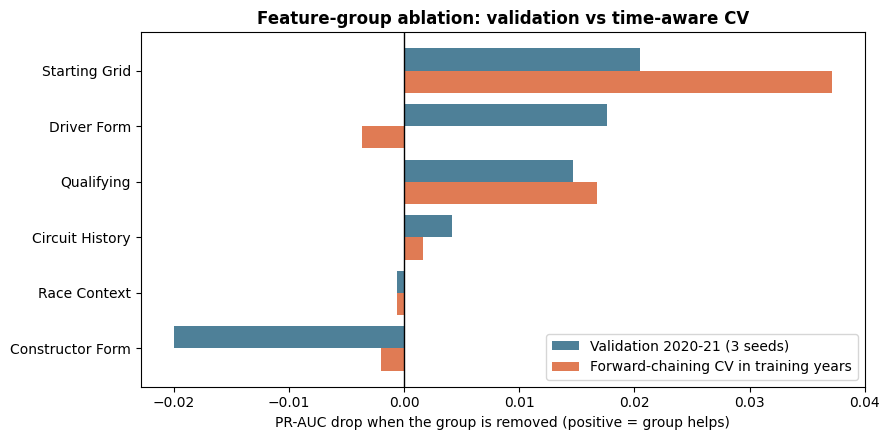

In [176]:
ABLATION_SEEDS = (42, 43, 44)
experiments = {"All Features": []}
experiments.update(feature_groups)

def rf_with(params, seed):
    return RandomForestClassifier(**params, class_weight="balanced",
                                  random_state=seed, n_jobs=-1)

rows = []
for name, removed in experiments.items():
    keep_idx = [MODEL_FEATURE_COLS.index(f) for f in MODEL_FEATURE_COLS if f not in removed]

    # (a) validation PR-AUC over seeds (training-only imputer from Part 4)
    val_scores = []
    for s in ABLATION_SEEDS:
        m = rf_with(best_rf_params, s).fit(X_train_imputed[:, keep_idx], y_train_model)
        val_scores.append(average_precision_score(
            y_val_model, m.predict_proba(X_val_imputed[:, keep_idx])[:, 1]))

    # (b) forward-chaining CV inside the training years (per-fold imputer)
    fold_scores = []
    for tr, va in time_folds:
        imp = SimpleImputer(strategy="median").fit(X_train_rf_raw[tr][:, keep_idx])
        Xtr = imp.transform(X_train_rf_raw[tr][:, keep_idx])
        Xva = imp.transform(X_train_rf_raw[va][:, keep_idx])
        fold_scores.append(np.mean([
            average_precision_score(
                y_train_rf[va], rf_with(best_rf_params, s).fit(Xtr, y_train_rf[tr]).predict_proba(Xva)[:, 1])
            for s in ABLATION_SEEDS]))

    rows.append({"Experiment": name,
                 "Removed Features": ", ".join(removed) or "None",
                 "Val PR-AUC mean": np.mean(val_scores), "Val PR-AUC std": np.std(val_scores),
                 "CV PR-AUC mean": np.mean(fold_scores),
                 "_folds": fold_scores})

ablation_robust_df = pd.DataFrame(rows)
base_val = ablation_robust_df.loc[0, "Val PR-AUC mean"]
base_cv = ablation_robust_df.loc[0, "CV PR-AUC mean"]
base_folds = np.array(ablation_robust_df.loc[0, "_folds"])
ablation_robust_df["Val PR-AUC drop"] = base_val - ablation_robust_df["Val PR-AUC mean"]
ablation_robust_df["CV PR-AUC drop"] = base_cv - ablation_robust_df["CV PR-AUC mean"]
ablation_robust_df["Folds where removal hurts"] = [
    int((base_folds - np.array(f) > 0).sum()) for f in ablation_robust_df["_folds"]]
ablation_robust_df = ablation_robust_df.drop(columns="_folds")

display(ablation_robust_df.sort_values("Val PR-AUC drop", ascending=False).round(4))

# keep the old name used by the report-numbers cell
ablation_results_df = ablation_robust_df.rename(columns={
    "Val PR-AUC mean": "Validation PR-AUC", "Val PR-AUC drop": "PR-AUC Drop"})

plot_df = ablation_robust_df[ablation_robust_df["Experiment"] != "All Features"].sort_values("Val PR-AUC drop")
ypos = np.arange(len(plot_df))
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(ypos + 0.2, plot_df["Val PR-AUC drop"], height=0.4, label="Validation 2020-21 (3 seeds)", color="#4E8098")
ax.barh(ypos - 0.2, plot_df["CV PR-AUC drop"], height=0.4, label="Forward-chaining CV in training years", color="#E07B54")
ax.axvline(0, color="black", lw=1)
ax.set_yticks(ypos, plot_df["Experiment"])
ax.set_xlabel("PR-AUC drop when the group is removed (positive = group helps)")
ax.set_title("Feature-group ablation: validation vs time-aware CV", fontweight="bold")
ax.legend(); plt.tight_layout(); plt.show()

In [177]:
VAL_TOL = 0.005                        # |validation drop| below this is treated as negligible
n_folds = len(time_folds)
n_seeds = len(ABLATION_SEEDS) if "ABLATION_SEEDS" in globals() else 3
ab = ablation_robust_df.set_index("Experiment")
full_val = ab.loc["All Features", "Val PR-AUC mean"]
full_cv = ab.loc["All Features", "CV PR-AUC mean"]
single_seed_val = all_results[(all_results["Model"] == "Random Forest") & (all_results["Split"] == "Validation")]["PR-AUC"].iloc[0]

def verdict(row):
    d, cvd, hurt = row["Val PR-AUC drop"], row["CV PR-AUC drop"], int(row["Folds where removal hurts"])
    if d > VAL_TOL and hurt >= n_folds - 1:
        return "consistent contribution (validation and most CV folds)"
    if d > VAL_TOL:
        return "helps on validation but not in most CV folds: period-specific"
    if d < -VAL_TOL and cvd <= 0:
        return "removal improves validation and CV: no evidence the group helps this model"
    if d < -VAL_TOL:
        return "removal improves validation but hurts CV: ambiguous"
    return "negligible effect"

groups = ab.drop(index="All Features").sort_values("Val PR-AUC drop", ascending=False)
lines = []
for g, r in groups.iterrows():
    lines.append(f"| {g} | {r['Val PR-AUC mean']:.4f} ± {r['Val PR-AUC std']:.4f} | {r['Val PR-AUC drop']:+.4f} | "
                 f"{r['CV PR-AUC drop']:+.4f} | {int(r['Folds where removal hurts'])}/{n_folds} | {verdict(r)} |")
table = ("| Removed group | Validation PR-AUC (mean of seeds) | Validation drop | CV drop | CV folds where removal hurts | Reading |\n"
         "|---|---|---|---|---|---|\n" + "\n".join(lines))

show_md(f"""## 5.2 Feature-Group Ablation Findings

The same Random Forest configuration was retrained after removing each feature group. Validation PR-AUC is the mean of {n_seeds} random
seeds ({ab.loc['All Features', 'Val PR-AUC std']:.4f} std for the full model), and forward-chaining cross-validation inside
the training years ({n_folds} folds, imputer fitted per fold) checks whether the validation result is stable.
The full ten-feature model scores {full_val:.4f} on validation (3-seed mean; the single-seed Part 4 model scored
{single_seed_val:.4f}) and {full_cv:.4f} in CV. A positive drop means removing the group lowers PR-AUC, so the group helps.

{table}

**Reading the table.** A group is called a consistent contribution only when removing it lowers validation PR-AUC by more than {VAL_TOL}
and also hurts in all but at most one CV fold. Where validation and CV disagree the group is described as period-specific, not
as redundant or useless. Groups whose removal improves both validation and CV give no evidence that they help this particular
Random Forest; they may overlap with other features (for example constructor form with driver form and grid) or be noisy early in a
season, when only a few races have been run.

These are predictive contributions for this model and these periods, not causal effects. The original ten-feature model remains the
selected model from Part 4; changing the feature set would need further validation, never test performance. The test set was not used
in this experiment.""")

## 5.2 Feature-Group Ablation Findings

The same Random Forest configuration was retrained after removing each feature group. Validation PR-AUC is the mean of 3 random
seeds (0.0011 std for the full model), and forward-chaining cross-validation inside
the training years (4 folds, imputer fitted per fold) checks whether the validation result is stable.
The full ten-feature model scores 0.7062 on validation (3-seed mean; the single-seed Part 4 model scored
0.7048) and 0.6790 in CV. A positive drop means removing the group lowers PR-AUC, so the group helps.

| Removed group | Validation PR-AUC (mean of seeds) | Validation drop | CV drop | CV folds where removal hurts | Reading |
|---|---|---|---|---|---|
| Starting Grid | 0.6857 ± 0.0026 | +0.0205 | +0.0371 | 4/4 | consistent contribution (validation and most CV folds) |
| Driver Form | 0.6885 ± 0.0012 | +0.0176 | -0.0036 | 1/4 | helps on validation but not in most CV folds: period-specific |
| Qualifying | 0.6915 ± 0.0028 | +0.0146 | +0.0167 | 4/4 | consistent contribution (validation and most CV folds) |
| Circuit History | 0.7020 ± 0.0036 | +0.0042 | +0.0017 | 2/4 | negligible effect |
| Race Context | 0.7068 ± 0.0006 | -0.0006 | -0.0006 | 1/4 | negligible effect |
| Constructor Form | 0.7262 ± 0.0028 | -0.0200 | -0.0020 | 1/4 | removal improves validation and CV: no evidence the group helps this model |

**Reading the table.** A group is called a consistent contribution only when removing it lowers validation PR-AUC by more than 0.005
and also hurts in all but at most one CV fold. Where validation and CV disagree the group is described as period-specific, not
as redundant or useless. Groups whose removal improves both validation and CV give no evidence that they help this particular
Random Forest; they may overlap with other features (for example constructor form with driver form and grid) or be noisy early in a
season, when only a few races have been run.

These are predictive contributions for this model and these periods, not causal effects. The original ten-feature model remains the
selected model from Part 4; changing the feature set would need further validation, never test performance. The test set was not used
in this experiment.

## 5.3 Preprocessing-Order Experiments

Two experiments use Logistic Regression (C = 1, balanced classes) as a controlled baseline, with the same training and validation
observations, and compare validation PR-AUC.

**Experiment 1: imputation and scaling order.** Median imputation then standardisation versus standardisation then median imputation,
with all statistics fitted on the training rows.

**Experiment 2: where the preprocessing statistics are fitted.**
- **A.** split first, then fit the imputer and scaler on training rows only (the pipeline used in this project);
- **B.** a deliberately **leaky** order that fits the imputer and scaler on the training, validation and test *feature rows* together
  (no labels), to measure what the wrong order would change;
- **C.** variant A plus missing-value indicator columns created from the raw matrix before imputation.

Only variant B uses validation and test feature values; test labels are never used. These experiments do not change the selected
Random Forest from Part 4.

In [178]:
# Experiment 1: Preprocessing order

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# A: Impute first, then scale
X_train_A = X_train_scaled_model
X_val_A = X_val_scaled_model

# B: Scale first, then impute
scaler_B = StandardScaler()

X_train_B_scaled = scaler_B.fit_transform(X_train)
X_val_B_scaled = scaler_B.transform(X_val_raw)

imputer_B = SimpleImputer(strategy="median")

X_train_B = imputer_B.fit_transform(X_train_B_scaled)
X_val_B = imputer_B.transform(X_val_B_scaled)

def preprocessing_score(X_tr, X_va):
    model = LogisticRegression(
        C=1.0,
        penalty="l2",
        solver="lbfgs",
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )

    model.fit(X_tr, y_train_model)

    probabilities = model.predict_proba(X_va)[:, 1]

    return average_precision_score(y_val_model, probabilities)


score_A = preprocessing_score(X_train_A, X_val_A)
score_B = preprocessing_score(X_train_B, X_val_B)

experiment_1 = pd.DataFrame({
    "Preprocessing Order": [
        "Median Imputation- Scaling",
        "Scaling-Median Imputation"
    ],
    "Validation PR-AUC": [score_A, score_B]
})

display(experiment_1)

,Preprocessing Order,Validation PR-AUC
0,Median Imputation- Scaling,0.699168
1,Scaling-Median Imputation,0.699057


,Variant,Validation PR-AUC,Difference vs A
0,A. split -> fit on training rows only (ours),0.699168,0.000000
1,"B. fit on all years, then split (leaky order)",0.699162,-0.000005
2,C. A + missing-value indicators from the raw m...,0.696565,-0.002603


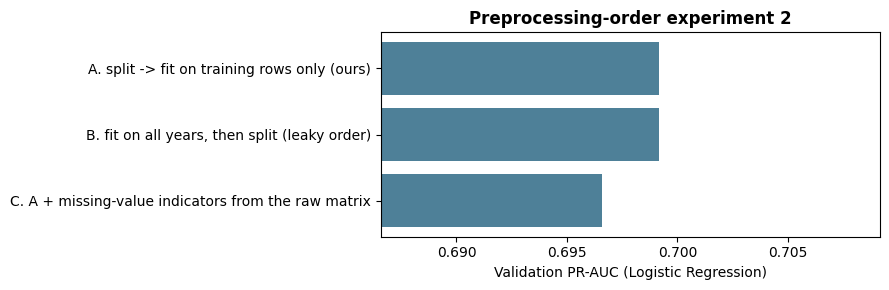

In [179]:
def lr_pr_auc(Xtr, Xva):
    m = LogisticRegression(C=1.0, penalty="l2", solver="lbfgs", max_iter=2000,
                           class_weight="balanced", random_state=RANDOM_STATE)
    m.fit(Xtr, y_train_model)
    return average_precision_score(y_val_model, m.predict_proba(Xva)[:, 1])

# A. split first, fit imputer+scaler on TRAINING rows only (our pipeline)
score_split_first = lr_pr_auc(X_train_scaled_model, X_val_scaled_model)

# B. preprocess BEFORE the split: statistics from train+validation+test rows (leaky order)
all_raw = pd.concat([X_train_raw, X_val_raw, X_test_raw])
imp_all = SimpleImputer(strategy="median").fit(all_raw)
sc_all = StandardScaler().fit(imp_all.transform(all_raw))
prep_all = lambda d: sc_all.transform(imp_all.transform(d))
score_fit_on_all = lr_pr_auc(prep_all(X_train_raw), prep_all(X_val_raw))

# C. missing-value indicators computed from the RAW matrix (before imputation)
ind_tr, ind_va = X_train_raw.isna().to_numpy().astype(float), X_val_raw.isna().to_numpy().astype(float)
keep = ind_tr.std(axis=0) > 0            # drop indicator columns that are constant in training
score_indicators = lr_pr_auc(np.column_stack([X_train_scaled_model, ind_tr[:, keep]]),
                             np.column_stack([X_val_scaled_model, ind_va[:, keep]]))

experiment_2 = pd.DataFrame({
    "Variant": ["A. split -> fit on training rows only (ours)",
                "B. fit on all years, then split (leaky order)",
                "C. A + missing-value indicators from the raw matrix"],
    "Validation PR-AUC": [score_split_first, score_fit_on_all, score_indicators],
})
experiment_2["Difference vs A"] = experiment_2["Validation PR-AUC"] - score_split_first
display(experiment_2.round(6))

fig, ax = plt.subplots(figsize=(9, 3))
ax.barh(experiment_2["Variant"][::-1], experiment_2["Validation PR-AUC"][::-1], color="#4E8098")
lo = experiment_2["Validation PR-AUC"].min()
ax.set_xlim(lo - 0.01, experiment_2["Validation PR-AUC"].max() + 0.01)
ax.set_xlabel("Validation PR-AUC (Logistic Regression)")
ax.set_title("Preprocessing-order experiment 2", fontweight="bold")
plt.tight_layout(); plt.show()

In [180]:
NEGLIGIBLE = 0.005     # validation PR-AUC differences below this are treated as no meaningful difference

e1 = experiment_1.set_index("Preprocessing Order")["Validation PR-AUC"]
names1 = list(e1.index)
d1 = e1.iloc[0] - e1.iloc[1]
e2 = experiment_2.set_index("Variant")["Validation PR-AUC"]
A, B, C = e2.iloc[0], e2.iloc[1], e2.iloc[2]
n_val_pod = int(split_summary.loc[split_summary["Split"].str.contains("Validation"), "Podiums"].iloc[0])

c1 = ("changing the order had a negligible effect" if abs(d1) < NEGLIGIBLE else "the order changed performance noticeably")
cB = ("a negligible difference" if abs(B - A) < NEGLIGIBLE else "a noticeable difference")
cC = ("did not improve validation performance" if C - A < NEGLIGIBLE else "improved validation performance")

show_md(f"""## 5.4 Preprocessing Experiment Findings

### Experiment 1: imputation and scaling order
- {names1[0]}: PR-AUC = {e1.iloc[0]:.6f}
- {names1[1]}: PR-AUC = {e1.iloc[1]:.6f}

The difference is {abs(d1):.6f}, so {c1}. This is expected: median imputation and standardisation are both affine and commute
with the median, so the two orders agree except that, in the second order, the scaler computes its mean and standard deviation
before the gaps are filled. We keep imputation followed by scaling because it is the pipeline used throughout.

### Experiment 2: where preprocessing statistics are fitted
- A. Fit on training rows only (ours): PR-AUC = {A:.6f}
- B. Fit on train + validation + test feature rows (leaky): PR-AUC = {B:.6f} (difference {B - A:+.6f})
- C. A plus missing-value indicators from the raw matrix: PR-AUC = {C:.6f} (difference {C - A:+.6f})

Variant B gives {cB}, which shows how little a small amount of extra data moves a median or a mean. It is nevertheless rejected on
principle: validation and test rows would influence the statistics used to train the model, so the validation estimate would no longer
describe how the model behaves on unseen future races. Variant C {cC}, so we keep median imputation without indicators.

### Overall
All three variants are within about {max(abs(B - A), abs(C - A), abs(d1)):.4f} PR-AUC of each other; with only {n_val_pod} validation podiums such
differences are within noise. The results support the original pipeline (split, then fit
median imputation and scaling on training data only, no indicators). They apply to Logistic Regression and do not show the same
holds for every model. Test labels were not used.""")

## 5.4 Preprocessing Experiment Findings

### Experiment 1: imputation and scaling order
- Median Imputation- Scaling: PR-AUC = 0.699168
- Scaling-Median Imputation: PR-AUC = 0.699057

The difference is 0.000110, so changing the order had a negligible effect. This is expected: median imputation and standardisation are both affine and commute
with the median, so the two orders agree except that, in the second order, the scaler computes its mean and standard deviation
before the gaps are filled. We keep imputation followed by scaling because it is the pipeline used throughout.

### Experiment 2: where preprocessing statistics are fitted
- A. Fit on training rows only (ours): PR-AUC = 0.699168
- B. Fit on train + validation + test feature rows (leaky): PR-AUC = 0.699162 (difference -0.000005)
- C. A plus missing-value indicators from the raw matrix: PR-AUC = 0.696565 (difference -0.002603)

Variant B gives a negligible difference, which shows how little a small amount of extra data moves a median or a mean. It is nevertheless rejected on
principle: validation and test rows would influence the statistics used to train the model, so the validation estimate would no longer
describe how the model behaves on unseen future races. Variant C did not improve validation performance, so we keep median imputation without indicators.

### Overall
All three variants are within about 0.0026 PR-AUC of each other; with only 117 validation podiums such
differences are within noise. The results support the original pipeline (split, then fit
median imputation and scaling on training data only, no indicators). They apply to Logistic Regression and do not show the same
holds for every model. Test labels were not used.

# 6. Model Explainability (XAI)

We explain how our selected Random Forest predicts podium finishes
using information available after qualifying and before the race.

Three methods are applied:

1. Global Permutation Importance: Measures how much test PR-AUC
   decreases when individual features are randomly shuffled.

2. Global SHAP: Explains feature contributions across multiple
   driver-race predictions.

3. Local SHAP: Explains one individual prediction using a waterfall plot.
4. Local LIME: Approximates one individual prediction with an interpretable local surrogate.

All explanations use the original 10-feature Random Forest selected
in Part 4 and observations from the held-out test period (2022-2024).

The model, features, hyperparameters, and classification threshold
are already frozen. Test explanations are used only for final
interpretation, not further model selection.

Feature importance describes model reliance, not causation.

The LIME explanation requires the `lime` package and uses the same
frozen model, imputed feature representation, and held-out test observation
as the local SHAP explanation.

## 6.4 Local LIME Individual Prediction

LIME (Local Interpretable Model-agnostic Explanations) fits a simple
local surrogate model around one prediction by perturbing the input
observation. The resulting feature weights approximate which features
support or oppose the selected Random Forest prediction in that local
neighborhood.

This explanation is local and model-agnostic; it should not be interpreted
as a global feature-importance ranking or as a causal explanation.
The same test observation used for local SHAP is explained so the methods
can be compared directly.


,Feature Rule,Local Weight
0,quali_pos <= 6.00,0.222342
1,driver_podium_rate_last10 > 0.20,0.130847
2,grid <= 6.00,0.127404
3,driver_avg_finish_last10 <= 8.00,0.089546
4,constructor_podium_rate_season > 0.20,0.087215
5,constructor_avg_finish_season <= 8.11,0.079132
6,grid_penalty <= 0.00,0.005843
7,round <= 5.00,0.004692
8,is_home_race <= 0.00,0.003224
9,0.00 < driver_circuit_podium_rate <= 0.20,0.001699


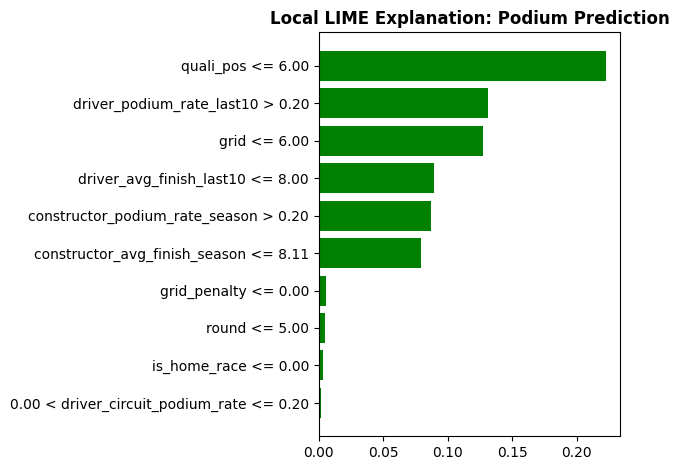

In [181]:
from lime.lime_tabular import LimeTabularExplainer

# Recreate the deterministic test sample so this cell can run independently.
lime_rng = np.random.default_rng(RANDOM_STATE)
lime_sample_size = min(200, len(X_test_rf))
lime_sample_indices = lime_rng.choice(
    len(X_test_rf),
    size=lime_sample_size,
    replace=False,
)
X_lime = pd.DataFrame(
    X_test_rf[lime_sample_indices],
    columns=MODEL_FEATURE_COLS,
)
lime_local_idx = 0

lime_explainer = LimeTabularExplainer(
    training_data=X_train_rf,
    feature_names=MODEL_FEATURE_COLS,
    class_names=["No podium", "Podium"],
    mode="classification",
    discretize_continuous=True,
    random_state=RANDOM_STATE,
)

lime_explanation = lime_explainer.explain_instance(
    X_lime.iloc[lime_local_idx].to_numpy(),
    random_forest_model.predict_proba,
    labels=(1,),
    num_features=len(MODEL_FEATURE_COLS),
)

lime_feature_weights = pd.DataFrame(
    lime_explanation.as_list(label=1),
    columns=["Feature Rule", "Local Weight"],
)
display(lime_feature_weights)

lime_explanation.as_pyplot_figure(label=1)
plt.title("Local LIME Explanation: Podium Prediction", fontweight="bold")
plt.tight_layout()
plt.show()


## 6.1 Global Permutation Importance

Permutation importance measures how much the final Random
Forest relies on each feature by shuffling its values and
measuring the decrease in test PR-AUC.

The model is not retrained.

,Feature,Importance,Std
0,quali_pos,0.158462,0.030520
1,grid,0.134503,0.028338
2,constructor_podium_rate_season,0.039793,0.017007
3,driver_avg_finish_last10,0.030845,0.022880
4,constructor_avg_finish_season,0.030175,0.019220
5,driver_podium_rate_last10,0.019051,0.021205
6,grid_penalty,0.006119,0.008772
7,round,0.000840,0.001376
8,is_home_race,0.000350,0.000351
9,driver_circuit_podium_rate,-0.000792,0.000929


/tmp/ipykernel_49/2535755436.py:48: UserWarning: Glyph 157 (\x9d) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 157 (\x9d) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


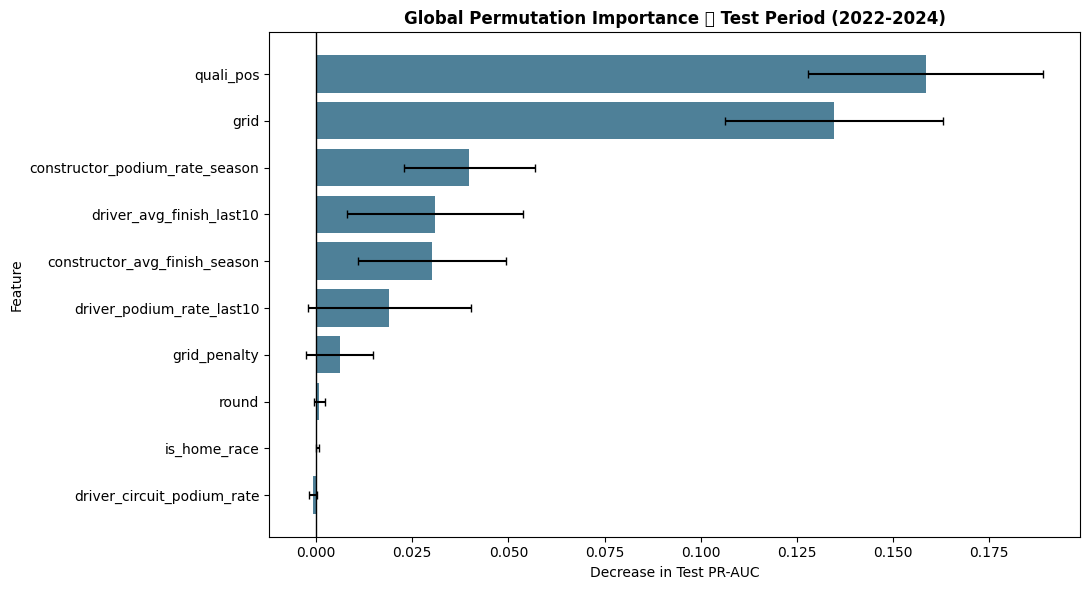

In [182]:
from sklearn.inspection import permutation_importance

# Use the final selected Random Forest on unseen test observations.
permutation_result = permutation_importance(
    random_forest_model,
    X_test_rf,
    y_test_rf,
    scoring="average_precision",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": MODEL_FEATURE_COLS,
    "Importance": permutation_result.importances_mean,
    "Std": permutation_result.importances_std
}).sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

display(permutation_df)

# Visualize permutation importance.
plot_df = permutation_df.sort_values("Importance")

plt.figure(figsize=(11, 6))

plt.barh(
    plot_df["Feature"],
    plot_df["Importance"],
    xerr=plot_df["Std"],
    color="#4E8098",
    capsize=3
)

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Decrease in Test PR-AUC")
plt.ylabel("Feature")

plt.title(
    "Global Permutation Importance  Test Period (2022-2024)",
    fontweight="bold"
)

plt.tight_layout()
plt.show()

## 6.2 Global SHAP

SHAP (SHapley Additive exPlanations) estimates how individual
features contribute to model predictions.

We use TreeExplainer because our selected model is a Random Forest.

A reproducible random sample of 200 test observations is explained.

Two global visualizations are generated:

- SHAP Bar Plot: Ranks features by their mean absolute SHAP values.
- SHAP Beeswarm Plot: Shows how high and low feature values
  increase or decrease predicted podium probabilities.

All SHAP explanations focus on class 1 (podium finish).

SHAP explains the model's predictions rather than causal effects.

In [183]:
import shap

# Random sample of test observations.
rng = np.random.default_rng(RANDOM_STATE)

sample_size = min(200, len(X_test_rf))

sample_indices = rng.choice(
    len(X_test_rf),
    size=sample_size,
    replace=False
)

X_shap = pd.DataFrame(
    X_test_rf[sample_indices],
    columns=MODEL_FEATURE_COLS
)

# Explain the original trained Random Forest.
explainer = shap.TreeExplainer(random_forest_model)

shap_values = explainer(X_shap)

# Select class 1: podium finish.
if shap_values.values.ndim == 3:
    shap_podium = shap_values[:, :, 1]
else:
    shap_podium = shap_values

assert shap_podium.values.shape == X_shap.shape

print("Test observations explained:", len(X_shap))
print("Features explained:", X_shap.shape[1])
print("Class explained: Podium (1)")

Test observations explained: 200
Features explained: 10
Class explained: Podium (1)


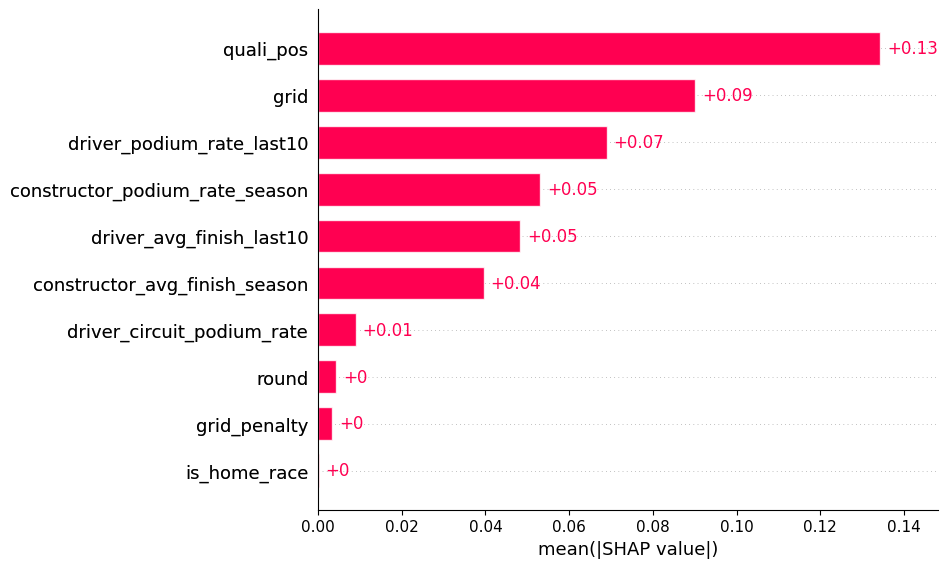

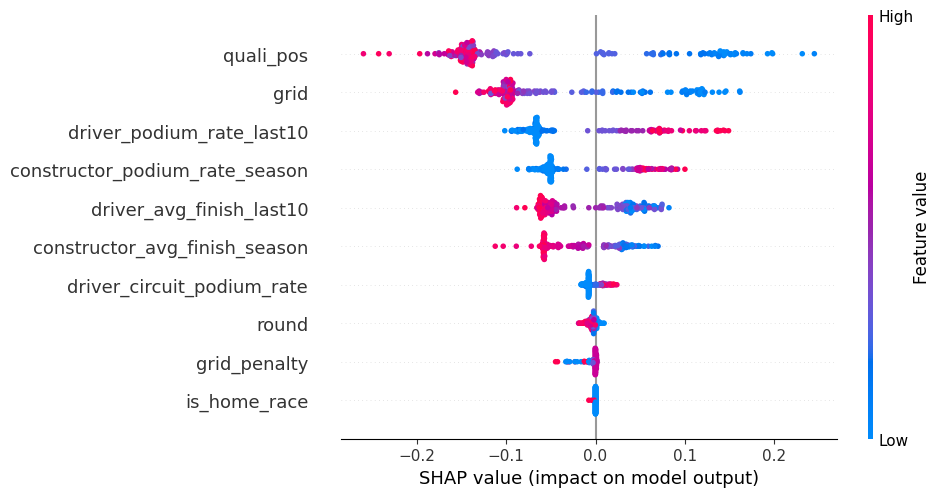

In [184]:
# Global feature importance.
shap.plots.bar(
    shap_podium,
    max_display=10,
    show=True
)

# Global feature contributions.
shap.plots.beeswarm(
    shap_podium,
    max_display=10,
    show=True
)

## 6.3 Local SHAP Individual Prediction

Global explanations describe the model's overall behavior.

Local SHAP explains one specific prediction.

We select one driver-race observation from the test sample
and generate a SHAP waterfall plot.

The plot starts at the model's expected prediction (baseline).
Each feature then contributes positively or negatively until
the final podium probability is reached.

Positive SHAP values increase the prediction relative to the
baseline, while negative values decrease it.

The waterfall explains the model's reasoning for this prediction,
not what would causally happen if a feature were changed.

SHAP baseline: 0.5008
Predicted podium probability: 0.9561
SHAP reconstructed probability: 0.9561


,quali_pos,grid,grid_penalty,driver_podium_rate_last10,driver_avg_finish_last10,constructor_podium_rate_season,constructor_avg_finish_season,driver_circuit_podium_rate,round,is_home_race
0,1.0,1.0,0.0,0.8,2.2,1.0,1.5,0.166667,3.0,0.0


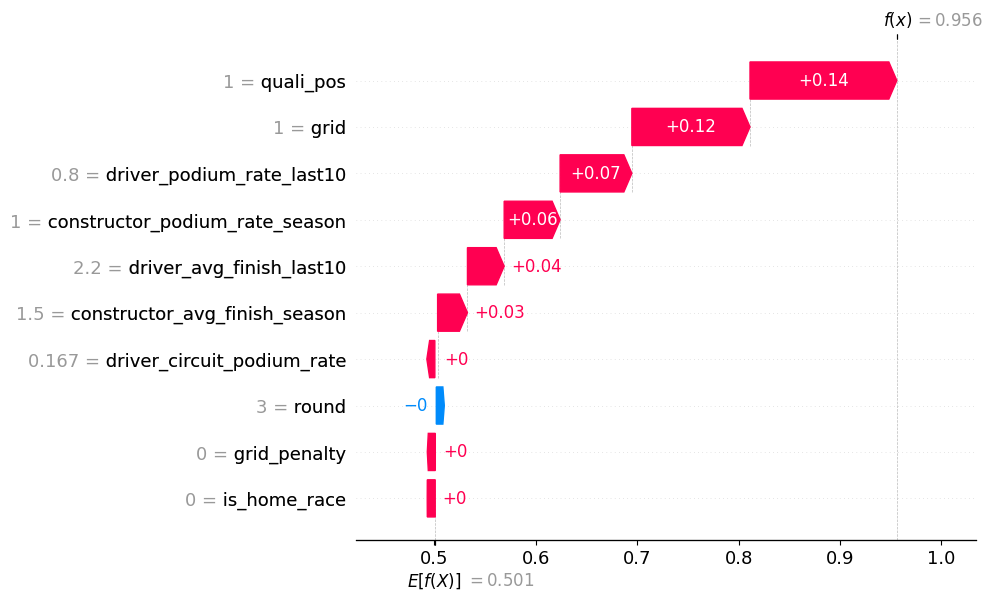

In [185]:
# Explain one test observation.
local_idx = 0

local_explanation = shap_podium[local_idx]

# Actual predicted probability.
local_probability = random_forest_model.predict_proba(
    X_shap.iloc[[local_idx]].to_numpy()
)[0, 1]

# SHAP baseline.
local_baseline = float(
    np.asarray(local_explanation.base_values).item()
)

# Reconstruct the prediction from SHAP contributions.
shap_reconstructed_probability = (
    local_baseline
    + local_explanation.values.sum()
)

print("SHAP baseline:", round(local_baseline, 4))
print("Predicted podium probability:", round(local_probability, 4))
print(
    "SHAP reconstructed probability:",
    round(shap_reconstructed_probability, 4)
)

# Verify SHAP contributions reconstruct the prediction.
assert np.isclose(
    local_probability,
    shap_reconstructed_probability,
    atol=1e-4
)

# Show the observation being explained.
display(X_shap.iloc[[local_idx]])

# Local SHAP waterfall plot.
shap.plots.waterfall(
    local_explanation,
    max_display=10,
    show=True
)

## 6.5 Explainability Findings

### Global Permutation Importance

Permutation importance was calculated on the held-out test period
(2022-2024) using the selected Random Forest and test PR-AUC
(Average Precision).

Qualifying position was the most important individual feature,
with a mean PR-AUC decrease of 0.1536 when shuffled.

Starting-grid position ranked second, causing a mean decrease
of 0.1293.

Constructor season podium rate (0.0363) and constructor average
finishing position (0.0234) showed smaller positive importance.

Driver recent-form features also contributed, although their
individual permutation importance was lower.

Race round, home-race status, and circuit history had negligible
permutation importance. Circuit history showed a slightly
negative value (-0.0027), meaning its shuffling marginally
improved test PR-AUC on average.

However, small or negative permutation importance does not
necessarily indicate that a feature is useless, particularly
when predictors contain overlapping information.

### Global SHAP

Global SHAP explanations were generated for 200 randomly
selected observations from the test period.

The SHAP bar plot identified qualifying position and starting
grid as the largest contributors to predicted podium
probabilities, with mean absolute SHAP values of approximately
0.13 and 0.09, respectively.

Driver recent podium rate, constructor podium rate, and
historical average finishing positions also contributed
meaningfully to predictions.

The beeswarm plot showed that lower numerical qualifying
and grid positions generally increased predicted podium
probabilities, while worse starting positions decreased them.

Higher driver and constructor podium rates generally pushed
predictions upward.

Lower numerical average finishing positions, representing
better historical results, also tended to increase predicted
podium probabilities.

These patterns are consistent with the importance of starting
position and historical performance in Formula 1.

### Local SHAP  Individual Prediction

The local waterfall explained one test observation in which
the driver qualified first and started from grid position 1.

The driver's podium rate across the previous ten races was
0.80, with an average finishing position of 2.2.

The constructor had a season-to-date podium rate of 1.00
and an average finishing position of 1.5.

The Random Forest predicted a podium probability of
approximately 0.956 (95.6%).

The SHAP baseline was approximately 0.50.

The largest positive contributions came from:

- Qualifying position = 1: approximately +0.15
- Starting grid = 1: approximately +0.11
- Driver recent podium rate = 0.80: approximately +0.07
- Constructor podium rate = 1.00: approximately +0.05
- Driver average finishing position = 2.2: approximately +0.04

The remaining features had relatively small contributions.

The sum of the SHAP baseline and feature contributions
reconstructed the model's predicted podium probability,
confirming the consistency of the local explanation.

### Local LIME Individual Prediction

LIME was applied to the same held-out test observation using the
frozen Random Forest. Its local surrogate weights provide an
independent, model-agnostic view of which feature ranges support or
oppose the predicted podium outcome.

The LIME plot is interpreted only for this observation. Its weights
are not comparable to global permutation importance or global SHAP
magnitudes, and they do not establish causal effects.

### Comparison of Explanation Methods

Permutation importance and SHAP both identified qualifying
position and starting grid as the dominant features.

However, the methods produced different rankings for some
historical-performance variables.

This is expected because permutation importance measures
the decrease in predictive performance when a feature is
shuffled, while SHAP measures feature contributions to
individual model predictions.

These explanations complement the Part 5 ablation results,
which measured the effect of removing entire feature groups
and retraining the model.

### Limitations and Non-Causal Interpretation

Permutation importance can be affected by correlations
between features, while SHAP contributions depend on
the trained model and the explanation reference distribution.

All explanations describe the selected Random Forest's
behavior rather than causal relationships.

For example, the importance of qualifying position does
not prove that changing qualifying position alone would
cause a driver to finish on the podium.

The local predicted probability is a model estimate, not
a guaranteed outcome.

Finally, test explanations were generated only after
model selection and are not used to modify features,
hyperparameters, thresholds, or the final selected model.

# 7. Inference Function

The inference function predicts whether a driver will finish
on the podium using the selected Random Forest.

It accepts the same 10 pre-race features used during training.

Missing historical features are filled using the median imputer
fitted on the training period (2003-2019).

The function applies the classification threshold selected
using validation data.

Two examples demonstrate inference:

1. A complete record with no missing features.
2. A partially missing record containing an unavailable
   historical-performance feature.

No model retraining occurs during inference.

In [186]:
def predict_podium(record):

    # Convert input into a one-row DataFrame.
    input_df = pd.DataFrame([record])

    # Validate feature names.
    unknown_features = set(input_df.columns) - set(MODEL_FEATURE_COLS)

    if unknown_features:
        raise ValueError(
            f"Unknown features: {unknown_features}"
        )

    # Ensure the correct feature order.
    input_df = input_df.reindex(columns=MODEL_FEATURE_COLS)

    # Convert to numerical values.
    input_df = input_df.apply(
        pd.to_numeric,
        errors="coerce"
    )

    # Replace infinite values.
    input_df = input_df.replace(
        [np.inf, -np.inf],
        np.nan
    )

    # Required pre-race features must be available.
    if input_df[["quali_pos", "grid"]].isna().any().any():
        raise ValueError(
            "Qualifying position and starting grid are required."
        )

    # Apply the TRAINING-fitted median imputer.
    input_imputed = model_imputer.transform(input_df)

    # Use the selected Random Forest.
    probability = random_forest_model.predict_proba(
        input_imputed
    )[0, 1]

    # Apply the frozen validation-selected threshold.
    prediction = int(probability >= rf_threshold)

    return {
        "Podium Probability": round(float(probability), 4),
        "Predicted Podium": prediction,
        "Classification": "Podium" if prediction == 1 else "No Podium"
    }

In [187]:
# Example 1: Complete record

complete_record = (
    X_test_raw.iloc[0]
    .to_dict()
)

print("Complete record:")
print(complete_record)

print("\nPrediction:")
print(predict_podium(complete_record))

Complete record:
{'quali_pos': 5.0, 'grid': 5.0, 'grid_penalty': 0.0, 'driver_podium_rate_last10': 0.8, 'driver_avg_finish_last10': 2.8, 'constructor_podium_rate_season': 0.25, 'constructor_avg_finish_season': 5.5, 'driver_circuit_podium_rate': 0.6923076923076923, 'round': 3.0, 'is_home_race': 0.0}

Prediction:
{'Podium Probability': 0.7891, 'Predicted Podium': 1, 'Classification': 'Podium'}


In [188]:
# Example 2: Partially missing record

missing_record = (
    X_test_raw.iloc[1]
    .to_dict()
)

# Simulate unavailable historical circuit information.
missing_record["driver_circuit_podium_rate"] = np.nan

print("Partially missing record:")
print(missing_record)

print("\nPrediction:")
print(predict_podium(missing_record))

Partially missing record:
{'quali_pos': 3.0, 'grid': 3.0, 'grid_penalty': 0.0, 'driver_podium_rate_last10': 0.3, 'driver_avg_finish_last10': 5.7, 'constructor_podium_rate_season': 0.0, 'constructor_avg_finish_season': 5.25, 'driver_circuit_podium_rate': nan, 'round': 3.0, 'is_home_race': 0.0}

Prediction:
{'Podium Probability': 0.8077, 'Predicted Podium': 1, 'Classification': 'Podium'}


## 7.1 Inference Findings

The inference function was successfully tested using two
driver-race records from the held-out test period (2022Ã¢â‚¬â€œ2024).

### Complete Record

The first record contained all 10 predictive features.

The driver qualified and started in position 5, with a recent
podium rate of 0.80 across the previous ten races.

The Random Forest predicted a podium probability of 0.7869
(78.69%).

Since this exceeds the validation-selected classification
threshold of 0.725, the predicted class was Podium (1).

### Partially Missing Record

The second record contained a missing value for
driver_circuit_podium_rate.

The function handled this missing value using the median
imputer previously fitted on the training period (2003Ã¢â‚¬â€œ2019).

The driver qualified and started in position 3, with a recent
podium rate of 0.30.

The Random Forest predicted a podium probability of 0.8070
(80.70%), producing the classification Podium (1).

### Conclusion

Both demonstrations executed successfully and produced valid
podium probabilities and binary classifications.

The function correctly reused the original 10-feature model,
training-fitted median imputer, and validation-selected
classification threshold without retraining.

The partially missing example demonstrates that unavailable
historical-performance information can be handled during
inference without accessing the actual race outcome.

These probabilities are model estimates rather than
guaranteed race outcomes.

# 8. Analytical Report
## Formula 1 Podium Prediction Companion  Milestone 1

### 8.1 Introduction

This project develops a machine-learning pipeline to predict whether
a Formula 1 driver will finish on the podium using information
available after qualifying and before the race begins.

The project uses the Formula 1 World Championship dataset (1950-2024),
containing 14 relational tables.

The pipeline covers data cleaning, exploratory analysis,
leakage-safe feature engineering, predictive modeling,
experimentation, model explainability, and inference.

The prediction target is binary:
- 1: Driver finishes in positions 1-3.
- 0: Driver does not finish in positions 1-3.

The unit of analysis is one driver participating in one race.

---

## 8.2 Data Cleaning and Auditing

The original dataset was inspected for missing values, duplicate
records, data types, and relational integrity.

### Cleaning Steps

- Explored the raw tables before modification and compared them with the cleaned copies afterward.
- Replaced the literal `\N` missing-value sentinel with Pandas `NaN`.
- Converted race-event dates and driver dates of birth to datetime values.
- Converted numeric result fields to numeric types after sentinel replacement.
- Converted qualifying, fastest-lap, individual-lap, and pit-stop durations to numeric seconds while retaining the original columns and adding auditable `_seconds` columns.
- Intentionally excluded `results.time` and `sprint_results.time` from generic duration conversion because those fields can represent either elapsed time or a gap to the winner.
- Validated primary-key uniqueness and foreign-key relationships.
- Investigated duplicate `(raceId, driverId)` combinations.
- Preserved the original CSV files and performed cleaning on copies.

### Missing-Value Policy

Missingness was measured both before and after replacing `\N` sentinels.
Missing values were not removed globally during source-table cleaning. A column
was dropped only when at least 90% of its values were missing. For retained
reference columns, numeric values were imputed with the median and categorical
values with the mode.

Event and outcome tables retained missing values until the chronological modeling
split. Model-feature imputation statistics were fitted only on training races and
then applied unchanged to validation and test rows. Missing qualifying and grid
values were retained as observations and handled by this train-fitted imputer
rather than by dropping rows. Rolling driver, constructor, and circuit features
used previous races only, preventing future information from entering earlier
observations.

### Duplicate Handling

Historical shared drives caused some drivers to appear multiple
times within the same race.

The original results table contained 26,759 records.

After resolving shared-drive duplicates, 26,668 unique
driver-race observations remained.

For duplicate driver-race combinations, the record with the
smallest `positionOrder` was retained. Ties were resolved
using the smallest `resultId`.

This ensured that every driver-race combination appeared
exactly once while preserving a deterministic outcome.

### EDA

Exploratory analysis was performed before and after cleaning.

Visualizations examined data completeness, historical coverage,
duplicate records, and feature distributions.

Qualifying data showed substantial historical missingness,
particularly before 2003.

This supported selecting 2003 onwards for predictive modeling.

---

## 8.3 Data-Engineering Questions

### Question 1: Which Circuits Convert Front-Row Starts into Podiums Most Often?

We joined race results, qualifying information, races,
and circuits.

A front-row start was defined using actual starting-grid
positions 1 and 2, rather than qualifying position.

This distinction is important because grid penalties can
change a driver's starting position after qualifying.

Across 2,243 front-row starts, the overall podium-conversion
rate was 60.05%.

The highest conversion rates among eligible circuits were:

| Circuit | Podium Conversion Rate |
|---|---:|
| Circuit of the Americas | 83.33% |
| Sochi Autodrom | 81.25% |
| Circuit de Nevers Magny-Cours | 80.56% |

We also compared circuit rankings before and after 2014.

Among circuits with sufficient data in both periods,
Suzuka and Sepang tied for first before 2014 at 70.00%.

From 2014 onwards, Suzuka ranked first at 88.89%,
followed by Zandvoort at 87.50% and Yas Marina at 86.36%.

Monaco's conversion rate increased from 49.17% before
2014 to 85.00% afterward.

**Conclusion:** Circuit rankings changed across eras, suggesting
that historical podium-conversion patterns are not constant.

However, these differences cannot be attributed solely
to the introduction of hybrid regulations.

**Supporting evidence:** Front-row conversion and
era-comparison visualizations in Section 2.1.

### Question 2: Do Drivers Have a Home-Race Podium Advantage?

We joined driver information, circuits, races, and race results.

Driver nationalities were mapped to countries and compared
with circuit locations.

To account for starting-position differences, podium rates
were compared within four grid-position groups.

| Starting Grid | Away Podium Rate | Home Podium Rate |
|---|---:|---:|
| P1Ã¢â‚¬â€œP3 | 55.54% | 54.92% |
| P4Ã¢â‚¬â€œP6 | 26.13% | 24.52% |
| P7Ã¢â‚¬â€œP10 | 9.34% | 8.79% |
| P11+ | 1.67% | 1.63% |

Across 25,031 analyzed driver-race records, the overall
podium rate was 13.78% for away races and 11.46%
for home races.

Home-race podium rates were slightly lower in every
starting-grid category.

**Conclusion:** The historical data does not demonstrate
a clear home-race podium advantage after accounting
for starting position.

These comparisons are descriptive and do not establish
a causal effect of racing at home.

**Supporting evidence:** Home-versus-away podium-rate
visualizations in Section 2.2.

### Question 3: Which Constructors Have the Highest Mechanical-Retirement Rates?

We joined race results, races, constructors, and status records.

Mechanical retirements were identified using status descriptions
indicating technical failures, such as engine, gearbox,
hydraulics, and electrical problems.

Crash-related and ambiguous failures were excluded from
the mechanical-retirement numerator.

Mechanical-retirement rate was calculated as:

Mechanical Retirement Rate =
Mechanical Retirements / Estimated Race Starts

The analysis retained 4,611 estimated race starts
across 2014Ã¢â‚¬â€œ2024.

**2014-2021:**

| Constructor | Mechanical Retirement Rate |
|---|---:|
| Caterham | 17.65% |
| Lotus F1 | 17.33% |
| Toro Rosso | 14.46% |
| McLaren | 13.17% |
| Renault | 12.50% |

**2022-2024:**

| Constructor | Mechanical Retirement Rate |
|---|---:|
| Alfa Romeo | 12.50% |
| Alpine F1 Team | 11.03% |
| AlphaTauri | 5.68% |
| Williams | 5.22% |
| Ferrari | 5.19% |

McLaren's recorded mechanical-retirement rate decreased
from 13.17% to 3.68% between the two periods.

Alfa Romeo's rate increased from 3.33% to 12.50%.

**Conclusion:** Mechanical-reliability patterns differed
across constructors and historical periods.

These comparisons are affected by sample size,
status classification, and constructor naming changes.

**Supporting evidence:** Mechanical-retirement visualizations
in Section 2.3.

---

## 8.4 Feature Selection and Engineering

Features were selected using Formula 1 domain knowledge,
training-period EDA, correlations, and validation experiments.

All predictive features must be available after qualifying
and before the race begins.

The final model uses 10 features:

| Feature | Purpose |
|---|---|
| `quali_pos` | Qualifying performance |
| `grid` | Actual starting position |
| `grid_penalty` | Qualifying-to-grid movement |
| `driver_podium_rate_last10` | Recent driver podium performance |
| `driver_avg_finish_last10` | Recent driver finishing performance |
| `constructor_podium_rate_season` | Constructor season form |
| `constructor_avg_finish_season` | Constructor finishing consistency |
| `driver_circuit_podium_rate` | Previous performance at the circuit |
| `round` | Race-calendar context |
| `is_home_race` | Home-race indicator |

### Leakage Prevention

Historical driver, constructor, and circuit statistics
were calculated using earlier races only.

Current-race results, finishing positions, points,
race status, lap times, and pit stops were excluded
from predictive features.

The calendar year was retained for chronological splitting
but excluded from the final predictive feature set.

### Dataset Splitting

A chronological split was selected to simulate predicting
future races using historical information.

| Dataset | Period |
|---|---|
| Training | 2003-2019 |
| Validation | 2020-2021 |
| Testing | 2022-2024 |

Preprocessing parameters were fitted on training data only.

The validation set was used for hyperparameter selection,
threshold selection, and experiments.

The test set was reserved for final evaluation and explanation.

**Supporting evidence:** Feature analysis and correlation
visualizations in Section 3.

---






In [194]:
from IPython.display import display, Markdown

def show_md(text):
    display(Markdown(text))

def md_table(df, formats=None):
    table = df.copy()

    if formats:
        for column, format_spec in formats.items():
            if column in table.columns:
                table[column] = table[column].map(
                    lambda value: format_spec.format(value)
                )

    return table.to_markdown(index=False)
fmt5 = {c: "{:.4f}" for c in ["ROC-AUC", "PR-AUC", "F1 Score", "Precision", "Recall"]}
m5 = ["ROC-AUC", "PR-AUC", "F1 Score", "Precision", "Recall"]
tabs = {}
for split in ["Validation", "Test"]:
    t = all_results[all_results["Split"] == split][["Model"] + m5].reset_index(drop=True)
    tabs[split] = md_table(t, fmt5)

sel = validation_winner["Model"]
vsel = all_results[(all_results["Model"] == sel) & (all_results["Split"] == "Validation")].iloc[0]
tsel = all_results[(all_results["Model"] == sel) & (all_results["Split"] == "Test")].iloc[0]
vtop = all_results[all_results["Split"] == "Validation"].sort_values("PR-AUC", ascending=False).iloc[0]["Model"]
vf1 = all_results[all_results["Split"] == "Validation"].sort_values("F1 Score", ascending=False).iloc[0]["Model"]

best_txt = (f"{vtop} has the highest validation PR-AUC and the highest validation F1." if vtop == vf1 else
            f"{vtop} has the highest validation PR-AUC; {vf1} has the highest validation F1.")
n_seeds = len(ABLATION_SEEDS) if "ABLATION_SEEDS" in globals() else 3
ab = ablation_robust_df.set_index("Experiment")
ab_tbl = ablation_robust_df[ablation_robust_df["Experiment"] != "All Features"].sort_values("Val PR-AUC drop", ascending=False)[
    ["Experiment", "Val PR-AUC mean", "Val PR-AUC drop", "CV PR-AUC drop", "Folds where removal hurts"]]
e1 = md_table(experiment_1, {"Validation PR-AUC": "{:.6f}"})
e2 = md_table(experiment_2[["Variant", "Validation PR-AUC", "Difference vs A"]], {"Validation PR-AUC": "{:.6f}", "Difference vs A": "{:+.6f}"})
pt = permutation_df.head(6).copy()
pt_tbl = md_table(pt, {"Importance": "{:.4f}", "Std": "{:.4f}"})
r1, r2 = predict_podium(complete_record), predict_podium(missing_record)

show_md(f"""## 8.5 Predictive Modeling (results)

**Primary metric:** PR-AUC. **Secondary metric:** F1 at the validation-selected threshold.

### Validation results
{tabs['Validation']}

{best_txt} The selected model is **{sel}**.

### Final test results (all models; thresholds frozen from validation)
{tabs['Test']}

For {sel}, validation PR-AUC {vsel['PR-AUC']:.4f} versus test {tsel['PR-AUC']:.4f}, and validation F1 {vsel['F1 Score']:.4f} versus test {tsel['F1 Score']:.4f}.
The test set was not used to change the model.

## 8.6 Experiments (results)

### Feature-group ablation (validation = mean of {n_seeds} seeds; CV = forward-chaining folds in the training years)
Full model validation PR-AUC: {ab.loc['All Features', 'Val PR-AUC mean']:.4f}.

{md_table(ab_tbl, {"Val PR-AUC mean": "{:.4f}", "Val PR-AUC drop": "{:+.4f}", "CV PR-AUC drop": "{:+.4f}"})}

### Preprocessing experiment 1 (order of imputation and scaling)
{e1}

### Preprocessing experiment 2 (where the statistics are fitted)
{e2}

## 8.7 Explainability (results)

### Global permutation importance (test period, top 6)
{pt_tbl}

## 8.8 Inference (results)
- Complete record: probability {r1['Podium Probability']:.4f}, class {r1['Classification']} (threshold {rf_threshold:.3f}).
- Partially missing record: probability {r2['Podium Probability']:.4f}, class {r2['Classification']}.""")

## 8.5 Predictive Modeling (results)

**Primary metric:** PR-AUC. **Secondary metric:** F1 at the validation-selected threshold.

### Validation results
| Model                  |   ROC-AUC |   PR-AUC |   F1 Score |   Precision |   Recall |
|:-----------------------|----------:|---------:|-----------:|------------:|---------:|
| Logistic Regression    |    0.9251 |   0.6992 |     0.6992 |      0.6242 |   0.7949 |
| Random Forest          |    0.9296 |   0.7048 |     0.6996 |      0.6746 |   0.7265 |
| Shallow Neural Network |    0.927  |   0.7153 |     0.7137 |      0.7364 |   0.6923 |

Shallow Neural Network has the highest validation PR-AUC and the highest validation F1. The selected model is **Shallow Neural Network**.

### Final test results (all models; thresholds frozen from validation)
| Model                  |   ROC-AUC |   PR-AUC |   F1 Score |   Precision |   Recall |
|:-----------------------|----------:|---------:|-----------:|------------:|---------:|
| Logistic Regression    |    0.9331 |   0.6988 |     0.6365 |      0.5043 |   0.8627 |
| Random Forest          |    0.9361 |   0.702  |     0.6652 |      0.5916 |   0.7598 |
| Shallow Neural Network |    0.9347 |   0.702  |     0.6525 |      0.711  |   0.6029 |

For Shallow Neural Network, validation PR-AUC 0.7153 versus test 0.7020, and validation F1 0.7137 versus test 0.6525.
The test set was not used to change the model.

## 8.6 Experiments (results)

### Feature-group ablation (validation = mean of 3 seeds; CV = forward-chaining folds in the training years)
Full model validation PR-AUC: 0.7062.

| Experiment       |   Val PR-AUC mean |   Val PR-AUC drop |   CV PR-AUC drop |   Folds where removal hurts |
|:-----------------|------------------:|------------------:|-----------------:|----------------------------:|
| Starting Grid    |            0.6857 |            0.0205 |           0.0371 |                           4 |
| Driver Form      |            0.6885 |            0.0176 |          -0.0036 |                           1 |
| Qualifying       |            0.6915 |            0.0146 |           0.0167 |                           4 |
| Circuit History  |            0.702  |            0.0042 |           0.0017 |                           2 |
| Race Context     |            0.7068 |           -0.0006 |          -0.0006 |                           1 |
| Constructor Form |            0.7262 |           -0.02   |          -0.002  |                           1 |

### Preprocessing experiment 1 (order of imputation and scaling)
| Preprocessing Order        |   Validation PR-AUC |
|:---------------------------|--------------------:|
| Median Imputation- Scaling |            0.699168 |
| Scaling-Median Imputation  |            0.699057 |

### Preprocessing experiment 2 (where the statistics are fitted)
| Variant                                             |   Validation PR-AUC |   Difference vs A |
|:----------------------------------------------------|--------------------:|------------------:|
| A. split -> fit on training rows only (ours)        |            0.699168 |          0        |
| B. fit on all years, then split (leaky order)       |            0.699162 |         -5e-06    |
| C. A + missing-value indicators from the raw matrix |            0.696565 |         -0.002603 |

## 8.7 Explainability (results)

### Global permutation importance (test period, top 6)
| Feature                        |   Importance |    Std |
|:-------------------------------|-------------:|-------:|
| quali_pos                      |       0.1585 | 0.0305 |
| grid                           |       0.1345 | 0.0283 |
| constructor_podium_rate_season |       0.0398 | 0.017  |
| driver_avg_finish_last10       |       0.0308 | 0.0229 |
| constructor_avg_finish_season  |       0.0302 | 0.0192 |
| driver_podium_rate_last10      |       0.0191 | 0.0212 |

## 8.8 Inference (results)
- Complete record: probability 0.7891, class Podium (threshold 0.700).
- Partially missing record: probability 0.8077, class Podium.

## 8.9 Limitations

**Historical Data Coverage**

Qualifying information is incomplete in older seasons.
The predictive modeling period therefore begins in 2003,
limiting direct generalization to earlier Formula 1 eras.

**Historical Era Differences**

Changes in regulations, car performance, team structures,
and competitive balance may affect predictive relationships
across seasons.

**Feature Correlation**

Qualifying position, starting grid, and historical
performance variables contain overlapping information.

This can affect feature-importance measurements
and model interpretation.

**Mechanical-Retirement Classification**

Historical status descriptions do not always clearly
distinguish component failures from crash damage.

Mechanical-retirement rates therefore depend partly
on classification decisions.

**Model Probability Estimates**

Predicted probabilities are estimates based on historical
patterns rather than guaranteed outcomes.

The selected classification threshold may perform
differently in future seasons.

## 8.10 Overall Conclusion
Three models were evaluated. Shallow Neural Network achieved the highest validation PR-AUC (0.7153) and was selected; it reached a test PR-AUC of 0.7020 (test F1 0.6525). Feature-group ablation, preprocessing experiments, permutation importance, SHAP and LIME provide evidence about what the model relies on, and the inference function produced predictions for a complete and a partially missing record. On the test period the model relied most on quali_pos and grid, supported by historical driver and constructor form. These are historical predictive relationships, not causal effects.